
# Ethereum & Bitcoin – Machine Learning Analysis
### Grupparbete: The Overfitters

## Projektbeskrivning

Syftet med projektet är att undersöka om maskininlärning
kan identifiera samband mellan Ethereum (ETH), Bitcoin (BTC)
och andra marknadsfaktorer.

Vi ska analysera historiska data och undersöka om olika
variabler kan användas för att förutsäga framtida
prisrörelser och avkastning för Ethereum.

## Projektets mål

1. Samla in historiska data för ETH och BTC.
2. Integrera CSV-filer med data från API.
3. Genomföra datarensning och explorativ dataanalys (EDA).
4. Undersöka korrelationer mellan olika variabler.
5. Skapa nya variabler med Feature Engineering.
6. Träna och jämföra flera Machine Learning-modeller.
7. Utvärdera modellerna genom Backtesting.
8. Undersöka framtida avkastning över 6 och 12 månader.
9. Presentera resultat i en interaktiv Streamlit-app.

## Datakällor

- Coin Metrics – historiska kryptodata och API.
- Ethereum (ETH) och Bitcoin (BTC).
- Ytterligare marknadsindikatorer vid behov.

## Metoder

- Python och Pandas
- Exploratory Data Analysis (EDA)
- Correlation Analysis
- Moving Averages
- Feature Engineering
- Logistic Regression
- Model Evaluation
- Backtesting
- Streamlit

## V1 – Datainsamling och förberedelse

I första delen samlar vi in historiska data för
Ethereum och Bitcoin. Därefter undersöker vi
datakvalitet, saknade värden och möjliga samband.



### Steg 2 – Installation av bibliotek

Vi installerar de Python-bibliotek som behövs för
datainsamling, databehandling, statistisk analys,
visualisering och maskininlärning.

Biblioteken kommer att användas för att hämta
historiska data, analysera samband och bygga
prediktionsmodeller.


In [62]:

%pip install pandas numpy matplotlib seaborn requests scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import sklearn

print("Alla bibliotek fungerar korrekt!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)


Alla bibliotek fungerar korrekt!
Pandas version: 3.0.1
Scikit-learn version: 1.9.1



### Steg 3 – Import av Python-bibliotek

I detta steg importerar vi biblioteken som behövs
för projektets dataanalys och maskininlärning.

- **Pandas:** Hantering och bearbetning av dataset.
- **NumPy:** Matematiska och statistiska beräkningar.
- **Matplotlib:** Visualisering av data.
- **Seaborn:** Statistiska diagram.
- **Requests:** Hämtning av data från API.
- **Scikit-learn:** Träning och utvärdering av ML-modeller.

Vi kontrollerar även att biblioteken kan importeras
utan fel och visar versionerna för Pandas och Scikit-learn.



### Steg 4 – Datainsamling från Coin Metrics API

Vi använder Coin Metrics Community API för att hämta
historiska prisdata för Ethereum (ETH) och Bitcoin (BTC).

Syftet är att bygga en gemensam dataset där båda
kryptovalutorna kan analyseras och jämföras.

Vi börjar med att testa API-anslutningen och hämta
dagliga priser för en kortare period.

Data kommer senare att användas för att undersöka
korrelationer, beräkna tekniska indikatorer och
träna maskininlärningsmodeller.


In [64]:

# Steg 4 – Testa Coin Metrics API

url = "https://community-api.coinmetrics.io/v4/timeseries/asset-metrics"

params = {
    "assets": "btc,eth",
    "metrics": "PriceUSD",
    "frequency": "1d",
    "start_time": "2024-01-01",
    "end_time": "2024-01-10",
    "page_size": 100
}

response = requests.get(url, params=params, timeout=30)

# Kontrollera att API-anropet lyckades
response.raise_for_status()

# Omvandla JSON till DataFrame
data = response.json()["data"]
df_crypto = pd.DataFrame(data)

# Visa resultat
print("Antal rader:", len(df_crypto))
display(df_crypto.head(10))


Antal rader: 20


,asset,time,PriceUSD
0,btc,2024-01-01T00:00:00.000000000Z,44049.4735534775
1,btc,2024-01-02T00:00:00.000000000Z,44941.160493571
2,btc,2024-01-03T00:00:00.000000000Z,42773.6515423729
3,btc,2024-01-04T00:00:00.000000000Z,44250.7452670953
4,btc,2024-01-05T00:00:00.000000000Z,44146.3222022209
5,btc,2024-01-06T00:00:00.000000000Z,43917.9798147282
6,btc,2024-01-07T00:00:00.000000000Z,43844.195949737
7,btc,2024-01-08T00:00:00.000000000Z,46981.3242995324
8,btc,2024-01-09T00:00:00.000000000Z,46084.005795149
9,btc,2024-01-10T00:00:00.000000000Z,46818.1592764465



### Steg 5 – Kontroll av datakvalitet

API-anropet lyckades och vi hämtade historiska
prisdata för Ethereum och Bitcoin.

I detta steg kontrollerar vi:

- Antal observationer per kryptovaluta.
- Datatyper för datum och priser.
- Om det finns saknade värden.
- Att prisvariablerna är numeriska.

Detta är viktigt för att senare kunna genomföra
statistiska analyser och träna ML-modeller.


In [65]:

# Gör en kopia av vår rådata
df_crypto_clean = df_crypto.copy()

# Konvertera datum till datetime
df_crypto_clean["time"] = pd.to_datetime(
    df_crypto_clean["time"],
    utc=True
)

# Konvertera priser till numeriska värden
df_crypto_clean["PriceUSD"] = pd.to_numeric(
    df_crypto_clean["PriceUSD"],
    errors="coerce"
)

# Kontrollera antal rader för BTC och ETH
print("Antal observationer per kryptovaluta:")
print(df_crypto_clean["asset"].value_counts())

# Kontrollera saknade värden
print("\nSaknade värden:")
print(df_crypto_clean.isnull().sum())

# Kontrollera datatyper
print("\nDatatyper:")
print(df_crypto_clean.dtypes)

# Visa de sista 10 raderna (Ethereum)
display(df_crypto_clean.tail(10))


Antal observationer per kryptovaluta:
asset
btc    10
eth    10
Name: count, dtype: int64

Saknade värden:
asset       0
time        0
PriceUSD    0
dtype: int64

Datatyper:
asset                       str
time        datetime64[ns, UTC]
PriceUSD                float64
dtype: object


,asset,time,PriceUSD
10,eth,2024-01-01 00:00:00+00:00,2347.438261
11,eth,2024-01-02 00:00:00+00:00,2357.630961
12,eth,2024-01-03 00:00:00+00:00,2207.343350
13,eth,2024-01-04 00:00:00+00:00,2272.180091
14,eth,2024-01-05 00:00:00+00:00,2267.643388
15,eth,2024-01-06 00:00:00+00:00,2238.933940
16,eth,2024-01-07 00:00:00+00:00,2218.468663
17,eth,2024-01-08 00:00:00+00:00,2332.303092
18,eth,2024-01-09 00:00:00+00:00,2339.661537
19,eth,2024-01-10 00:00:00+00:00,2590.845710



### Steg 6 – Kombinera Ethereum och Bitcoin

Vi omstrukturerar vår dataset så att Ethereum och
Bitcoin får varsin kolumn.

Med hjälp av Pandas pivot() omvandlar vi data
från långt format (long format) till brett format
(wide format).

Detta gör det enklare att jämföra prisutvecklingen
för båda kryptovalutorna och genomföra
korrelationsanalyser.

Vi kontrollerar även att inga värden saknas
efter omstruktureringen.


In [66]:

# Steg 6 – Kombinera ETH och BTC

# Omvandla från långt till brett format
df_prices = df_crypto_clean.pivot(
    index="time",
    columns="asset",
    values="PriceUSD"
)

# Byt namn på kolumnerna
df_prices = df_prices.rename(columns={
    "btc": "BTC_Price",
    "eth": "ETH_Price"
})

# Gör datum till en vanlig kolumn
df_prices = df_prices.reset_index()

# Kontrollera resultatet
print("Antal rader och kolumner:", df_prices.shape)

print("\nSaknade värden:")
print(df_prices.isnull().sum())

display(df_prices.head(10))


Antal rader och kolumner: (10, 3)

Saknade värden:
asset
time         0
BTC_Price    0
ETH_Price    0
dtype: int64


asset,time,BTC_Price,ETH_Price
0,2024-01-01 00:00:00+00:00,44049.473553,2347.438261
1,2024-01-02 00:00:00+00:00,44941.160494,2357.630961
2,2024-01-03 00:00:00+00:00,42773.651542,2207.343350
3,2024-01-04 00:00:00+00:00,44250.745267,2272.180091
4,2024-01-05 00:00:00+00:00,44146.322202,2267.643388
5,2024-01-06 00:00:00+00:00,43917.979815,2238.933940
6,2024-01-07 00:00:00+00:00,43844.195950,2218.468663
7,2024-01-08 00:00:00+00:00,46981.324300,2332.303092
8,2024-01-09 00:00:00+00:00,46084.005795,2339.661537
9,2024-01-10 00:00:00+00:00,46818.159276,2590.845710



### Steg 7 – Historisk datainsamling (2017–2026)

Efter att ha testat API-anslutningen hämtar vi nu en
större historisk dataset för Ethereum och Bitcoin.

Vi använder dagliga prisobservationer från 2017 fram
till november 2026.

Syftet är att samla in tillräckligt mycket data för
statistisk analys, feature engineering och träning
av maskininlärningsmodeller.

Vi hanterar även API-paginering så att alla tillgängliga
observationer inkluderas.

Datasetet sparas som en CSV-fil för fortsatt analys.


In [67]:

# Steg 7 – Hämta historiska priser för ETH och BTC

from pathlib import Path

url = "https://community-api.coinmetrics.io/v4/timeseries/asset-metrics"

params = {
    "assets": "btc,eth",
    "metrics": "PriceUSD",
    "frequency": "1d",
    "start_time": "2015-01-01",
    "end_time": "2026-11-01",
    "page_size": 10000
}

all_data = []
next_url = url

while next_url:
    response = requests.get(
        next_url,
        params=params if next_url == url else None,
        timeout=60
    )
    response.raise_for_status()

    result = response.json()
    all_data.extend(result["data"])

    next_url = result.get("next_page_url")
    params = None

# Skapa DataFrame
df_history = pd.DataFrame(all_data)

# Konvertera datatyper
df_history["time"] = pd.to_datetime(
    df_history["time"], utc=True
)

df_history["PriceUSD"] = pd.to_numeric(
    df_history["PriceUSD"], errors="coerce"
)

# Kombinera BTC och ETH i separata kolumner
df_history = df_history.pivot(
    index="time",
    columns="asset",
    values="PriceUSD"
).rename(columns={
    "btc": "BTC_Price",
    "eth": "ETH_Price"
}).reset_index()

df_history.columns.name = None
df_history = df_history.sort_values("time")

# Skapa data-mapp och spara CSV
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

df_history.to_csv(
    data_folder / "crypto_historical_prices.csv",
    index=False
)

print("Antal rader och kolumner:", df_history.shape)
print("Första datum:", df_history["time"].min())
print("Sista datum:", df_history["time"].max())

print("\nSaknade värden:")
print(df_history.isna().sum())

display(df_history.head())
display(df_history.tail())


Antal rader och kolumner: (4323, 3)
Första datum: 2015-01-01 00:00:00+00:00
Sista datum: 2026-11-01 00:00:00+00:00

Saknade värden:
time           0
BTC_Price      0
ETH_Price    219
dtype: int64


,time,BTC_Price,ETH_Price
0,2015-01-01 00:00:00+00:00,314.776472,NaN
1,2015-01-02 00:00:00+00:00,315.942732,NaN
2,2015-01-03 00:00:00+00:00,285.647310,NaN
3,2015-01-04 00:00:00+00:00,263.334575,NaN
4,2015-01-05 00:00:00+00:00,275.003852,NaN


,time,BTC_Price,ETH_Price
4318,2026-10-28 00:00:00+00:00,81237.437826,2356.988509
4319,2026-10-29 00:00:00+00:00,78193.426404,2256.031994
4320,2026-10-30 00:00:00+00:00,77109.590747,2240.229980
4321,2026-10-31 00:00:00+00:00,77401.017287,2252.073358
4322,2026-11-01 00:00:00+00:00,78135.080289,2269.988406



### Steg 8 – Undersökning av tillgängliga variabler

För att utveckla vår maskininlärningsmodell behöver
vi fler variabler än enbart historiska priser.

Vi undersöker därför vilka mätvärden Coin Metrics
Community API erbjuder för Ethereum och Bitcoin.

Vi fokuserar på:

- Handelsvolym
- Marknadsvärde
- Antal transaktioner
- Aktiva adresser
- Transaktionsavgifter

Målet är att identifiera användbara variabler
som kan bidra till vår statistiska analys och
framtida ML-modeller.


In [68]:

# Steg 8 – Kontrollera tillgängliga variabler

catalog_url = (
    "https://community-api.coinmetrics.io/"
    "v4/catalog-v2/asset-metrics"
)

response = requests.get(
    catalog_url,
    params={"assets": "btc,eth", "page_size": 10000},
    timeout=60
)

response.raise_for_status()
catalog_data = response.json()["data"]

# Variabler vi är intresserade av
wanted_metrics = [
    "PriceUSD",
    "CapMrktCurUSD",
    "TxCnt",
    "AdrActCnt",
    "FeeTotUSD",
    "TxTfrValAdjUSD"
]

# Kontrollera tillgänglighet för varje kryptovaluta
for asset_data in catalog_data:
    asset = asset_data["asset"]

    print(f"\nTillgängliga variabler för {asset.upper()}:")

    available = {
        metric["metric"]
        for metric in asset_data.get("metrics", [])
    }

    for metric in wanted_metrics:
        status = "Tillgänglig" if metric in available else "Saknas"
        print(f"{metric}: {status}")



Tillgängliga variabler för BTC:
PriceUSD: Tillgänglig
CapMrktCurUSD: Tillgänglig
TxCnt: Tillgänglig
AdrActCnt: Tillgänglig
FeeTotUSD: Saknas
TxTfrValAdjUSD: Saknas

Tillgängliga variabler för ETH:
PriceUSD: Tillgänglig
CapMrktCurUSD: Tillgänglig
TxCnt: Tillgänglig
AdrActCnt: Tillgänglig
FeeTotUSD: Saknas
TxTfrValAdjUSD: Saknas



### Steg 9 – Utökning av dataset med nya variabler

Vi utökar vår historiska dataset med ytterligare
mätvärden från Coin Metrics Community API.

För både Ethereum och Bitcoin hämtar vi:

- Marknadsvärde (CapMrktCurUSD)
- Antal transaktioner (TxCnt)
- Antal aktiva adresser (AdrActCnt)

Syftet är att undersöka om nätverksaktivitet och
marknadsstorlek kan bidra till att förklara
historiska prisrörelser.

Vi kombinerar dessa variabler med tidigare
insamlad prisdata genom datum och kryptovaluta.

Därefter kontrollerar vi datakvaliteten.


In [69]:

# Steg 9 – Hämta ytterligare variabler

metrics = ["CapMrktCurUSD", "TxCnt", "AdrActCnt"]

params = {
    "assets": "btc,eth",
    "metrics": ",".join(metrics),
    "frequency": "1d",
    "start_time": "2017-01-01",
    "end_time": "2026-11-01",
    "page_size": 10000
}

all_metrics = []
next_url = url

while next_url:
    response = requests.get(
        next_url,
        params=params if next_url == url else None,
        timeout=60
    )
    response.raise_for_status()

    result = response.json()
    all_metrics.extend(result["data"])

    next_url = result.get("next_page_url")
    params = None

# Skapa DataFrame
df_metrics = pd.DataFrame(all_metrics)

# Rätt datatyper
df_metrics["time"] = pd.to_datetime(
    df_metrics["time"], utc=True
)

for metric in metrics:
    df_metrics[metric] = pd.to_numeric(
        df_metrics[metric], errors="coerce"
    )

# Skapa en kolumn per variabel och kryptovaluta
df_metrics_wide = df_metrics.pivot(
    index="time",
    columns="asset",
    values=metrics
)

# Byt namn, t.ex. eth_CapMrktCurUSD
df_metrics_wide.columns = [
    f"{asset.upper()}_{metric}"
    for metric, asset in df_metrics_wide.columns
]

df_metrics_wide = df_metrics_wide.reset_index()

# Kombinera med historiska priser
df_full = df_history.merge(
    df_metrics_wide,
    on="time",
    how="left",
    validate="one_to_one"
)

# Spara den utökade datasetet
df_full.to_csv(
    data_folder / "crypto_full_dataset.csv",
    index=False
)

print("Datasetets storlek:", df_full.shape)

print("\nSaknade värden per variabel:")
print(df_full.isna().sum())

display(df_full.head())


Datasetets storlek: (4323, 9)

Saknade värden per variabel:
time                   0
BTC_Price              0
ETH_Price            219
BTC_CapMrktCurUSD    731
ETH_CapMrktCurUSD    731
BTC_TxCnt            731
ETH_TxCnt            731
BTC_AdrActCnt        731
ETH_AdrActCnt        731
dtype: int64


,time,BTC_Price,ETH_Price,BTC_CapMrktCurUSD,ETH_CapMrktCurUSD,BTC_TxCnt,ETH_TxCnt,BTC_AdrActCnt,ETH_AdrActCnt
0,2015-01-01 00:00:00+00:00,314.776472,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-02 00:00:00+00:00,315.942732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-03 00:00:00+00:00,285.647310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-01-04 00:00:00+00:00,263.334575,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-01-05 00:00:00+00:00,275.003852,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### Steg 10 – Feature Engineering

I detta steg skapar vi nya variabler baserade på
historiska prisdata för Ethereum och Bitcoin.

Vi beräknar:

- Daglig procentuell avkastning för ETH och BTC.
- Glidande medelvärde för 7 dagar (MA7).
- Glidande medelvärde för 30 dagar (MA30).

Syftet är att identifiera prisförändringar och
trender som kan användas som förklarande
variabler i våra maskininlärningsmodeller.

Vi använder endast historiska och aktuella
observationer vid beräkningen av indikatorerna.


In [70]:

# Steg 10 – Feature Engineering

# Skapa en kopia av vår dataset
df_features = df_full.copy()

# Sortera efter datum
df_features = df_features.sort_values("time").reset_index(drop=True)

# Beräkna daglig avkastning i procent
df_features["ETH_Return"] = (
    df_features["ETH_Price"].pct_change(fill_method=None) * 100
)

df_features["BTC_Return"] = (
    df_features["BTC_Price"].pct_change(fill_method=None) * 100
)

# Glidande medelvärde – Ethereum
df_features["ETH_MA7"] = (
    df_features["ETH_Price"].rolling(window=7).mean()
)

df_features["ETH_MA30"] = (
    df_features["ETH_Price"].rolling(window=30).mean()
)

# Glidande medelvärde – Bitcoin
df_features["BTC_MA7"] = (
    df_features["BTC_Price"].rolling(window=7).mean()
)

df_features["BTC_MA30"] = (
    df_features["BTC_Price"].rolling(window=30).mean()
)

# Kontrollera resultat
print("Datasetets storlek:", df_features.shape)

print("\nSaknade värden:")
print(df_features.isna().sum())

display(df_features.tail(10).round(2))


Datasetets storlek: (4323, 15)

Saknade värden:
time                   0
BTC_Price              0
ETH_Price            219
BTC_CapMrktCurUSD    731
ETH_CapMrktCurUSD    731
BTC_TxCnt            731
ETH_TxCnt            731
BTC_AdrActCnt        731
ETH_AdrActCnt        731
ETH_Return           220
BTC_Return             1
ETH_MA7              225
ETH_MA30             248
BTC_MA7                6
BTC_MA30              29
dtype: int64


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\2200285696.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_features.tail(10).round(2))


,time,BTC_Price,ETH_Price,BTC_CapMrktCurUSD,ETH_CapMrktCurUSD,BTC_TxCnt,ETH_TxCnt,BTC_AdrActCnt,ETH_AdrActCnt,ETH_Return,BTC_Return,ETH_MA7,ETH_MA30,BTC_MA7,BTC_MA30
4313,2026-10-23 00:00:00+00:00,80924.18,2378.26,1.626782e+12,2.905211e+11,913724.0,1886320.0,644858.0,890889.0,-0.18,-0.41,2412.09,2556.38,82054.07,83285.33
4314,2026-10-24 00:00:00+00:00,80699.31,2351.99,1.622298e+12,2.873194e+11,715046.0,1721702.0,579621.0,896486.0,-1.10,-0.28,2405.95,2545.14,81972.70,83162.42
4315,2026-10-25 00:00:00+00:00,80038.91,2325.80,1.609061e+12,2.841272e+11,795629.0,1540685.0,539705.0,881585.0,-1.11,-0.82,2394.90,2532.94,81701.80,83028.32
4316,2026-10-26 00:00:00+00:00,79949.93,2316.60,1.607313e+12,2.830103e+11,829240.0,1790542.0,612514.0,751785.0,-0.40,-0.11,2382.17,2520.34,81420.62,82880.43
4317,2026-10-27 00:00:00+00:00,80800.54,2347.56,1.624453e+12,2.867998e+11,750157.0,1889215.0,616836.0,831925.0,1.34,1.06,2368.06,2509.09,81120.85,82760.70
4318,2026-10-28 00:00:00+00:00,81237.44,2356.99,1.633273e+12,2.879577e+11,633944.0,1996106.0,618214.0,933642.0,0.40,0.54,2351.41,2498.02,80701.05,82684.72
4319,2026-10-29 00:00:00+00:00,78193.43,2256.03,1.572107e+12,2.756267e+11,577853.0,1761646.0,644645.0,745978.0,-4.28,-3.75,2333.32,2483.94,80263.39,82502.01
4320,2026-10-30 00:00:00+00:00,77109.59,2240.23,1.550351e+12,2.737023e+11,490222.0,1881506.0,792938.0,677054.0,-0.70,-1.39,2313.60,2469.07,79718.45,82286.35
4321,2026-10-31 00:00:00+00:00,77401.02,2252.07,1.556246e+12,2.751559e+11,730515.0,1627096.0,588825.0,725848.0,0.53,0.38,2299.33,2454.02,79247.26,82040.47
4322,2026-11-01 00:00:00+00:00,78135.08,2269.99,1.571041e+12,2.773515e+11,701357.0,1660097.0,604807.0,873319.0,0.80,0.95,2291.35,2440.76,78975.29,81827.72



### Steg 11 – Volatilitet och RSI

Vi utvecklar vår dataset genom att skapa ytterligare
fyra tekniska indikatorer.

**Volatilitet:**
Vi beräknar standardavvikelsen för de senaste
30 dagarnas procentuella avkastning.

Hög volatilitet innebär att priset historiskt
har varierat kraftigt, medan låg volatilitet
innebär mindre prisrörelser.

**RSI (Relative Strength Index):**
RSI är en momentumindikator som jämför
genomsnittliga prisuppgångar och prisnedgångar
under en viss period.

Vi använder 14 dagar för både ETH och BTC.

Syftet är att undersöka om dessa indikatorer
kan förbättra våra maskininlärningsmodeller.


In [71]:

# Steg 11 – Volatilitet och RSI

# Volatilitet: standardavvikelse under 30 dagar
df_features["ETH_Volatility_30"] = (
    df_features["ETH_Return"].rolling(30).std()
)

df_features["BTC_Volatility_30"] = (
    df_features["BTC_Return"].rolling(30).std()
)

# Funktion för att beräkna RSI
def calculate_rsi(prices, period=14):
    delta = prices.diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.ewm(
        alpha=1/period,
        adjust=False,
        min_periods=period
    ).mean()

    avg_loss = loss.ewm(
        alpha=1/period,
        adjust=False,
        min_periods=period
    ).mean()

    rs = avg_gain / avg_loss

    rsi = 100 - (100 / (1 + rs))

    # Hantera perioder utan uppgångar eller nedgångar
    rsi = rsi.mask((avg_loss == 0) & (avg_gain > 0), 100)
    rsi = rsi.mask((avg_gain == 0) & (avg_loss > 0), 0)
    rsi = rsi.mask((avg_gain == 0) & (avg_loss == 0), 50)

    return rsi

# Beräkna RSI för ETH och BTC
df_features["ETH_RSI_14"] = calculate_rsi(
    df_features["ETH_Price"]
)

df_features["BTC_RSI_14"] = calculate_rsi(
    df_features["BTC_Price"]
)

# Kontrollera resultatet
print("Datasetets storlek:", df_features.shape)

print("\nSaknade värden i nya variabler:")
new_columns = [
    "ETH_Volatility_30",
    "BTC_Volatility_30",
    "ETH_RSI_14",
    "BTC_RSI_14"
]

print(df_features[new_columns].isna().sum())

display(df_features[["time"] + new_columns].tail(10).round(2))


Datasetets storlek: (4323, 19)

Saknade värden i nya variabler:
ETH_Volatility_30    249
BTC_Volatility_30     30
ETH_RSI_14           233
BTC_RSI_14            14
dtype: int64


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1414003264.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_features[["time"] + new_columns].tail(10).round(2))


,time,ETH_Volatility_30,BTC_Volatility_30,ETH_RSI_14,BTC_RSI_14
4313,2026-10-23 00:00:00+00:00,1.72,1.31,38.14,44.76
4314,2026-10-24 00:00:00+00:00,1.72,1.31,36.13,43.99
4315,2026-10-25 00:00:00+00:00,1.72,1.31,34.19,41.73
4316,2026-10-26 00:00:00+00:00,1.72,1.31,33.51,41.42
4317,2026-10-27 00:00:00+00:00,1.75,1.33,37.98,45.57
4318,2026-10-28 00:00:00+00:00,1.75,1.32,39.32,47.63
4319,2026-10-29 00:00:00+00:00,1.89,1.48,31.48,37.11
4320,2026-10-30 00:00:00+00:00,1.88,1.50,30.46,34.22
4321,2026-10-31 00:00:00+00:00,1.88,1.47,32.24,35.67
4322,2026-11-01 00:00:00+00:00,1.89,1.49,34.95,39.31



### Steg 12 – Undersökning av handelsvolym

I detta steg undersöker vi vilka handelsvolymsvariabler
som finns tillgängliga för Ethereum och Bitcoin.

Handelsvolym beskriver hur mycket som handlas under
en viss period och kan ge information om marknadens aktivitet.

Vi undersöker om handelsvolym kan användas som en
ytterligare förklarande variabel i våra ML-modeller.

Vi kontrollerar först vilka volymmått som är
tillgängliga via Coin Metrics Community API.


In [72]:

# Steg 12 – Undersök tillgängliga volymvariabler

for asset_data in catalog_data:
    asset = asset_data["asset"]

    volume_metrics = [
        metric["metric"]
        for metric in asset_data.get("metrics", [])
        if "vol" in metric["metric"].lower()
    ]

    print(f"\nVolymvariabler för {asset.upper()}:")
    print("Antal:", len(volume_metrics))

    for metric in volume_metrics:
        print(metric)



Volymvariabler för BTC:
Antal: 1
volume_reported_spot_usd_1d

Volymvariabler för ETH:
Antal: 1
volume_reported_spot_usd_1d



### Steg 13 – Historisk handelsvolym för ETH och BTC

Vi undersöker historisk handelsvolym för Ethereum
och Bitcoin via Coin Metrics Community API.

Handelsvolym visar hur stort värde som rapporterats
handlat på spotmarknaden under ett dygn.

Syftet är att undersöka om förändringar i
handelsaktiviteten har samband med framtida
prisrörelser för Ethereum.

Vi kontrollerar datatillgänglighet, tidsperiod
och saknade värden innan variablerna används
i vår maskininlärningsmodell.


In [73]:

# Steg 13 – Testa historisk handelsvolym

volume_url = (
    "https://community-api.coinmetrics.io/"
    "v4/timeseries/asset-metrics"
)

volume_params = {
    "assets": "btc,eth",
    "metrics": "volume_reported_spot_usd_1d",
    "frequency": "1d",
    "start_time": "2024-01-01",
    "end_time": "2024-01-10",
    "page_size": 100
}

volume_response = requests.get(
    volume_url,
    params=volume_params,
    timeout=60
)

print("HTTP-status:", volume_response.status_code)

if volume_response.ok:
    volume_data = volume_response.json()["data"]
    df_volume_test = pd.DataFrame(volume_data)

    print("Antal observationer:", len(df_volume_test))
    display(df_volume_test.head(10))

else:
    print("API-meddelande:")
    print(volume_response.text[:1500])


HTTP-status: 200
Antal observationer: 20


,asset,time,volume_reported_spot_usd_1d
0,btc,2024-01-01T00:00:00.000000000Z,7250545702.1467
1,btc,2024-01-02T00:00:00.000000000Z,17081514981.0608
2,btc,2024-01-03T00:00:00.000000000Z,19553734305.1442
3,btc,2024-01-04T00:00:00.000000000Z,14039209485.2315
4,btc,2024-01-05T00:00:00.000000000Z,14588099215.0152
5,btc,2024-01-06T00:00:00.000000000Z,6247900761.32604
6,btc,2024-01-07T00:00:00.000000000Z,7431340107.70681
7,btc,2024-01-08T00:00:00.000000000Z,18542335463.8869
8,btc,2024-01-09T00:00:00.000000000Z,19155255590.5785
9,btc,2024-01-10T00:00:00.000000000Z,24715285126.3561



### Steg 14 – Integrering av historisk handelsvolym

Vi hämtar daglig handelsvolym för Ethereum och
Bitcoin under perioden 2017–2026.

Datan hämtas från Coin Metrics Community API.

Vi använder API-paginering för att hämta samtliga
tillgängliga observationer.

Därefter kombinerar vi handelsvolymen med vår
befintliga dataset genom datum.

Vi kontrollerar:
- Antalet observationer.
- Vilken tidsperiod som täcks.
- Om det finns saknade värden.
- Att ETH och BTC har separata volymkolumner.

Datan kommer senare att användas för att undersöka
samband mellan handelsaktivitet och framtida avkastning.


In [74]:

# Steg 14 – Hämta och kombinera handelsvolym

params_volume = {
    "assets": "btc,eth",
    "metrics": "volume_reported_spot_usd_1d",
    "frequency": "1d",
    "start_time": "2017-01-01",
    "end_time": "2026-11-01",
    "page_size": 10000
}

all_volume = []
next_url = volume_url

while next_url:
    response = requests.get(
        next_url,
        params=params_volume if next_url == volume_url else None,
        timeout=60
    )
    response.raise_for_status()

    result = response.json()
    all_volume.extend(result["data"])

    next_url = result.get("next_page_url")
    params_volume = None

# Skapa DataFrame
df_volume = pd.DataFrame(all_volume)

# Kontrollera att data har hämtats
if df_volume.empty:
    raise ValueError("Ingen handelsvolym hämtades från API:et.")

# Konvertera datatyper
df_volume["time"] = pd.to_datetime(
    df_volume["time"], utc=True
)

df_volume["volume_reported_spot_usd_1d"] = pd.to_numeric(
    df_volume["volume_reported_spot_usd_1d"],
    errors="coerce"
)

# Omvandla till separata kolumner
df_volume_wide = df_volume.pivot(
    index="time",
    columns="asset",
    values="volume_reported_spot_usd_1d"
).rename(columns={
    "btc": "BTC_Volume_USD",
    "eth": "ETH_Volume_USD"
}).reset_index()

df_volume_wide.columns.name = None

# Kombinera med befintliga features
df_features = df_features.merge(
    df_volume_wide,
    on="time",
    how="left",
    validate="one_to_one"
)

# Kontrollera resultatet
print("Datasetets storlek:", df_features.shape)

print("\nSaknade volymvärden:")
print(df_features[
    ["BTC_Volume_USD", "ETH_Volume_USD"]
].isna().sum())

print("\nFörsta och sista datum med handelsvolym:")

for col in ["BTC_Volume_USD", "ETH_Volume_USD"]:
    valid = df_features.loc[df_features[col].notna(), "time"]
    print(col, valid.min(), "till", valid.max())

# Visa senaste observationerna
display(df_features[
    ["time", "BTC_Volume_USD", "ETH_Volume_USD"]
].tail(10))

# Spara dataset
df_features.to_csv(
    data_folder / "crypto_features_with_volume.csv",
    index=False
)


Datasetets storlek: (4323, 21)

Saknade volymvärden:
BTC_Volume_USD    731
ETH_Volume_USD    731
dtype: int64

Första och sista datum med handelsvolym:
BTC_Volume_USD 2017-01-01 00:00:00+00:00 till 2026-11-01 00:00:00+00:00
ETH_Volume_USD 2017-01-01 00:00:00+00:00 till 2026-11-01 00:00:00+00:00


,time,BTC_Volume_USD,ETH_Volume_USD
4313,2026-10-23 00:00:00+00:00,6.439708e+09,2.829620e+09
4314,2026-10-24 00:00:00+00:00,5.485691e+09,2.562207e+09
4315,2026-10-25 00:00:00+00:00,3.400749e+09,1.729368e+09
4316,2026-10-26 00:00:00+00:00,7.830079e+09,2.912018e+09
4317,2026-10-27 00:00:00+00:00,6.031135e+09,2.524761e+09
4318,2026-10-28 00:00:00+00:00,6.759437e+09,2.833007e+09
4319,2026-10-29 00:00:00+00:00,1.169470e+10,5.633310e+09
4320,2026-10-30 00:00:00+00:00,1.326048e+10,5.945334e+09
4321,2026-10-31 00:00:00+00:00,3.226720e+09,1.287200e+09
4322,2026-11-01 00:00:00+00:00,3.275282e+09,1.315609e+09



### Steg 15 – Marknadssentiment (Fear & Greed Index)

Vi hämtar historiska värden för Crypto Fear & Greed
Index från Alternative.me via deras offentliga API.

Indexet mäter marknadssentiment på en skala från
0 till 100, där låga värden indikerar rädsla och
höga värden indikerar optimism eller girighet.

Syftet är att undersöka om marknadssentiment
har samband med Ethereums framtida avkastning.

Indexet är inte specifikt för Ethereum utan
representerar framför allt sentimentet kring Bitcoin
och den bredare kryptomarknaden.

Vi kontrollerar historisk täckning innan vi
kombinerar datan med vår befintliga dataset.


In [75]:

# Steg 15 – Hämta historisk Fear & Greed-data

fng_url = "https://api.alternative.me/fng/"

fng_response = requests.get(
    fng_url,
    params={"limit": 0, "format": "json"},
    timeout=60
)

fng_response.raise_for_status()

# Omvandla JSON till DataFrame
df_fng = pd.DataFrame(fng_response.json()["data"])

# Konvertera datum från Unix-tid till UTC
df_fng["time"] = pd.to_datetime(
    df_fng["timestamp"].astype("int64"),
    unit="s",
    utc=True
).dt.normalize()

# Konvertera indexvärdet till numeriskt format
df_fng["Fear_Greed_Index"] = pd.to_numeric(
    df_fng["value"],
    errors="coerce"
)

# Behåll relevanta kolumner
df_fng = df_fng[
    ["time", "Fear_Greed_Index", "value_classification"]
].copy()

# Sortera kronologiskt
df_fng = df_fng.sort_values("time").reset_index(drop=True)

# Kontrollera datan
print("Antal observationer:", len(df_fng))
print("Första datum:", df_fng["time"].min())
print("Sista datum:", df_fng["time"].max())

print("\nSaknade värden:")
print(df_fng.isna().sum())

print("\nDubbletter av datum:", df_fng["time"].duplicated().sum())

display(df_fng.head())
display(df_fng.tail())


Antal observationer: 3195
Första datum: 2018-02-01 00:00:00+00:00
Sista datum: 2026-11-04 00:00:00+00:00

Saknade värden:
time                    0
Fear_Greed_Index        0
value_classification    0
dtype: int64

Dubbletter av datum: 0


,time,Fear_Greed_Index,value_classification
0,2018-02-01 00:00:00+00:00,30,Fear
1,2018-02-02 00:00:00+00:00,15,Extreme Fear
2,2018-02-03 00:00:00+00:00,40,Fear
3,2018-02-04 00:00:00+00:00,24,Extreme Fear
4,2018-02-05 00:00:00+00:00,11,Extreme Fear


,time,Fear_Greed_Index,value_classification
3190,2026-10-31 00:00:00+00:00,30,Fear
3191,2026-11-01 00:00:00+00:00,34,Fear
3192,2026-11-02 00:00:00+00:00,37,Fear
3193,2026-11-03 00:00:00+00:00,26,Fear
3194,2026-11-04 00:00:00+00:00,34,Fear



### Steg 16 – Integrering av Fear & Greed Index

Vi kombinerar historiska sentimentdata från
Alternative.me med vår befintliga dataset.

Syftet är att undersöka om marknadssentiment
har samband med Ethereums framtida avkastning.

Vi använder en left join på datum för att
behålla samtliga observationer från den
ursprungliga datasetet.

Eftersom Fear & Greed Index börjar 2018
kommer värden från tidigare datum att saknas.

Vi behåller dessa saknade värden tills vi
bestämmer hur datasetet ska användas
vid modellträningen.

För att undvika data leakage kommer vi senare
även att ta hänsyn till när sentimentvärdena
faktiskt blev tillgängliga.


In [76]:

# Steg 16 – Kombinera Fear & Greed med kryptodata

# Behåll endast datum och numeriskt sentimentindex
df_fng_merge = df_fng[
    ["time", "Fear_Greed_Index"]
].copy()

# Kombinera med vår befintliga dataset
df_features = df_features.merge(
    df_fng_merge,
    on="time",
    how="left",
    validate="one_to_one"
)

# Kontrollera resultatet
print("Datasetets storlek:", df_features.shape)

print("\nSaknade värden i Fear & Greed:")
print(df_features["Fear_Greed_Index"].isna().sum())

print("\nFörsta datum med sentimentdata:")
print(
    df_features.loc[
        df_features["Fear_Greed_Index"].notna(),
        "time"
    ].min()
)

print("\nSenaste observationerna:")
display(
    df_features[
        ["time", "ETH_Price", "BTC_Price", "Fear_Greed_Index"]
    ].tail(10)
)

# Spara den uppdaterade datasetet
df_features.to_csv(
    data_folder / "crypto_features_with_sentiment.csv",
    index=False
)


Datasetets storlek: (4323, 22)

Saknade värden i Fear & Greed:
1131

Första datum med sentimentdata:
2018-02-01 00:00:00+00:00

Senaste observationerna:


,time,ETH_Price,BTC_Price,Fear_Greed_Index
4313,2026-10-23 00:00:00+00:00,2378.260399,80924.183766,50.0
4314,2026-10-24 00:00:00+00:00,2351.985153,80699.313127,51.0
4315,2026-10-25 00:00:00+00:00,2325.796597,80038.905803,54.0
4316,2026-10-26 00:00:00+00:00,2316.598625,79949.934329,50.0
4317,2026-10-27 00:00:00+00:00,2347.562225,80800.537372,48.0
4318,2026-10-28 00:00:00+00:00,2356.988509,81237.437826,51.0
4319,2026-10-29 00:00:00+00:00,2256.031994,78193.426404,51.0
4320,2026-10-30 00:00:00+00:00,2240.229980,77109.590747,30.0
4321,2026-10-31 00:00:00+00:00,2252.073358,77401.017287,30.0
4322,2026-11-01 00:00:00+00:00,2269.988406,78135.080289,34.0



### Steg 17 – Analys av saknade sentimentvärden

Efter integreringen av Fear & Greed Index identifierade
vi totalt 400 saknade värden.

Av dessa beror 396 på att sentimentindexet börjar
först den 1 februari 2018, medan vår kryptodata
börjar den 1 januari 2017.

Vi undersöker därför vilka ytterligare datum som
saknar sentimentvärden.

Syftet är att identifiera eventuella luckor i
datakällan och undvika felaktig hantering av
saknade värden inför maskininlärningen.


In [77]:

# Steg 17 – Undersök saknade Fear & Greed-värden

# Hitta alla datum där sentimentdata saknas
missing_fng = df_features[
    df_features["Fear_Greed_Index"].isna()
]

print("Totalt saknade värden:", len(missing_fng))

# Identifiera saknade datum efter indexets start
missing_after_start = missing_fng[
    missing_fng["time"] >= pd.Timestamp(
        "2018-02-01", tz="UTC"
    )
]

print(
    "\nSaknade värden efter 2018-02-01:",
    len(missing_after_start)
)

print("\nDatum som saknar sentimentvärden:")
display(missing_after_start[["time"]])


Totalt saknade värden: 1131

Saknade värden efter 2018-02-01: 4

Datum som saknar sentimentvärden:


,time
1199,2018-04-14 00:00:00+00:00
1200,2018-04-15 00:00:00+00:00
1201,2018-04-16 00:00:00+00:00
3586,2024-10-26 00:00:00+00:00



### Steg 18 – Hantering av saknade sentimentvärden

Vid datakvalitetskontrollen identifierades fyra
saknade observationer efter att Fear & Greed Index
började publiceras.

De saknade datumen var:
- 2018-04-14
- 2018-04-15
- 2018-04-16
- 2024-10-26

Vi använder forward fill för korta luckor,
vilket innebär att det senaste tillgängliga
sentimentvärdet används.

Metoden använder inte framtida observationer.

Värden före 2018-02-01 lämnas däremot som
saknade eftersom indexet inte fanns då.

De ifyllda värdena markeras för att kunna
identifieras vid senare analyser.

Vid modellutvärderingen behöver vi också
kontrollera att sentimentinformationen var
publicerad vid prognostillfället.


In [78]:

# Steg 18 – Hantera saknade Fear & Greed-värden

# Sortera efter datum
df_features = df_features.sort_values(
    "time"
).reset_index(drop=True)

# Markera vilka observationer som ursprungligen saknades
df_features["Fear_Greed_Was_Missing"] = (
    df_features["Fear_Greed_Index"].isna().astype(int)
)

# Behåll ursprunglig data för jämförelse
df_features["Fear_Greed_Original"] = (
    df_features["Fear_Greed_Index"]
)

# Forward fill – högst tre dagar i följd
df_features["Fear_Greed_Index"] = (
    df_features["Fear_Greed_Index"].ffill(limit=3)
)

# Kontrollera resultatet
print("Saknade värden efter forward fill:")
print(df_features["Fear_Greed_Index"].isna().sum())

print("\nAntal värden som fylldes:")
print(
    (
        df_features["Fear_Greed_Original"].isna()
        & df_features["Fear_Greed_Index"].notna()
    ).sum()
)

# Visa de fyra datumen
dates_to_check = pd.to_datetime(
    [
        "2018-04-14",
        "2018-04-15",
        "2018-04-16",
        "2024-10-26"
    ],
    utc=True
)

display(
    df_features.loc[
        df_features["time"].isin(dates_to_check),
        [
            "time",
            "Fear_Greed_Original",
            "Fear_Greed_Index",
            "Fear_Greed_Was_Missing"
        ]
    ]
)

# Spara uppdaterad dataset
df_features.to_csv(
    data_folder / "crypto_features_cleaned.csv",
    index=False
)


Saknade värden efter forward fill:
1127

Antal värden som fylldes:
4


,time,Fear_Greed_Original,Fear_Greed_Index,Fear_Greed_Was_Missing
1199,2018-04-14 00:00:00+00:00,NaN,23.0,1
1200,2018-04-15 00:00:00+00:00,NaN,23.0,1
1201,2018-04-16 00:00:00+00:00,NaN,23.0,1
3586,2024-10-26 00:00:00+00:00,NaN,72.0,1



### Steg 19 – Insamling av makroekonomiska variabler

Vi kompletterar vår kryptodata med ekonomiska
indikatorer från Federal Reserve Economic Data (FRED).

Vi hämtar tre tidsserier:

- VIX: Förväntad volatilitet på aktiemarknaden.
- S&P 500: Utvecklingen på den amerikanska aktiemarknaden.
- DFF: Effektiv federal funds-ränta.

Syftet är att undersöka om makroekonomiska
förhållanden har samband med Ethereums
framtida avkastning.

Vi kontrollerar datumintervall, datatyper
och saknade observationer innan datan
integreras med vår huvuddataset.


In [79]:

# Steg 19 – Hämta makroekonomiska data från FRED

from io import StringIO

fred_series = {
    "VIXCLS": "VIX",
    "SP500": "SP500",
    "DFF": "Fed_Funds_Rate"
}

fred_data = []

for series_id, column_name in fred_series.items():

    fred_url = "https://fred.stlouisfed.org/graph/fredgraph.csv"

    response = requests.get(
        fred_url,
        params={
            "id": series_id,
            "cosd": "2017-01-01",
            "coed": "2026-11-01"
        },
        timeout=60
    )

    response.raise_for_status()

    temp = pd.read_csv(StringIO(response.text))

    # Standardisera kolumnnamn
    temp.columns = ["time", column_name]

    # Konvertera datum och värden
    temp["time"] = pd.to_datetime(
        temp["time"], utc=True
    )

    temp[column_name] = pd.to_numeric(
        temp[column_name], errors="coerce"
    )

    fred_data.append(temp)

# Kombinera tidsserierna på datum
from functools import reduce

df_macro = reduce(
    lambda left, right: pd.merge(
        left, right, on="time", how="outer"
    ),
    fred_data
)

df_macro = df_macro.sort_values(
    "time"
).reset_index(drop=True)

print("Makrodatasetets storlek:", df_macro.shape)

print("\nSaknade värden:")
print(df_macro.isna().sum())

print("\nFörsta datum:", df_macro["time"].min())
print("Sista datum:", df_macro["time"].max())

display(df_macro.head())
display(df_macro.tail())


Makrodatasetets storlek: (3592, 4)

Saknade värden:
time                 0
VIX               1088
SP500             1121
Fed_Funds_Rate       0
dtype: int64

Första datum: 2017-01-01 00:00:00+00:00
Sista datum: 2026-11-01 00:00:00+00:00


,time,VIX,SP500,Fed_Funds_Rate
0,2017-01-01 00:00:00+00:00,NaN,NaN,0.55
1,2017-01-02 00:00:00+00:00,NaN,NaN,0.55
2,2017-01-03 00:00:00+00:00,12.85,2257.83,0.66
3,2017-01-04 00:00:00+00:00,11.85,2270.75,0.66
4,2017-01-05 00:00:00+00:00,11.67,2269.00,0.66


,time,VIX,SP500,Fed_Funds_Rate
3587,2026-10-28 00:00:00+00:00,16.91,7743.98,3.88
3588,2026-10-29 00:00:00+00:00,17.20,7720.39,3.88
3589,2026-10-30 00:00:00+00:00,19.42,7580.07,3.88
3590,2026-10-31 00:00:00+00:00,NaN,NaN,3.88
3591,2026-11-01 00:00:00+00:00,NaN,NaN,3.88



### Steg 20 – Integrering av makroekonomiska variabler

Vi kombinerar vår kryptodata med tre makroekonomiska
variabler från FRED:

- VIX – marknadens förväntade volatilitet.
- S&P 500 – amerikanska aktiemarknadens utveckling.
- Fed Funds Rate – amerikansk dagslåneränta.

Eftersom kryptomarknaden är öppen varje dag medan
aktiemarknaden är stängd på helger och helgdagar
behöver vi hantera saknade observationer.

Vi använder forward fill för att behålla det
senast tillgängliga makroekonomiska värdet.

Därefter förskjuter vi värdena en dag för att
minska risken att använda information som inte
var känd vid prognostillfället.

Den exakta tillgängligheten behöver kontrolleras
vid senare modellutvärdering.

Vi kombinerar sedan makrovariablerna med vår
befintliga dataset genom datum.


In [80]:

# Steg 20 – Kombinera makrodata med kryptodata

# Skapa kopia av makrodatan
df_macro_clean = df_macro.copy()

# Skapa en komplett daglig tidsserie
all_dates = pd.date_range(
    start=df_features["time"].min(),
    end=df_features["time"].max(),
    freq="D",
    tz="UTC"
)

df_macro_clean = (
    df_macro_clean
    .set_index("time")
    .reindex(all_dates)
)

# Fyll saknade värden med senast tillgängliga observation
macro_columns = ["VIX", "SP500", "Fed_Funds_Rate"]

df_macro_clean[macro_columns] = (
    df_macro_clean[macro_columns].ffill()
)

# Förskjut värden en dag för att minska data leakage
df_macro_clean[macro_columns] = (
    df_macro_clean[macro_columns].shift(1)
)

# Återställ datumkolumnen
df_macro_clean.index.name = "time"
df_macro_clean = df_macro_clean.reset_index()

# Kombinera med vår huvuddataset
df_features = df_features.merge(
    df_macro_clean,
    on="time",
    how="left",
    validate="one_to_one"
)

# Kontrollera resultatet
print("Datasetets storlek:", df_features.shape)

print("\nSaknade värden i makrovariabler:")
print(df_features[macro_columns].isna().sum())

print("\nSenaste observationerna:")
display(
    df_features[["time"] + macro_columns].tail(10)
)

# Spara dataset
df_features.to_csv(
    data_folder / "crypto_features_with_macro.csv",
    index=False
)


Datasetets storlek: (4323, 27)

Saknade värden i makrovariabler:
VIX               734
SP500             734
Fed_Funds_Rate    732
dtype: int64

Senaste observationerna:


,time,VIX,SP500,Fed_Funds_Rate
4313,2026-10-23 00:00:00+00:00,19.03,7663.43,3.88
4314,2026-10-24 00:00:00+00:00,19.45,7623.68,3.88
4315,2026-10-25 00:00:00+00:00,19.45,7623.68,3.88
4316,2026-10-26 00:00:00+00:00,19.45,7623.68,3.88
4317,2026-10-27 00:00:00+00:00,18.39,7676.77,3.88
4318,2026-10-28 00:00:00+00:00,17.52,7722.60,3.88
4319,2026-10-29 00:00:00+00:00,16.91,7743.98,3.88
4320,2026-10-30 00:00:00+00:00,17.20,7720.39,3.88
4321,2026-10-31 00:00:00+00:00,19.42,7580.07,3.88
4322,2026-11-01 00:00:00+00:00,19.42,7580.07,3.88



### Steg 21 – Skapa målvariabler (Target Variables)

I detta steg definierar vi vad våra
maskininlärningsmodeller ska förutsäga.

Vi undersöker Ethereums framtida avkastning
efter 6 respektive 12 kalendermånader.

Vi skapar två typer av målvariabler:

**Regression:**
- Framtida procentuell avkastning efter 6 månader.
- Framtida procentuell avkastning efter 12 månader.

**Klassificering:**
- 1 om Ethereum har stigit i värde.
- 0 om Ethereum inte har stigit i värde.

Vi använder historiska priser för att beräkna
det verkliga framtida utfallet.

Observationer där framtida pris ännu inte finns
tillgängligt lämnas utan målvariabel.

Detta är viktigt för att undvika felaktiga
träningsdata och data leakage.


In [81]:

# Steg 21 – Framtida ETH-avkastning och klassificering

# Skapa en kopia av datasetet
df_ml = df_features.copy()

df_ml = df_ml.sort_values("time").reset_index(drop=True)

# Historiska priser som används för att hitta framtida pris
future_prices = df_ml[
    ["time", "ETH_Price"]
].copy()

for months, label in [(6, "6M"), (12, "12M")]:

    # Datum då vi vill mäta framtida avkastning
    future_date = (
        df_ml["time"] + pd.DateOffset(months=months)
    )

    # Hitta ETH-priset på respektive framtida datum
    lookup = pd.DataFrame({
        "time": future_date
    })

    lookup = lookup.merge(
        future_prices.rename(
            columns={"ETH_Price": "Future_Price"}
        ),
        on="time",
        how="left",
        validate="many_to_one"
    )

    # Beräkna framtida avkastning i procent
    return_col = f"ETH_Future_Return_{label}"

    df_ml[return_col] = (
        (
            lookup["Future_Price"].to_numpy()
            / df_ml["ETH_Price"].to_numpy()
        ) - 1
    ) * 100

    # Skapa klassificeringsmål
    up_col = f"ETH_Up_{label}"

    df_ml[up_col] = (
        df_ml[return_col] > 0
    ).astype("Int64")

    # Saknade framtida priser ska inte klassas som 0
    df_ml.loc[
        df_ml[return_col].isna(),
        up_col
    ] = pd.NA

# Kontrollera resultatet
target_columns = [
    "ETH_Future_Return_6M",
    "ETH_Future_Return_12M",
    "ETH_Up_6M",
    "ETH_Up_12M"
]

print("Datasetets storlek:", df_ml.shape)

print("\nSaknade värden i målvariablerna:")
print(df_ml[target_columns].isna().sum())

print("\nFörsta observationerna:")
display(df_ml[["time"] + target_columns].head())

print("\nSista observationerna:")
display(df_ml[["time"] + target_columns].tail())

# Spara dataset med målvariabler
df_ml.to_csv(
    data_folder / "crypto_ml_targets.csv",
    index=False
)


Datasetets storlek: (4323, 31)

Saknade värden i målvariablerna:
ETH_Future_Return_6M     403
ETH_Future_Return_12M    584
ETH_Up_6M                403
ETH_Up_12M               584
dtype: int64

Första observationerna:


,time,ETH_Future_Return_6M,ETH_Future_Return_12M,ETH_Up_6M,ETH_Up_12M
0,2015-01-01 00:00:00+00:00,NaN,NaN,<NA>,<NA>
1,2015-01-02 00:00:00+00:00,NaN,NaN,<NA>,<NA>
2,2015-01-03 00:00:00+00:00,NaN,NaN,<NA>,<NA>
3,2015-01-04 00:00:00+00:00,NaN,NaN,<NA>,<NA>
4,2015-01-05 00:00:00+00:00,NaN,NaN,<NA>,<NA>



Sista observationerna:


,time,ETH_Future_Return_6M,ETH_Future_Return_12M,ETH_Up_6M,ETH_Up_12M
4318,2026-10-28 00:00:00+00:00,NaN,NaN,<NA>,<NA>
4319,2026-10-29 00:00:00+00:00,NaN,NaN,<NA>,<NA>
4320,2026-10-30 00:00:00+00:00,NaN,NaN,<NA>,<NA>
4321,2026-10-31 00:00:00+00:00,NaN,NaN,<NA>,<NA>
4322,2026-11-01 00:00:00+00:00,NaN,NaN,<NA>,<NA>



### Steg 22 – Exploratory Data Analysis (EDA)

I detta steg genomför vi en inledande explorativ
dataanalys för att förstå vår dataset.

Vi undersöker:

- Antal observationer och variabler.
- Medelvärde och median.
- Standardavvikelse.
- Min- och maxvärden.
- Fördelningen av historisk avkastning.
- Förekomsten av extrema värden.

Syftet är att identifiera mönster, variationer
och eventuella avvikande observationer innan
vi tränar våra maskininlärningsmodeller.

Vi analyserar både förklarande variabler och
målvariabler för att förstå datans egenskaper.


In [82]:

# Steg 22 – Beskrivande statistik (EDA)

# Välj relevanta variabler
eda_columns = [
    "ETH_Price",
    "BTC_Price",
    "ETH_Return",
    "BTC_Return",
    "ETH_Volatility_30",
    "BTC_Volatility_30",
    "ETH_RSI_14",
    "BTC_RSI_14",
    "ETH_Volume_USD",
    "BTC_Volume_USD",
    "Fear_Greed_Index",
    "VIX",
    "SP500",
    "Fed_Funds_Rate",
    "ETH_Future_Return_6M",
    "ETH_Future_Return_12M"
]

# Beräkna beskrivande statistik
eda_stats = df_ml[eda_columns].describe().T

# Lägg till median separat för tydlighet
eda_stats["median"] = df_ml[eda_columns].median()

# Välj relevanta mått
eda_stats = eda_stats[
    ["count", "mean", "median", "std", "min", "max"]
]

# Visa resultat
print("Beskrivande statistik:")
display(eda_stats.round(2))


Beskrivande statistik:


,count,mean,median,std,min,max
ETH_Price,4104.0,1.400680e+03,1.236950e+03,1.303550e+03,0.42,4.831100e+03
BTC_Price,4323.0,3.081866e+04,1.669600e+04,3.295143e+04,175.64,1.248244e+05
ETH_Return,4103.0,3.200000e-01,5.000000e-02,5.310000e+00,-43.20,4.634000e+01
BTC_Return,4322.0,1.900000e-01,1.200000e-01,3.470000e+00,-37.53,2.511000e+01
ETH_Volatility_30,4074.0,4.670000e+00,4.150000e+00,2.260000e+00,0.81,1.391000e+01
BTC_Volatility_30,4293.0,3.130000e+00,2.850000e+00,1.420000e+00,0.75,9.270000e+00
ETH_RSI_14,4090.0,5.202000e+01,5.093000e+01,1.374000e+01,12.81,9.316000e+01
BTC_RSI_14,4309.0,5.323000e+01,5.204000e+01,1.372000e+01,9.33,9.388000e+01
ETH_Volume_USD,3592.0,4.544500e+09,2.918724e+09,5.026456e+09,3571650.92,5.368103e+10
BTC_Volume_USD,3592.0,8.798709e+09,6.682143e+09,7.974592e+09,25460283.57,7.478639e+10



### Steg 23 – Visualisering av ETH och BTC:s prisutveckling

Vi visualiserar den historiska prisutvecklingen för
Ethereum och Bitcoin under perioden 2017–2026.

Eftersom kryptovalutorna har olika prisnivåer
normaliserar vi priserna till ett gemensamt
startvärde på 100.

Detta gör att vi kan jämföra deras relativa
prisutveckling över tid.

Syftet är att identifiera historiska trender,
kraftiga prisrörelser och perioder där
kryptovalutorna utvecklats olika.


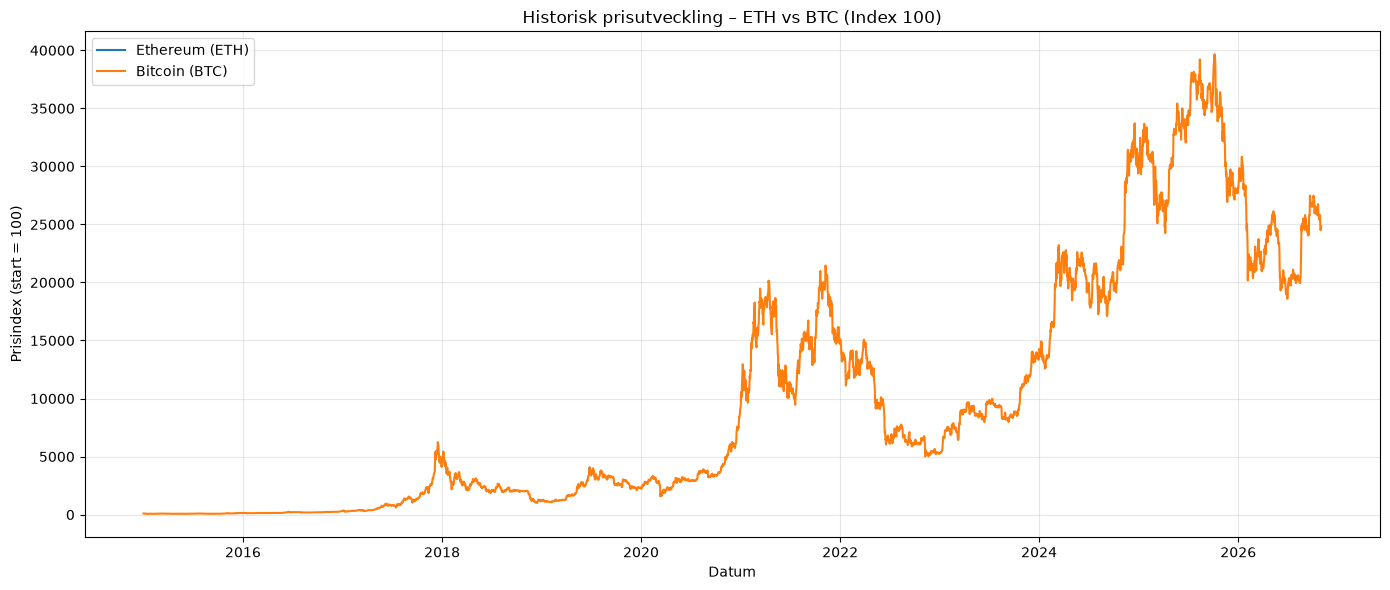

In [83]:

# Steg 23 – Normaliserad prisutveckling

# Skapa kopia av prisdatan
df_plot = df_ml[
    ["time", "ETH_Price", "BTC_Price"]
].copy()

# Normalisera priserna till index 100
df_plot["ETH_Index"] = (
    df_plot["ETH_Price"] / df_plot["ETH_Price"].iloc[0] * 100
)

df_plot["BTC_Index"] = (
    df_plot["BTC_Price"] / df_plot["BTC_Price"].iloc[0] * 100
)

# Skapa diagram
plt.figure(figsize=(14, 6))

plt.plot(
    df_plot["time"],
    df_plot["ETH_Index"],
    label="Ethereum (ETH)"
)

plt.plot(
    df_plot["time"],
    df_plot["BTC_Index"],
    label="Bitcoin (BTC)"
)

plt.title("Historisk prisutveckling – ETH vs BTC (Index 100)")
plt.xlabel("Datum")
plt.ylabel("Prisindex (start = 100)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Steg 24 – Korrelationsanalys

Vi undersöker linjära samband mellan våra
förklarande variabler och Ethereums framtida avkastning.

Vi använder Pearsons korrelationskoefficient
för att analysera sambanden.

Analysen omfattar:
- ETH:s och BTC:s dagliga avkastning.
- Historisk volatilitet och RSI.
- Handelsvolym och nätverksaktivitet.
- Fear & Greed Index.
- Makroekonomiska variabler.
- ETH:s framtida avkastning efter 6 och 12 månader.

Syftet är att identifiera potentiellt relevanta
variabler inför maskininlärningen.

Korrelation innebär inte orsakssamband.
Resultaten är explorativa och ska inte användas
för att välja features utifrån testperiodens utfall.


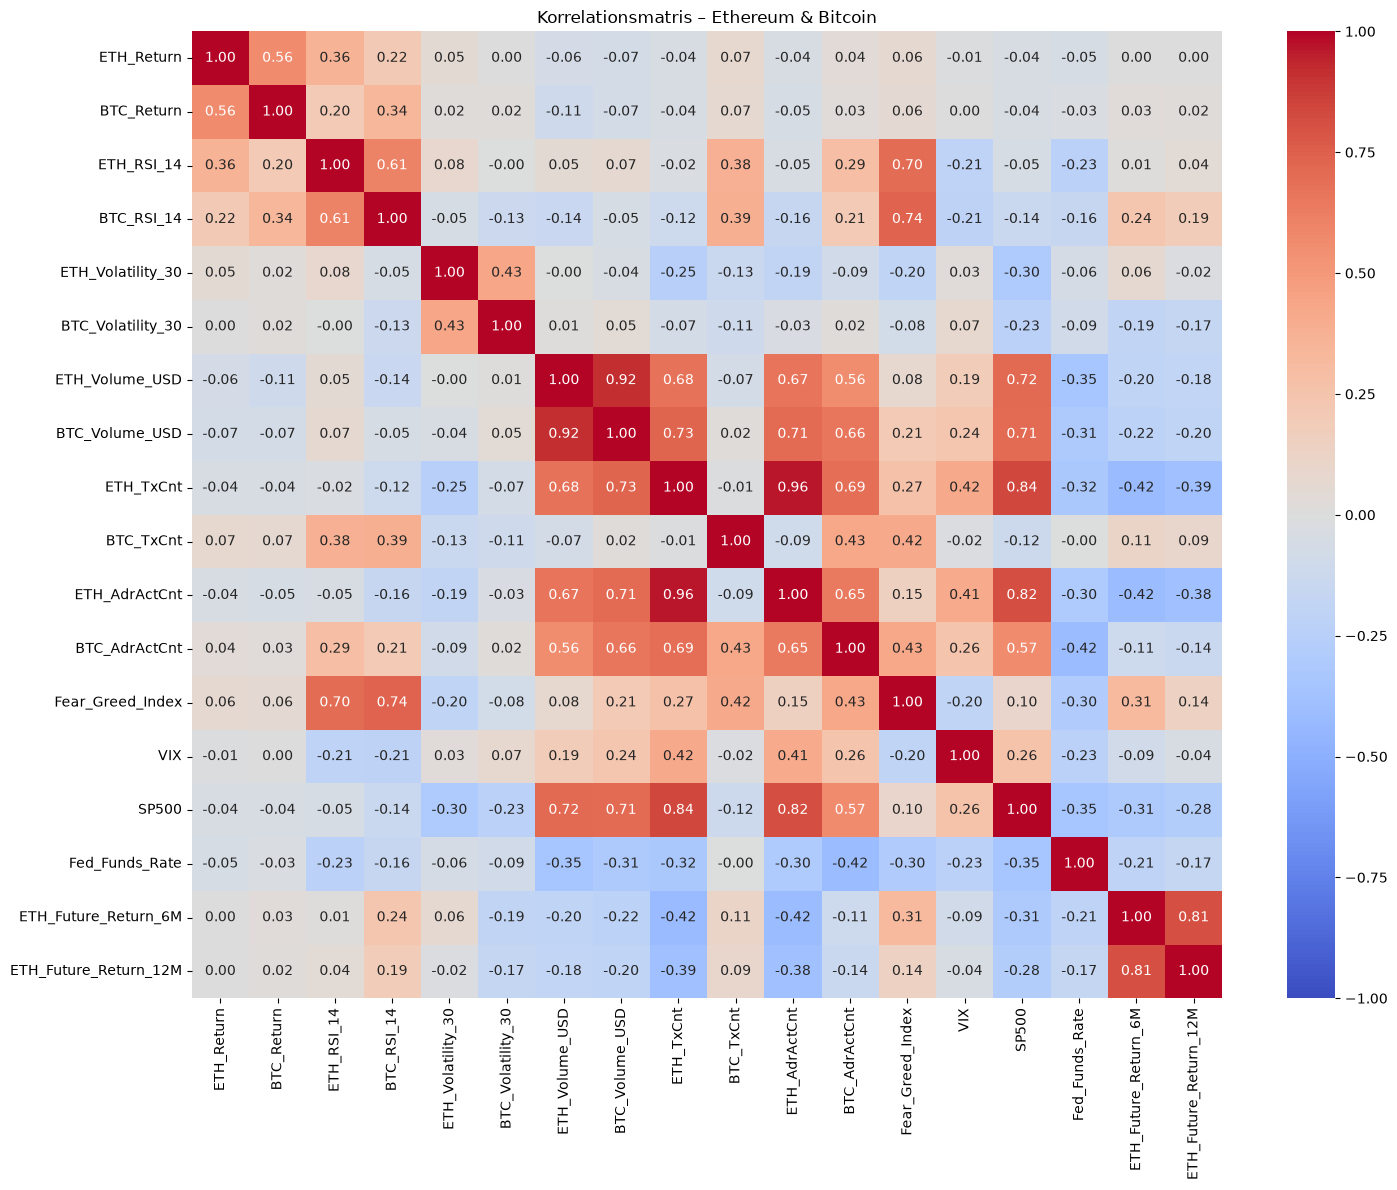

In [84]:

# Steg 24 – Korrelation med framtida ETH-avkastning

correlation_columns = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "BTC_RSI_14",
    "ETH_Volatility_30",
    "BTC_Volatility_30",
    "ETH_Volume_USD",
    "BTC_Volume_USD",
    "ETH_TxCnt",
    "BTC_TxCnt",
    "ETH_AdrActCnt",
    "BTC_AdrActCnt",
    "Fear_Greed_Index",
    "VIX",
    "SP500",
    "Fed_Funds_Rate",
    "ETH_Future_Return_6M",
    "ETH_Future_Return_12M"
]

# Begränsa analysen till en historisk träningsperiod
# så att framtida testdata inte används i featureval.
df_corr = df_ml.loc[
    df_ml["time"] < pd.Timestamp("2023-01-01", tz="UTC"),
    correlation_columns
].copy()

# Beräkna korrelationsmatris
corr_matrix = df_corr.corr(method="pearson")

# Visualisera med heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Korrelationsmatris – Ethereum & Bitcoin")
plt.tight_layout()
plt.show()



### Steg 25 – ETH/BTC Ratio och relativ prisutveckling

I detta steg analyserar vi förhållandet mellan
Ethereum och Bitcoin genom att beräkna ETH/BTC Ratio.

ETH/BTC Ratio visar hur mycket Bitcoin en Ethereum
är värd.

Vi använder följande formel:

ETH/BTC = ETH_Price / BTC_Price

En stigande kvot betyder att Ethereum utvecklas
starkare än Bitcoin.

En sjunkande kvot betyder att Bitcoin utvecklas
starkare än Ethereum.

Syftet är att undersöka långsiktiga trender och
identifiera perioder där ETH över- eller
underpresterar jämfört med BTC.

Denna variabel kommer även att kunna användas
i våra maskininlärningsmodeller.


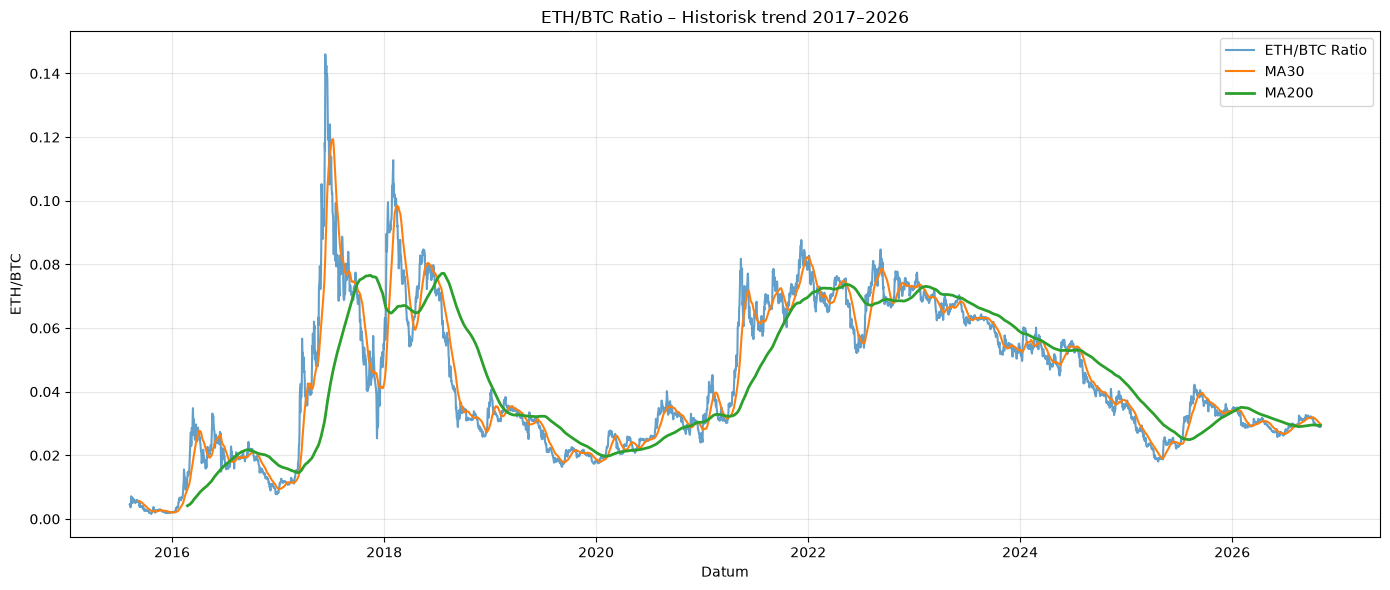

Datasetets storlek: (4323, 34)

Senaste ETH/BTC-värden:


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\4150283771.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(5)


,time,ETH_BTC_Ratio,ETH_BTC_MA30,ETH_BTC_MA200
4313,2026-10-23 00:00:00+00:00,0.02939,0.03068,0.02947
4314,2026-10-24 00:00:00+00:00,0.02915,0.03059,0.02946
4315,2026-10-25 00:00:00+00:00,0.02906,0.03049,0.02945
4316,2026-10-26 00:00:00+00:00,0.02898,0.03039,0.02944
4317,2026-10-27 00:00:00+00:00,0.02905,0.03030,0.02944
4318,2026-10-28 00:00:00+00:00,0.02901,0.03019,0.02942
4319,2026-10-29 00:00:00+00:00,0.02885,0.03009,0.02941
4320,2026-10-30 00:00:00+00:00,0.02905,0.02999,0.02940
4321,2026-10-31 00:00:00+00:00,0.02910,0.02989,0.02939
4322,2026-11-01 00:00:00+00:00,0.02905,0.02981,0.02938


In [85]:

# Steg 25 – Beräkna ETH/BTC Ratio

# Skapa ETH/BTC Ratio
df_ml["ETH_BTC_Ratio"] = (
    df_ml["ETH_Price"] / df_ml["BTC_Price"]
)

# Beräkna glidande medelvärde för kvoten
df_ml["ETH_BTC_MA30"] = (
    df_ml["ETH_BTC_Ratio"].rolling(30).mean()
)

df_ml["ETH_BTC_MA200"] = (
    df_ml["ETH_BTC_Ratio"].rolling(200).mean()
)

# Skapa diagram
plt.figure(figsize=(14, 6))

plt.plot(
    df_ml["time"],
    df_ml["ETH_BTC_Ratio"],
    label="ETH/BTC Ratio",
    alpha=0.7
)

plt.plot(
    df_ml["time"],
    df_ml["ETH_BTC_MA30"],
    label="MA30",
    linewidth=1.5
)

plt.plot(
    df_ml["time"],
    df_ml["ETH_BTC_MA200"],
    label="MA200",
    linewidth=2
)

plt.title("ETH/BTC Ratio – Historisk trend 2017–2026")
plt.xlabel("Datum")
plt.ylabel("ETH/BTC")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Kontrollera resultat
print("Datasetets storlek:", df_ml.shape)

print("\nSenaste ETH/BTC-värden:")
display(
    df_ml[
        ["time", "ETH_BTC_Ratio",
         "ETH_BTC_MA30", "ETH_BTC_MA200"]
    ].tail(10).round(5)
)



### Steg 26 – Logaritmisk regression och trendkanal

Vi analyserar den långsiktiga utvecklingen av
ETH/BTC-kvoten med hjälp av logaritmisk transformation
och linjär regression.

Genom att använda logaritmen av ETH/BTC kan vi
analysera relativa förändringar över tid.

Vi använder linjär regression för att beräkna
en långsiktig trendlinje.

Därefter skapar vi ett trendband baserat på
standardavvikelsen för modellens residualer.

Syftet är att visualisera historiska avvikelser
från den skattade trenden och identifiera
perioder där kvoten befinner sig över eller
under trendbandet.

Trendkanalen är explorativ och används inte
direkt som en framtidsprognos.

För backtesting måste trendmodellen senare
anpassas med endast historiskt tillgänglig data.


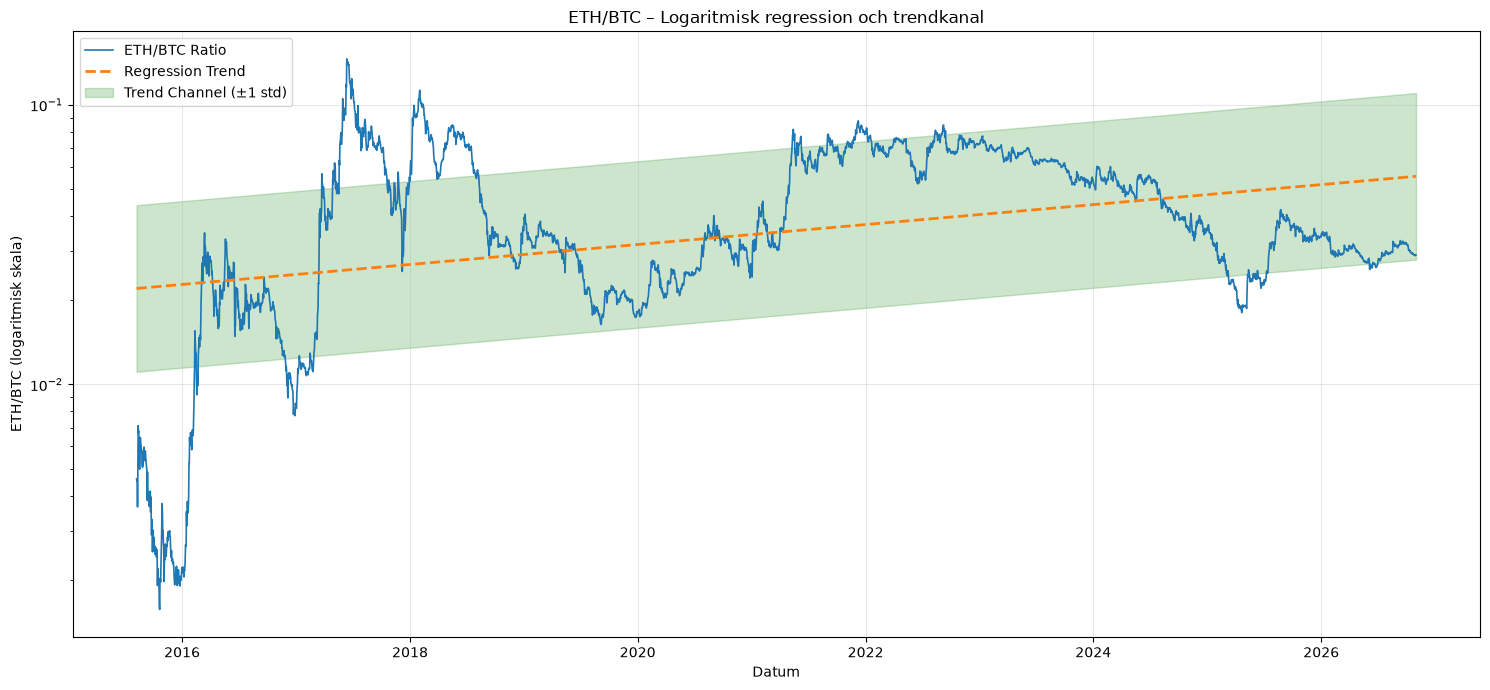

R²: 0.1314
Residual standardavvikelse: 0.6858


In [86]:

# Steg 26 – Logaritmisk regression med trendkanal

from sklearn.linear_model import LinearRegression

# Kopiera relevant data
df_trend = df_ml[
    ["time", "ETH_BTC_Ratio"]
].dropna().copy()

# Skapa tidsvariabel: antal dagar sedan första observationen
df_trend["days"] = (
    df_trend["time"] - df_trend["time"].min()
).dt.days

# Logaritmera kvoten
df_trend["log_ratio"] = np.log(
    df_trend["ETH_BTC_Ratio"]
)

# Förbered X och y
X = df_trend[["days"]]
y = df_trend["log_ratio"]

# Träna linjär regressionsmodell
trend_model = LinearRegression()
trend_model.fit(X, y)

# Beräkna trend och residualer
df_trend["log_trend"] = trend_model.predict(X)

df_trend["residual"] = (
    df_trend["log_ratio"] - df_trend["log_trend"]
)

# Standardavvikelse för residualerna
residual_std = df_trend["residual"].std()

# Omvandla tillbaka från logaritmisk skala
df_trend["Trend"] = np.exp(df_trend["log_trend"])

df_trend["Upper_Band"] = np.exp(
    df_trend["log_trend"] + residual_std
)

df_trend["Lower_Band"] = np.exp(
    df_trend["log_trend"] - residual_std
)

# Skapa diagram
plt.figure(figsize=(15, 7))

plt.plot(
    df_trend["time"],
    df_trend["ETH_BTC_Ratio"],
    label="ETH/BTC Ratio",
    linewidth=1.2
)

plt.plot(
    df_trend["time"],
    df_trend["Trend"],
    label="Regression Trend",
    linestyle="--",
    linewidth=2
)

plt.fill_between(
    df_trend["time"],
    df_trend["Lower_Band"],
    df_trend["Upper_Band"],
    color="green",
    alpha=0.2,
    label="Trend Channel (±1 std)"
)

plt.yscale("log")

plt.title("ETH/BTC – Logaritmisk regression och trendkanal")
plt.xlabel("Datum")
plt.ylabel("ETH/BTC (logaritmisk skala)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visa modellens resultat
print("R²:", round(trend_model.score(X, y), 4))
print("Residual standardavvikelse:", round(residual_std, 4))



### Steg 27 – Rolling Regression och dynamisk trendkanal

Den tidigare linjära regressionsmodellen gav ett
R²-värde på 0,0029, vilket visar att en enkel
långsiktig trend inte beskriver ETH/BTC särskilt väl.

Vi testar därför Rolling Regression.

Modellen använder de senaste 365 dagarnas
historiska observationer för att beräkna en
dynamisk trendlinje.

Vi skapar även ett övre och nedre trendband
utifrån residualernas standardavvikelse.

Syftet är att identifiera:
- Förändringar i den långsiktiga trenden.
- Perioder då ETH/BTC avviker från trenden.
- Potentiella trendbrott.

Vi använder endast historisk information
vid varje beräkning för att undvika data leakage.

Trendbanden är statistiska avvikelseband
och ska inte tolkas som garanterade köpzoner.


In [87]:

# Steg 27 – Rolling Regression med trendkanal

from sklearn.linear_model import LinearRegression

window = 365

df_rolling = df_ml[
    ["time", "ETH_BTC_Ratio"]
].copy()

df_rolling = df_rolling.sort_values("time").reset_index(drop=True)

log_prices = np.log(df_rolling["ETH_BTC_Ratio"].to_numpy())

trend_values = np.full(len(df_rolling), np.nan)
upper_values = np.full(len(df_rolling), np.nan)
lower_values = np.full(len(df_rolling), np.nan)

X_window = np.arange(window).reshape(-1, 1)

for i in range(window - 1, len(df_rolling)):

    # Endast senaste 365 dagarna
    y_window = log_prices[i-window+1:i+1]

    model = LinearRegression()
    model.fit(X_window, y_window)

    # Trendvärde för dagens datum
    predicted = model.predict(X_window)

    residual_std = np.std(
        y_window - predicted,
        ddof=1
    )

    trend_values[i] = np.exp(predicted[-1])
    upper_values[i] = np.exp(predicted[-1] + residual_std)
    lower_values[i] = np.exp(predicted[-1] - residual_std)

df_rolling["Rolling_Trend"] = trend_values
df_rolling["Upper_Band"] = upper_values
df_rolling["Lower_Band"] = lower_values

# Visualisering
plt.figure(figsize=(15, 7))

plt.plot(
    df_rolling["time"],
    df_rolling["ETH_BTC_Ratio"],
    label="ETH/BTC",
    linewidth=1,
    alpha=0.65
)

plt.plot(
    df_rolling["time"],
    df_rolling["Rolling_Trend"],
    label="Rolling Regression (365 dagar)",
    linewidth=2,
    color="darkgreen"
)

plt.fill_between(
    df_rolling["time"],
    df_rolling["Lower_Band"],
    df_rolling["Upper_Band"],
    color="green",
    alpha=0.18,
    label="Dynamisk trendkanal"
)

plt.yscale("log")
plt.title("ETH/BTC – Dynamisk trendkanal (Rolling Regression)")
plt.xlabel("Datum")
plt.ylabel("ETH/BTC – Logaritmisk skala")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


ValueError: Input y contains NaN.


### Steg 28 – Identifiering av trendbrott

Vi använder den dynamiska trendkanalen för att
identifiera perioder då ETH/BTC avviker
från sin historiska trend.

Vi skapar en kategorisk variabel:

- -1: Under det nedre trendbandet.
-  0: Inom trendbandet.
-  1: Över det övre trendbandet.

Vi identifierar även när ETH/BTC passerar
ned genom det nedre trendbandet.

Syftet är att skapa nya features som kan
användas i våra maskininlärningsmodeller.

Trendbrott är tekniska signaler och innebär
inte automatiskt att framtida prisrörelser
kan förutsägas.

Vid backtesting behöver vi säkerställa att
signalerna endast använder information som
var tillgänglig vid respektive tidpunkt.


In [ ]:

# Steg 28 – Identifiera trendbrott

# Skapa kategorier för trendkanalen
df_rolling["Trend_Zone"] = np.select(
    [
        df_rolling["ETH_BTC_Ratio"] < df_rolling["Lower_Band"],
        df_rolling["ETH_BTC_Ratio"] > df_rolling["Upper_Band"]
    ],
    [-1, 1],
    default=0
)

# Markera observationer där trendkanalen saknas
df_rolling.loc[
    df_rolling["Lower_Band"].isna(),
    "Trend_Zone"
] = np.nan

# Identifiera nedåtgående trendbrott
df_rolling["Breakdown"] = (
    (df_rolling["Trend_Zone"] == -1) &
    (df_rolling["Trend_Zone"].shift(1) != -1)
).astype(int)

# De första dagarna saknar tillräcklig historik
df_rolling.loc[
    df_rolling["Trend_Zone"].isna(),
    "Breakdown"
] = 0

# Visa fördelningen
print("Antal observationer i respektive trendzon:")
print(df_rolling["Trend_Zone"].value_counts(dropna=False))

print("\nAntal nedåtgående trendbrott:")
print(df_rolling["Breakdown"].sum())

# Visa senaste observationerna
display(
    df_rolling[
        ["time", "ETH_BTC_Ratio",
         "Lower_Band", "Upper_Band",
         "Trend_Zone", "Breakdown"]
    ].tail(10)
)


Antal observationer i respektive trendzon:
Trend_Zone
 0.0    1675
-1.0     830
 1.0     723
 NaN     364
Name: count, dtype: int64

Antal nedåtgående trendbrott:
57


,time,ETH_BTC_Ratio,Lower_Band,Upper_Band,Trend_Zone,Breakdown
3582,2026-10-23 00:00:00+00:00,0.029389,0.026701,0.030539,0.0,0
3583,2026-10-24 00:00:00+00:00,0.029145,0.026710,0.030543,0.0,0
3584,2026-10-25 00:00:00+00:00,0.029058,0.026720,0.030547,0.0,0
3585,2026-10-26 00:00:00+00:00,0.028976,0.026735,0.030551,0.0,0
3586,2026-10-27 00:00:00+00:00,0.029054,0.026750,0.030555,0.0,0
3587,2026-10-28 00:00:00+00:00,0.029014,0.026759,0.030558,0.0,0
3588,2026-10-29 00:00:00+00:00,0.028852,0.026768,0.030560,0.0,0
3589,2026-10-30 00:00:00+00:00,0.029053,0.026777,0.030563,0.0,0
3590,2026-10-31 00:00:00+00:00,0.029096,0.026787,0.030568,0.0,0
3591,2026-11-01 00:00:00+00:00,0.029052,0.026797,0.030572,0.0,0



### Steg 29 – Integrering av trendvariabler

Vi kompletterar vår Machine Learning-dataset med
variabler från den dynamiska ETH/BTC-trendkanalen.

Vi lägger till:

- Rolling_Trend: Den rullande regressionstrenden.
- Trend_Zone: Position i förhållande till trendbandet.
- Breakdown: Signal vid nedåtgående trendbrott.
- Trend_Distance_Pct: Procentuell avvikelse från trenden.

Syftet är att undersöka om trendrelaterade
variabler kan bidra till att förutsäga
Ethereums framtida avkastning.

Trendkanalen har beräknats med historiska
observationer fram till respektive datum.

Signalerna förutsätter därför att dagens
prisobservation är tillgänglig.

Vid senare backtesting kommer vi att skilja
mellan signalens observationstidpunkt
och tidpunkten då en handel kan genomföras.


In [ ]:

# Steg 29 – Lägg till trendvariabler i ML-dataset

# Beräkna avstånd från trendlinjen i procent
df_rolling["Trend_Distance_Pct"] = (
    (
        df_rolling["ETH_BTC_Ratio"]
        / df_rolling["Rolling_Trend"]
    ) - 1
) * 100

# Välj variabler som ska integreras
trend_columns = [
    "time",
    "Rolling_Trend",
    "Trend_Zone",
    "Breakdown",
    "Trend_Distance_Pct"
]

# Kombinera med huvuddataset
df_ml = df_ml.merge(
    df_rolling[trend_columns],
    on="time",
    how="left",
    validate="one_to_one"
)

# Markera Breakdown som saknat när trendkanalen saknas
df_ml.loc[
    df_ml["Trend_Zone"].isna(),
    "Breakdown"
] = np.nan

# Kontrollera resultat
print("Datasetets storlek:", df_ml.shape)

print("\nSaknade värden i trendvariabler:")
print(df_ml[trend_columns[1:]].isna().sum())

print("\nSenaste observationerna:")
display(
    df_ml[trend_columns].tail(10)
)

# Spara uppdaterad dataset
df_ml.to_csv(
    data_folder / "crypto_ml_with_trends.csv",
    index=False
)


Datasetets storlek: (3592, 38)

Saknade värden i trendvariabler:
Rolling_Trend         364
Trend_Zone            364
Breakdown             364
Trend_Distance_Pct    364
dtype: int64

Senaste observationerna:


,time,Rolling_Trend,Trend_Zone,Breakdown,Trend_Distance_Pct
3582,2026-10-23 00:00:00+00:00,0.028555,0.0,0.0,2.918675
3583,2026-10-24 00:00:00+00:00,0.028563,0.0,0.0,2.039239
3584,2026-10-25 00:00:00+00:00,0.028569,0.0,0.0,1.711959
3585,2026-10-26 00:00:00+00:00,0.028579,0.0,0.0,1.386659
3586,2026-10-27 00:00:00+00:00,0.028589,0.0,0.0,1.624382
3587,2026-10-28 00:00:00+00:00,0.028596,0.0,0.0,1.461524
3588,2026-10-29 00:00:00+00:00,0.028601,0.0,0.0,0.877179
3589,2026-10-30 00:00:00+00:00,0.028607,0.0,0.0,1.555751
3590,2026-10-31 00:00:00+00:00,0.028615,0.0,0.0,1.681966
3591,2026-11-01 00:00:00+00:00,0.028622,0.0,0.0,1.501863



### Steg 30 – Analys av framtida avkastning efter trendbrott

Vi undersöker om nedåtgående trendbrott i ETH/BTC
har samband med Ethereums framtida avkastning.

Vi jämför två grupper:

1. Observationer där ett nedåtgående trendbrott inträffade.
2. Observationer utan nedåtgående trendbrott.

För båda grupperna analyserar vi:
- Antal observationer.
- Genomsnittlig framtida avkastning.
- Median för framtida avkastning.
- Andel observationer med positiv avkastning.

Vi undersöker både 6 och 12 månaders horisont.

Analysen är explorativ och visar historiska samband,
inte om en handelsstrategi skulle vara lönsam.

Eftersom framtida avkastningsperioder överlappar
varandra är observationerna inte oberoende.
Detta behöver beaktas i senare backtesting.


In [ ]:

# Steg 30 – Framtida avkastning efter trendbrott

results = []

# Begränsa analysen till historisk utvecklingsperiod
# Vi håller senare år utanför denna explorativa jämförelse.
analysis_data = df_ml[
    df_ml["time"] < pd.Timestamp("2023-01-01", tz="UTC")
].copy()

for horizon in ["6M", "12M"]:

    target = f"ETH_Future_Return_{horizon}"

    # Behåll bara dagar med giltig trend och framtida avkastning
    valid = analysis_data[
        analysis_data["Breakdown"].notna()
        & analysis_data[target].notna()
    ].copy()

    for breakdown, group_name in [
        (1, "Trendbrott"),
        (0, "Övriga dagar")
    ]:

        subset = valid.loc[
            valid["Breakdown"] == breakdown, target
        ]

        results.append({
            "Horisont": horizon,
            "Grupp": group_name,
            "Antal": len(subset),
            "Medelavkastning (%)": subset.mean(),
            "Medianavkastning (%)": subset.median(),
            "Andel positiv (%)": (subset > 0).mean() * 100
        })

# Sammanställ resultaten
df_breakdown_results = pd.DataFrame(results)

display(df_breakdown_results.round(2))


,Horisont,Grupp,Antal,Medelavkastning (%),Medianavkastning (%),Andel positiv (%)
0,6M,Trendbrott,20,54.43,-44.46,30.00
1,6M,Övriga dagar,1807,53.35,14.96,57.55
2,12M,Trendbrott,20,115.63,-46.81,35.00
3,12M,Övriga dagar,1807,183.04,13.28,54.84



### Steg 31 – Relativ avkastning efter trendbrott

I föregående analys observerade vi att nedåtgående
ETH/BTC-trendbrott ofta följdes av svagare
framtida Ethereum-avkastning.

Vi vill nu undersöka om Ethereum också
underpresterade relativt Bitcoin.

Vi beräknar därför den framtida förändringen
i ETH/BTC-kvoten efter 6 och 12 månader.

En positiv förändring innebär att Ethereum
utvecklats bättre än Bitcoin.

En negativ förändring innebär att Ethereum
utvecklats sämre än Bitcoin.

För att hålla senare perioder separata använder
vi endast observationer där hela framtidsperioden
avslutades före den 1 januari 2023.

Resultaten är explorativa och bevisar inte
orsakssamband eller prognosförmåga.


In [ ]:

# Steg 31 – ETH:s framtida utveckling relativt BTC

from pandas.tseries.offsets import DateOffset

df_relative = df_ml.copy()

for months, label in [(6, "6M"), (12, "12M")]:

    future_dates = df_relative["time"] + DateOffset(
        months=months
    )

    # Hitta framtida ETH/BTC-kvot på rätt datum
    lookup = pd.DataFrame({"future_time": future_dates})

    future_ratio = df_relative[
        ["time", "ETH_BTC_Ratio"]
    ].rename(columns={
        "time": "future_time",
        "ETH_BTC_Ratio": "Future_Ratio"
    })

    lookup = lookup.merge(
        future_ratio,
        on="future_time",
        how="left",
        validate="many_to_one"
    )

    # Beräkna relativ avkastning
    target = f"ETH_BTC_Future_Return_{label}"

    df_relative[target] = (
        lookup["Future_Ratio"].to_numpy()
        / df_relative["ETH_BTC_Ratio"].to_numpy()
        - 1
    ) * 100

# Jämför grupperna för varje prognoshorisont
results_relative = []

cutoff = pd.Timestamp("2023-01-01", tz="UTC")

for months, label in [(6, "6M"), (12, "12M")]:

    target = f"ETH_BTC_Future_Return_{label}"

    future_dates = (
        df_relative["time"] + DateOffset(months=months)
    )

    valid = df_relative.loc[
        (future_dates < cutoff)
        & df_relative["Breakdown"].notna()
        & df_relative[target].notna()
    ].copy()

    for signal, group_name in [
        (1, "Trendbrott"),
        (0, "Övriga dagar")
    ]:

        values = valid.loc[
            valid["Breakdown"] == signal,
            target
        ]

        results_relative.append({
            "Horisont": label,
            "Grupp": group_name,
            "Antal": len(values),
            "Medel (%)": values.mean(),
            "Median (%)": values.median(),
            "ETH bättre än BTC (%)": (values > 0).mean() * 100
        })

df_relative_results = pd.DataFrame(results_relative)

display(df_relative_results.round(2))


,Horisont,Grupp,Antal,Medel (%),Median (%),ETH bättre än BTC (%)
0,6M,Trendbrott,20,26.19,2.42,55.00
1,6M,Övriga dagar,1623,8.41,4.49,56.13
2,12M,Trendbrott,15,47.28,10.41,73.33
3,12M,Övriga dagar,1447,28.19,7.65,53.97



### Steg 32 – Förberedelse av Machine Learning-dataset

Vi förbereder datasetet för att träna en
klassificeringsmodell som ska förutsäga
om Ethereum stiger under de kommande sex månaderna.

Vi delar upp datan kronologiskt:

- Träning: historiska observationer före 2023.
- Validering: 2023–2024.
- Test: 2025 och senare.

Vi ser till att träningsobservationernas
framtida utfall är kända före valideringsperioden.

Vi utesluter även målvariabler från våra features
och hanterar saknade värden.

Syftet är att minska risken för data leakage
och skapa en rättvis modellutvärdering.


In [ ]:

# Steg 32 – Förbered dataset för ML

# Välj en första uppsättning features
feature_columns = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "BTC_RSI_14",
    "ETH_Volatility_30",
    "BTC_Volatility_30",
    "ETH_Volume_USD",
    "BTC_Volume_USD",
    "ETH_TxCnt",
    "BTC_TxCnt",
    "ETH_AdrActCnt",
    "BTC_AdrActCnt",
    "Fear_Greed_Index",
    "VIX",
    "SP500",
    "Fed_Funds_Rate",
    "ETH_BTC_Ratio",
    "Trend_Zone",
    "Breakdown",
    "Trend_Distance_Pct"
]

target_column = "ETH_Up_6M"

# Kopiera relevanta kolumner
df_model = df_ml[
    ["time"] + feature_columns + [target_column]
].copy()

# Lägg till framtida slutdatum för målvariabeln
df_model["target_end"] = (
    df_model["time"] + pd.DateOffset(months=6)
)

# Ta bort rader utan features eller känt utfall
df_model = df_model.dropna().copy()

# Definiera periodgränser
validation_start = pd.Timestamp("2023-01-01", tz="UTC")
test_start = pd.Timestamp("2025-01-01", tz="UTC")

# Kronologisk uppdelning med purging
train_df = df_model[
    df_model["target_end"] < validation_start
].copy()

validation_df = df_model[
    (df_model["time"] >= validation_start)
    & (df_model["target_end"] < test_start)
].copy()

test_df = df_model[
    (df_model["time"] >= test_start)
    & (df_model[target_column].notna())
].copy()

print("Träningsdata:", train_df.shape)
print("Valideringsdata:", validation_df.shape)
print("Testdata:", test_df.shape)

print("\nAndel positiva utfall:")
for name, dataset in [
    ("Träning", train_df),
    ("Validering", validation_df),
    ("Test", test_df)
]:
    print(
        name,
        round(dataset[target_column].mean() * 100, 2),
        "%"
    )


Träningsdata: (1611, 23)
Valideringsdata: (547, 23)
Testdata: (486, 23)

Andel positiva utfall:
Träning 55.49 %
Validering 68.19 %
Test 51.44 %



### Steg 33 – Logistic Regression

Vi tränar vår första maskininlärningsmodell
med hjälp av logistisk regression.

Modellens uppgift är att klassificera om Ethereum
kommer att ha positiv eller negativ avkastning
under de kommande sex månaderna.

Målvariabel:
- 1 = Positiv avkastning.
- 0 = Ingen positiv avkastning.

Vi använder 20 förklarande variabler från vår
historiska dataset.

Eftersom variablerna har olika skalor använder
vi StandardScaler för att standardisera datan.

Standardiseringen anpassas endast på
träningsdata för att undvika data leakage.

Modellen utvärderas först på valideringsdata.
Testperioden sparas till den slutliga utvärderingen.


In [ ]:

# Steg 33 – Träna logistisk regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Separera features och målvariabel
X_train = train_df[feature_columns]
y_train = train_df[target_column].astype(int)

X_val = validation_df[feature_columns]
y_val = validation_df[target_column].astype(int)

# Skapa ML-pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Träna endast på träningsdata
logistic_model.fit(X_train, y_train)

# Prognoser på valideringsdata
y_val_pred = logistic_model.predict(X_val)

# Utvärdera modellen
print("Logistic Regression – Valideringsresultat")

print("Accuracy:", round(
    accuracy_score(y_val, y_val_pred), 4
))

print("Precision:", round(
    precision_score(y_val, y_val_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_val, y_val_pred, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_val, y_val_pred, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val, y_val_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))


Logistic Regression – Valideringsresultat
Accuracy: 0.3181
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.32      1.00      0.48       174
           1       0.00      0.00      0.00       373

    accuracy                           0.32       547
   macro avg       0.16      0.50      0.24       547
weighted avg       0.10      0.32      0.15       547


Confusion Matrix:
[[174   0]
 [373   0]]



### Steg 34 – Baseline och analys av modellens prognoser

Den logistiska regressionsmodellen uppnådde
31,81 % Accuracy på valideringsdata.

Modellen förutsade endast klass 0, trots att
majoriteten av observationerna tillhörde klass 1.

Vi undersöker därför modellens förutsagda
sannolikheter och jämför med en enkel baseline.

Vår baseline använder den vanligaste klassen
i träningsdatan och förutsäger denna för
samtliga valideringsobservationer.

Syftet är att kontrollera om maskininlärningsmodellen
faktiskt ger bättre resultat än en enkel referensmodell.

Vi använder endast träningsdata för att definiera
baselinens prognosregel.

Testperioden används inte i detta steg.


BASELINE
Vanligaste klass i träning: 1
Accuracy: 0.6819

LOGISTIC REGRESSION
Accuracy: 0.3181
Balanced Accuracy: 0.5
ROC-AUC: 0.3256

MODELLENS SANNOLIKHETER
Min: 0.0
Medel: 0.0
Max: 0.0002

Antal prognoser per klass:
0    547
Name: count, dtype: int64


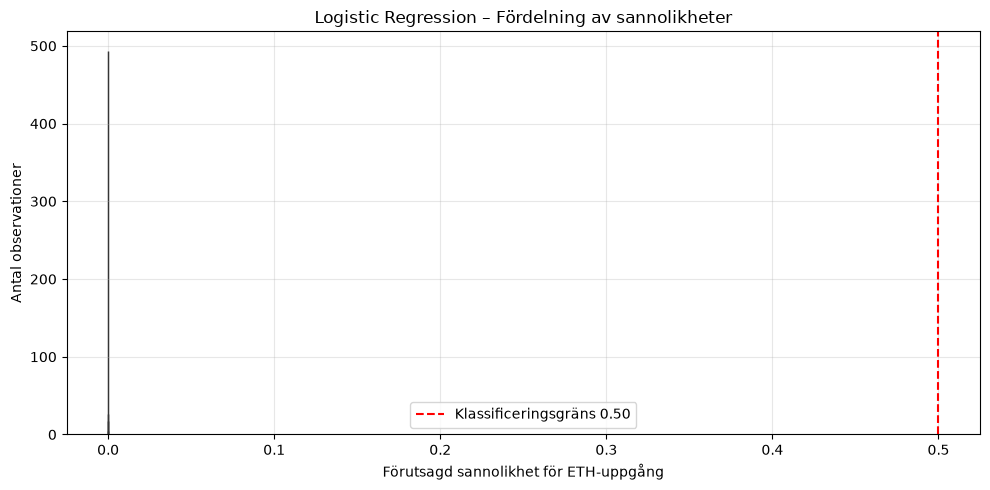

In [ ]:

# Steg 34 – Baseline och sannolikhetsanalys

from sklearn.metrics import balanced_accuracy_score, roc_auc_score

# Baseline: vanligaste klassen i träningsdata
majority_class = int(y_train.mode()[0])

baseline_pred = np.full(
    len(y_val),
    majority_class
)

# Modellens sannolikhet för positiv avkastning
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("BASELINE")
print("Vanligaste klass i träning:", majority_class)
print("Accuracy:", round(
    accuracy_score(y_val, baseline_pred), 4
))

print("\nLOGISTIC REGRESSION")
print("Accuracy:", round(
    accuracy_score(y_val, y_val_pred), 4
))

print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, y_val_pred), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, y_val_prob), 4
))

print("\nMODELLENS SANNOLIKHETER")
print("Min:", round(y_val_prob.min(), 4))
print("Medel:", round(y_val_prob.mean(), 4))
print("Max:", round(y_val_prob.max(), 4))

print("\nAntal prognoser per klass:")
print(pd.Series(y_val_pred).value_counts())

# Visa sannolikheternas fördelning
plt.figure(figsize=(10, 5))
plt.hist(y_val_prob, bins=30, edgecolor="black")
plt.axvline(0.5, color="red", linestyle="--",
            label="Klassificeringsgräns 0.50")
plt.title("Logistic Regression – Fördelning av sannolikheter")
plt.xlabel("Förutsagd sannolikhet för ETH-uppgång")
plt.ylabel("Antal observationer")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Steg 35 – Diagnostik av Logistic Regression

Den första logistiska regressionsmodellen
presterade sämre än vår baseline.

Modellen förutsade endast negativ avkastning,
trots att majoriteten av observationerna i
valideringsperioden hade positiv avkastning.

ROC-AUC blev 0,3256, vilket är sämre än 0,50
som motsvarar en modell utan rangordningsförmåga.

Vi undersöker därför:

- Skillnader mellan träningsdata och valideringsdata.
- Vilka features som har förändrats mest.
- Modellens regressionskoefficienter.
- Om vissa variabler dominerar modellens prognoser.

Syftet är att identifiera möjliga orsaker till
modellens dåliga generaliseringsförmåga.

Testperioden används inte i analysen.


In [ ]:

# Steg 35 – Diagnostik av Logistic Regression

# Hämta StandardScaler och regressionsmodellen
scaler = logistic_model.named_steps["scaler"]
model = logistic_model.named_steps["model"]

# Standardisera valideringsdata med träningsperiodens scaler
X_val_scaled = scaler.transform(X_val)

# Undersök skillnader mellan perioderna
feature_shift = pd.DataFrame({
    "Feature": feature_columns,
    "Train_Mean": X_train.mean().values,
    "Validation_Mean": X_val.mean().values,
    "Validation_Z_Mean": X_val_scaled.mean(axis=0),
    "Coefficient": model.coef_[0]
})

# Sortera efter störst standardiserad skillnad
feature_shift["Abs_Shift"] = (
    feature_shift["Validation_Z_Mean"].abs()
)

feature_shift = feature_shift.sort_values(
    "Abs_Shift",
    ascending=False
)

print("Variabler med störst förändring:")
display(feature_shift.head(10).round(3))

# Visa regressionskoefficienterna
coef_df = feature_shift[
    ["Feature", "Coefficient"]
].copy()

coef_df["Abs_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

print("\nStörsta regressionskoefficienterna:")
display(coef_df.head(10).round(3))

# Undersök modellens råa beslutsvärden
decision_values = logistic_model.decision_function(X_val)

print("\nBeslutsvärden:")
print("Min:", round(decision_values.min(), 2))
print("Medel:", round(decision_values.mean(), 2))
print("Max:", round(decision_values.max(), 2))


Variabler med störst förändring:


,Feature,Train_Mean,Validation_Mean,Validation_Z_Mean,Coefficient,Abs_Shift
15,Fed_Funds_Rate,1.030,5.125,4.283,-2.197,4.283
9,BTC_TxCnt,278418.865,439468.826,2.943,-0.951,2.943
14,SP500,3407.680,4561.324,1.684,0.864,1.684
4,ETH_Volatility_30,4.782,2.660,-1.334,0.546,1.334
5,BTC_Volatility_30,3.692,2.380,-0.959,-0.335,0.959
16,ETH_BTC_Ratio,0.045,0.060,0.696,-5.481,0.696
12,Fear_Greed_Index,43.774,59.512,0.688,-0.813,0.688
8,ETH_TxCnt,913897.369,1092204.623,0.624,-0.651,0.624
13,VIX,20.965,15.829,-0.598,1.314,0.598
10,ETH_AdrActCnt,436155.519,512867.005,0.529,0.242,0.529



Största regressionskoefficienterna:


,Feature,Coefficient,Abs_Coefficient
16,ETH_BTC_Ratio,-5.481,5.481
2,ETH_RSI_14,-2.402,2.402
15,Fed_Funds_Rate,-2.197,2.197
3,BTC_RSI_14,2.081,2.081
19,Trend_Distance_Pct,1.816,1.816
6,ETH_Volume_USD,1.610,1.610
17,Trend_Zone,1.331,1.331
13,VIX,1.314,1.314
9,BTC_TxCnt,-0.951,0.951
14,SP500,0.864,0.864



Beslutsvärden:
Min: -22.0
Medel: -15.65
Max: -8.74



### Steg 36 – Förbättrad Logistic Regression

Den första modellen presterade sämre än vår baseline.

Diagnostiken visade stora skillnader mellan
tränings- och valideringsperioderna för flera
variabler, särskilt räntor och nätverksaktivitet.

Vi testar därför en förenklad modell med färre
förklarande variabler.

Vi fokuserar på:
- Daglig ETH- och BTC-avkastning.
- RSI och historisk volatilitet.
- Marknadssentiment.
- ETH/BTC-trendindikatorer.

Vi jämför modellen med den ursprungliga
logistiska regressionen och vår baseline.

Syftet är att undersöka om en enklare modell
generaliserar bättre till nya tidsperioder.

Modellvalet baseras endast på tränings- och
valideringsdata. Testperioden används inte.


In [ ]:

# Steg 36 – Förenklad Logistic Regression

# Välj färre features
selected_features = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "BTC_RSI_14",
    "ETH_Volatility_30",
    "BTC_Volatility_30",
    "Fear_Greed_Index",
    "ETH_BTC_Ratio",
    "Trend_Zone",
    "Breakdown",
    "Trend_Distance_Pct"
]

# Använd samma tränings- och valideringsperioder
X_train_simple = train_df[selected_features]
X_val_simple = validation_df[selected_features]

# Skapa ny pipeline
logistic_simple = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Träna den nya modellen
logistic_simple.fit(X_train_simple, y_train)

# Förutsägelser
y_val_simple = logistic_simple.predict(X_val_simple)

# Sannolikheter
y_prob_simple = logistic_simple.predict_proba(
    X_val_simple
)[:, 1]

# Jämför modellerna
comparison = pd.DataFrame({
    "Modell": [
        "Baseline",
        "Logistic Regression – Original",
        "Logistic Regression – Förenklad"
    ],
    "Accuracy": [
        accuracy_score(y_val, baseline_pred),
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, y_val_simple)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, baseline_pred),
        balanced_accuracy_score(y_val, y_val_pred),
        balanced_accuracy_score(y_val, y_val_simple)
    ],
    "F1": [
        f1_score(y_val, baseline_pred, zero_division=0),
        f1_score(y_val, y_val_pred, zero_division=0),
        f1_score(y_val, y_val_simple, zero_division=0)
    ]
})

display(comparison.round(4))

print("\nFörenklad modell – ROC-AUC:")
print(round(roc_auc_score(y_val, y_prob_simple), 4))

print("\nFörutsagda klasser:")
print(pd.Series(y_val_simple).value_counts())

print("\nSannolikheter:")
print("Min:", round(y_prob_simple.min(), 4))
print("Medel:", round(y_prob_simple.mean(), 4))
print("Max:", round(y_prob_simple.max(), 4))


,Modell,Accuracy,Balanced Accuracy,F1
0,Baseline,0.6819,0.5000,0.8109
1,Logistic Regression – Original,0.3181,0.5000,0.0000
2,Logistic Regression – Förenklad,0.2614,0.3833,0.0818



Förenklad modell – ROC-AUC:
0.3809

Förutsagda klasser:
0    480
1     67
Name: count, dtype: int64

Sannolikheter:
Min: 0.041
Medel: 0.2601
Max: 0.7654



### Steg 37 – Random Forest Classification

De tidigare logistiska regressionsmodellerna
presterade sämre än vår baseline.

Vi testar därför Random Forest, en ensemblemetod
som kombinerar flera beslutsträd.

Till skillnad från logistisk regression kan
Random Forest identifiera icke-linjära samband
och samspel mellan variabler.

Vi använder samma utvalda features och
samma tränings- och valideringsperioder
som i den förenklade logistiska regressionen.

Vi jämför modellerna med:
- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Testperioden används inte i detta steg.

Syftet är att undersöka om en mer flexibel
modell kan förbättra prognoserna för ETH:s
framtida 6-månadersavkastning.


In [ ]:

# Steg 37 – Random Forest Classification

from sklearn.ensemble import RandomForestClassifier

# Skapa Random Forest-modell
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=20,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Träna endast på träningsdata
rf_model.fit(X_train_simple, y_train)

# Prognoser för valideringsperioden
y_val_rf = rf_model.predict(X_val_simple)

# Sannolikheter för uppgång
y_prob_rf = rf_model.predict_proba(X_val_simple)[:, 1]

# Sammanställ modellernas resultat
models_results = []

for name, pred, prob in [
    ("Baseline", baseline_pred, None),
    ("Logistic Original", y_val_pred, y_val_prob),
    ("Logistic Förenklad", y_val_simple, y_prob_simple),
    ("Random Forest", y_val_rf, y_prob_rf)
]:

    models_results.append({
        "Modell": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, pred),
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, pred, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_val, prob)
            if prob is not None else 0.5
        )
    })

df_model_results = pd.DataFrame(models_results)

display(
    df_model_results.round(4)
)

print("\nRandom Forest – Förutsagda klasser:")
print(pd.Series(y_val_rf).value_counts())

print("\nRandom Forest – Confusion Matrix:")
print(confusion_matrix(y_val, y_val_rf))


,Modell,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,0.6819,0.5000,0.6819,1.0000,0.8109,0.5000
1,Logistic Original,0.3181,0.5000,0.0000,0.0000,0.0000,0.3256
2,Logistic Förenklad,0.2614,0.3833,0.2687,0.0483,0.0818,0.3809
3,Random Forest,0.3803,0.4168,0.5842,0.3164,0.4104,0.3901



Random Forest – Förutsagda klasser:
0    345
1    202
Name: count, dtype: int64

Random Forest – Confusion Matrix:
[[ 90  84]
 [255 118]]



### Steg 38 – Feature Engineering med förändringsvariabler

Våra första ML-modeller presterade sämre än baseline.

Vi undersöker därför om förändringar i
marknadsaktivitet och nätverksaktivitet ger
mer användbar information än absoluta nivåer.

Vi skapar nya features som beskriver procentuella
förändringar över 7 och 30 dagar.

Syftet är att minska påverkan från långsiktiga
nivåskillnader och förbättra modellernas
förmåga att generalisera till nya perioder.

De nya variablerna beräknas endast med historiska
observationer. Vi använder inte framtida avkastning
när vi konstruerar dem.


In [ ]:

# Steg 38 – Nya förändringsvariabler

df_ml_v2 = df_ml.copy()

new_features = {
    "ETH_Volume_Change_7D": ("ETH_Volume_USD", 7),
    "BTC_Volume_Change_7D": ("BTC_Volume_USD", 7),
    "ETH_Tx_Change_30D": ("ETH_TxCnt", 30),
    "BTC_Tx_Change_30D": ("BTC_TxCnt", 30),
    "ETH_Addresses_Change_30D": ("ETH_AdrActCnt", 30),
    "BTC_Addresses_Change_30D": ("BTC_AdrActCnt", 30),
    "ETH_MarketCap_Change_30D": ("ETH_CapMrktCurUSD", 30),
    "BTC_MarketCap_Change_30D": ("BTC_CapMrktCurUSD", 30)
}

for new_col, (source_col, days) in new_features.items():
    df_ml_v2[new_col] = (
        df_ml_v2[source_col].pct_change(
            periods=days,
            fill_method=None
        ) * 100
    )

# Hantera eventuella oändliga värden från division med noll
new_cols = list(new_features.keys())
df_ml_v2[new_cols] = df_ml_v2[new_cols].replace(
    [np.inf, -np.inf], np.nan
)

print("Datasetets storlek:", df_ml_v2.shape)

print("\nSaknade värden i nya features:")
print(df_ml_v2[new_cols].isna().sum())

print("\nBeskrivande statistik:")
display(df_ml_v2[new_cols].describe().round(2))


Datasetets storlek: (3592, 46)

Saknade värden i nya features:
ETH_Volume_Change_7D         7
BTC_Volume_Change_7D         7
ETH_Tx_Change_30D           30
BTC_Tx_Change_30D           30
ETH_Addresses_Change_30D    30
BTC_Addresses_Change_30D    30
ETH_MarketCap_Change_30D    30
BTC_MarketCap_Change_30D    30
dtype: int64

Beskrivande statistik:


,ETH_Volume_Change_7D,BTC_Volume_Change_7D,ETH_Tx_Change_30D,BTC_Tx_Change_30D,ETH_Addresses_Change_30D,BTC_Addresses_Change_30D,ETH_MarketCap_Change_30D,BTC_MarketCap_Change_30D
count,3585.00,3585.00,3562.00,3562.00,3562.00,3562.00,3562.00,3562.00
mean,18.99,11.82,5.14,3.66,6.00,1.54,10.57,6.48
std,86.79,58.56,22.19,25.43,26.53,17.96,40.91,23.89
min,-85.45,-81.47,-49.12,-63.57,-58.37,-53.32,-58.21,-59.81
25%,-27.73,-23.42,-7.32,-12.97,-8.66,-10.56,-12.48,-7.76
50%,-1.24,-0.72,1.55,0.42,1.03,0.17,2.12,2.43
75%,38.29,30.75,12.16,15.92,14.82,12.41,23.11,17.65
max,1420.16,567.78,189.09,179.56,225.18,100.68,344.93,200.17



### Steg 39 – Jämförelse av Feature Engineering

Vi undersöker om våra åtta nya förändringsvariabler
kan förbättra Random Forest-modellens prognoser.

Vi jämför två modeller:

- Modell A: 11 ursprungliga features.
- Modell B: 11 ursprungliga + 8 nya features.

Båda modellerna använder samma tränings- och
valideringsobservationer.

För att minska risken för data leakage förskjuter
vi våra features med en dag.

Vi jämför Accuracy, Balanced Accuracy,
F1-score och ROC-AUC.

Syftet är att utvärdera om förändringsvariabler
ger bättre prediktionsförmåga än tidigare features.

Testperioden används inte för modellval.


In [ ]:

# Steg 39 – Random Forest med förbättrade features

# Gamla och nya variabler
features_a = selected_features.copy()
features_b = features_a + list(new_features.keys())

# Förbered data
df_compare = df_ml_v2.copy()
df_compare = df_compare.sort_values("time").reset_index(drop=True)

# Använd föregående dags features
df_compare[features_b] = df_compare[features_b].shift(1)

# Målvariabel och utfallsdatum
df_compare["target_end"] = (
    df_compare["time"] + pd.DateOffset(months=6)
)

# Behåll endast giltiga observationer
df_compare = df_compare.dropna(
    subset=features_b + ["ETH_Up_6M"]
).copy()

# Kronologisk uppdelning med purging
val_start = pd.Timestamp("2023-01-01", tz="UTC")
test_start = pd.Timestamp("2025-01-01", tz="UTC")

train_v2 = df_compare[
    df_compare["target_end"] < val_start
].copy()

val_v2 = df_compare[
    (df_compare["time"] >= val_start)
    & (df_compare["target_end"] < test_start)
].copy()

y_train_v2 = train_v2["ETH_Up_6M"].astype(int)
y_val_v2 = val_v2["ETH_Up_6M"].astype(int)

results_v2 = []
trained_models_v2 = {}

for name, features in [
    ("Random Forest – 11 features", features_a),
    ("Random Forest – 19 features", features_b)
]:

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        min_samples_leaf=20,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    model.fit(train_v2[features], y_train_v2)

    pred = model.predict(val_v2[features])
    prob = model.predict_proba(val_v2[features])[:, 1]

    results_v2.append({
        "Modell": name,
        "Accuracy": accuracy_score(y_val_v2, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val_v2, pred),
        "F1": f1_score(y_val_v2, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_v2, prob)
    })

    trained_models_v2[name] = model

# Baseline baserad på träningsperioden
baseline_class = int(y_train_v2.mode()[0])
baseline_v2 = np.full(len(y_val_v2), baseline_class)

results_v2.insert(0, {
    "Modell": "Baseline",
    "Accuracy": accuracy_score(y_val_v2, baseline_v2),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val_v2, baseline_v2
    ),
    "F1": f1_score(
        y_val_v2, baseline_v2, zero_division=0
    ),
    "ROC-AUC": 0.5
})

df_results_v2 = pd.DataFrame(results_v2)

print("Träningsobservationer:", len(train_v2))
print("Valideringsobservationer:", len(val_v2))

print("\nModelljämförelse:")
display(df_results_v2.round(4))


Träningsobservationer: 1610
Valideringsobservationer: 547

Modelljämförelse:


,Modell,Accuracy,Balanced Accuracy,F1,ROC-AUC
0,Baseline,0.6819,0.5000,0.8109,0.5000
1,Random Forest – 11 features,0.3656,0.3953,0.4028,0.3967
2,Random Forest – 19 features,0.3766,0.4233,0.3922,0.4030



### Steg 40 – Modellutvärdering per år

Våra Random Forest-modeller presterade sämre än
baseline på den samlade valideringsperioden.

Vi undersöker nu om modellernas prestanda
varierar mellan olika år.

Vi använder valideringsperioden 2023–2024
och jämför:

- Accuracy
- Balanced Accuracy
- F1-score
- ROC-AUC
- Andel positiva utfall

Syftet är att undersöka om modellens
generaliseringsförmåga förändras mellan
olika marknadsperioder.

Analysen är explorativ och testperioden
används inte för modellval.


In [ ]:

# Steg 40 – Utvärdera Random Forest per år

rf_best_features = trained_models_v2[
    "Random Forest – 19 features"
]

# Kopiera valideringsdata
df_yearly = val_v2[["time", "ETH_Up_6M"]].copy()

# Modellens prognoser
df_yearly["Prediction"] = rf_best_features.predict(
    val_v2[features_b]
)

df_yearly["Probability"] = rf_best_features.predict_proba(
    val_v2[features_b]
)[:, 1]

# Extrahera år
df_yearly["Year"] = df_yearly["time"].dt.year

yearly_results = []

for year, group in df_yearly.groupby("Year"):

    actual = group["ETH_Up_6M"].astype(int)
    predicted = group["Prediction"].astype(int)
    probability = group["Probability"]

    yearly_results.append({
        "År": year,
        "Observationer": len(group),
        "Positiva utfall (%)": actual.mean() * 100,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(actual, probability)
            if actual.nunique() == 2 else np.nan
        )
    })

df_yearly_results = pd.DataFrame(yearly_results)

display(df_yearly_results.round(3))


,År,Observationer,Positiva utfall (%),Accuracy,Balanced Accuracy,F1,ROC-AUC
0,2023,365,83.014,0.337,0.601,0.335,0.753
1,2024,182,38.462,0.456,0.502,0.497,0.538



### Steg 41 – Nya prognoshorisonter

Tidigare analyser visade att modellernas prestanda
varierar mellan olika tidsperioder.

Vi undersöker därför om prognoshorisonten påverkar
maskininlärningsmodellens resultat.

Vi kompletterar våra befintliga målvariabler med:

- ETH_Up_7D: Positiv avkastning efter 7 dagar.
- ETH_Up_30D: Positiv avkastning efter 30 dagar.

Vi beräknar även den faktiska procentuella
avkastningen för respektive period.

Syftet är att jämföra kortsiktiga och långsiktiga
prognoser med samma historiska datakällor.

Observationer utan tillgängligt framtida pris
behålls med saknat målvärde.


In [ ]:

# Steg 41 – Skapa målvariabler för 7 och 30 dagar

df_ml_v3 = df_ml_v2.copy()

for days, label in [(7, "7D"), (30, "30D")]:

    # Hitta priset efter respektive antal dagar
    future_price = df_ml_v3["ETH_Price"].shift(-days)

    # Framtida avkastning i procent
    return_col = f"ETH_Future_Return_{label}"

    df_ml_v3[return_col] = (
        (future_price / df_ml_v3["ETH_Price"]) - 1
    ) * 100

    # Klassificeringsmål
    up_col = f"ETH_Up_{label}"

    df_ml_v3[up_col] = (
        df_ml_v3[return_col] > 0
    ).astype("Int64")

    # Saknade framtida priser får inte klassas som nedgång
    df_ml_v3.loc[
        df_ml_v3[return_col].isna(),
        up_col
    ] = pd.NA

# Kontrollera resultatet
new_targets = [
    "ETH_Future_Return_7D",
    "ETH_Up_7D",
    "ETH_Future_Return_30D",
    "ETH_Up_30D"
]

print("Datasetets storlek:", df_ml_v3.shape)

print("\nSaknade värden:")
print(df_ml_v3[new_targets].isna().sum())

print("\nAndel positiva utfall:")
for target in ["ETH_Up_7D", "ETH_Up_30D"]:
    print(
        target,
        round(df_ml_v3[target].mean() * 100, 2),
        "%"
    )

display(df_ml_v3[["time"] + new_targets].tail(10))


Datasetets storlek: (3592, 50)

Saknade värden:
ETH_Future_Return_7D      7
ETH_Up_7D                 7
ETH_Future_Return_30D    30
ETH_Up_30D               30
dtype: int64

Andel positiva utfall:
ETH_Up_7D 52.94 %
ETH_Up_30D 54.01 %


,time,ETH_Future_Return_7D,ETH_Up_7D,ETH_Future_Return_30D,ETH_Up_30D
3582,2026-10-23 00:00:00+00:00,-5.803840,0,NaN,<NA>
3583,2026-10-24 00:00:00+00:00,-4.247977,0,NaN,<NA>
3584,2026-10-25 00:00:00+00:00,-2.399530,0,NaN,<NA>
3585,2026-10-26 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3586,2026-10-27 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3587,2026-10-28 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3588,2026-10-29 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3589,2026-10-30 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3590,2026-10-31 00:00:00+00:00,NaN,<NA>,NaN,<NA>
3591,2026-11-01 00:00:00+00:00,NaN,<NA>,NaN,<NA>



### Steg 42 – Kontroll av Overfitting

Vi undersöker om vår Random Forest-modell
är överanpassad till träningsdatan.

Vi jämför modellens prestanda på:
- Träningsdata
- Valideringsdata

En stor skillnad mellan resultaten kan
indikera overfitting.

Vi använder Accuracy, Balanced Accuracy
och ROC-AUC.

Syftet är att undersöka modellens förmåga
att generalisera till nya tidsperioder.

Testperioden används inte.


In [ ]:

# Steg 42 – Kontrollera overfitting

# Använd Random Forest med 19 features från steg 39
model = trained_models_v2["Random Forest – 19 features"]

X_train_check = train_v2[features_b]
X_val_check = val_v2[features_b]

train_pred = model.predict(X_train_check)
val_pred = model.predict(X_val_check)

train_prob = model.predict_proba(X_train_check)[:, 1]
val_prob = model.predict_proba(X_val_check)[:, 1]

overfit_results = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train_v2, train_pred),
        accuracy_score(y_val_v2, val_pred)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_train_v2, train_pred),
        balanced_accuracy_score(y_val_v2, val_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_train_v2, train_prob),
        roc_auc_score(y_val_v2, val_prob)
    ]
})

display(overfit_results.round(4))


,Dataset,Accuracy,Balanced Accuracy,ROC-AUC
0,Training,0.9217,0.9159,0.9842
1,Validation,0.3766,0.4233,0.4030



### Steg 43 – Minska Overfitting i Random Forest

Vid modellutvärderingen identifierades ett stort
resultatgap mellan träning och validering.

Random Forest uppnådde:

- Training Accuracy: 92,17 %
- Validation Accuracy: 37,66 %
- Training ROC-AUC: 0,9842
- Validation ROC-AUC: 0,4030

Detta tyder på kraftig överanpassning och/eller
förändrade samband mellan tidsperioderna.

Vi testar därför en enklare Random Forest-modell
med färre features och begränsad komplexitet.

Åtgärder:
- Minska antalet features till åtta.
- Begränsa maximalt träddjup.
- Öka minsta antal observationer per löv.
- Behålla samma kronologiska uppdelning.

Vi jämför resultaten på träning och validering
för att undersöka modellens generaliseringsförmåga.

Testperioden används inte.


In [ ]:

# Steg 43 – Enklare Random Forest

features_8 = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "ETH_Volatility_30",
    "ETH_Volume_Change_7D",
    "BTC_Volume_Change_7D",
    "Fear_Greed_Index",
    "Trend_Distance_Pct"
]

# Använd samma observationer som i steg 42
X_train_8 = train_v2[features_8]
X_val_8 = val_v2[features_8]

# Skapa en enklare modell
rf_simple = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=50,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Träna modellen
rf_simple.fit(X_train_8, y_train_v2)

# Utvärdera träning och validering
results_simple = []

for name, X, y in [
    ("Training", X_train_8, y_train_v2),
    ("Validation", X_val_8, y_val_v2)
]:
    pred = rf_simple.predict(X)
    prob = rf_simple.predict_proba(X)[:, 1]

    results_simple.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y, pred),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob),
        "F1": f1_score(y, pred, zero_division=0)
    })

df_simple_results = pd.DataFrame(results_simple)

display(df_simple_results.round(4))


,Dataset,Accuracy,Balanced Accuracy,ROC-AUC,F1
0,Training,0.7441,0.7327,0.8402,0.7838
1,Validation,0.4625,0.4281,0.3675,0.5702



### Steg 44 – Walk-forward-validering

Tidigare modeller visade stora skillnader mellan
träning och validering.

Vi genomför därför walk-forward-validering,
där modellen tränas på historiska observationer
och utvärderas på efterföljande tidsperioder.

Vi använder:
- Random Forest med åtta features.
- Expanderande träningsperioder.
- Separata valideringsår.
- Sex månaders prognoshorisont.
- Purging för att undvika överlapp mellan
  träningens målperiod och valideringsperioden.

Vi jämför med en baseline som använder den
vanligaste klassen från respektive träningsperiod.

Syftet är att undersöka om modellens prestanda
är stabil över flera olika marknadsperioder.

Perioden 2025–2026 hålls utanför analysen.


In [ ]:

# Steg 44 – Walk-forward-validering

walk_results = []

for year in [2021, 2022, 2023, 2024]:

    val_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    val_end = pd.Timestamp(f"{year+1}-01-01", tz="UTC")

    # Träna endast på utfall som avslutats före valideringen
    train_fold = df_compare[
        df_compare["target_end"] < val_start
    ].copy()

    # Validera endast på utfall som avslutats före testperioden
    validation_fold = df_compare[
        (df_compare["time"] >= val_start)
        & (df_compare["time"] < val_end)
        & (df_compare["target_end"] < pd.Timestamp(
            "2025-01-01", tz="UTC"
        ))
    ].copy()

    if len(train_fold) < 200 or len(validation_fold) == 0:
        continue

    X_tr = train_fold[features_8]
    y_tr = train_fold["ETH_Up_6M"].astype(int)

    X_va = validation_fold[features_8]
    y_va = validation_fold["ETH_Up_6M"].astype(int)

    # Träna en ny modell för varje period
    rf_walk = RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=50,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    rf_walk.fit(X_tr, y_tr)

    pred = rf_walk.predict(X_va)
    prob = rf_walk.predict_proba(X_va)[:, 1]

    # Baseline från träningsperiodens vanligaste klass
    majority = int(y_tr.mode()[0])
    baseline = np.full(len(y_va), majority)

    walk_results.append({
        "Valideringsår": year,
        "Träningsrader": len(train_fold),
        "Valideringsrader": len(validation_fold),
        "RF_Accuracy": accuracy_score(y_va, pred),
        "Baseline_Accuracy": accuracy_score(y_va, baseline),
        "RF_Balanced_Accuracy": balanced_accuracy_score(
            y_va, pred
        ),
        "RF_ROC_AUC": (
            roc_auc_score(y_va, prob)
            if y_va.nunique() == 2 else np.nan
        )
    })

df_walk = pd.DataFrame(walk_results)

print("Walk-forward-resultat:")
display(df_walk.round(4))


Walk-forward-resultat:


,Valideringsår,Träningsrader,Valideringsrader,RF_Accuracy,Baseline_Accuracy,RF_Balanced_Accuracy,RF_ROC_AUC
0,2021,880,365,0.6164,0.6384,0.6717,0.6451
1,2022,1245,365,0.5014,0.4603,0.5346,0.5465
2,2023,1610,365,0.4521,0.8301,0.3877,0.4013
3,2024,1975,182,0.4835,0.3846,0.5723,0.5253



### Steg 45 – Jämförelse av kortsiktiga prognoser

Tidigare walk-forward-validering visade att
Random Forest-modellens prestanda varierade
kraftigt mellan olika marknadsperioder.

Vi undersöker därför om kortare prognoshorisonter
kan ge mer stabila resultat.

Vi jämför två klassificeringsuppgifter:

- ETH-prisets riktning efter 7 dagar.
- ETH-prisets riktning efter 30 dagar.

Vi använder samma åtta förklarande variabler,
samma modellarkitektur och kronologisk validering.

För varje valideringsperiod använder vi endast
träningsobservationer vars framtida utfall
redan var känt vid periodens början.

Vi jämför Random Forest med en baseline som
bygger på den vanligaste klassen i träningsdata.

Syftet är att undersöka hur prognoshorisonten
påverkar modellens generaliseringsförmåga.

Testperioden 2025–2026 används inte.


In [ ]:

# Steg 45 – Walk-forward: 7 och 30 dagar

short_results = []

for days, target in [
    (7, "ETH_Up_7D"),
    (30, "ETH_Up_30D")
]:

    # Förbered data för aktuell prognoshorisont
    df_short = df_ml_v3.copy()
    df_short = df_short.sort_values("time").reset_index(drop=True)

    # En dags förskjutning av features
    df_short[features_8] = df_short[features_8].shift(1)

    # Slutdatum för målperioden
    df_short["target_end"] = (
        df_short["time"] + pd.Timedelta(days=days)
    )

    df_short = df_short.dropna(
        subset=features_8 + [target]
    ).copy()

    for year in [2021, 2022, 2023, 2024]:

        val_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
        val_end = pd.Timestamp(f"{year+1}-01-01", tz="UTC")

        # Träning med kända utfall före valideringsstart
        train_fold = df_short[
            df_short["target_end"] < val_start
        ].copy()

        # Validering – inga utfall från testperioden
        val_fold = df_short[
            (df_short["time"] >= val_start)
            & (df_short["time"] < val_end)
            & (df_short["target_end"] <
               pd.Timestamp("2025-01-01", tz="UTC"))
        ].copy()

        if len(train_fold) < 200 or len(val_fold) == 0:
            continue

        X_tr = train_fold[features_8]
        y_tr = train_fold[target].astype(int)

        X_va = val_fold[features_8]
        y_va = val_fold[target].astype(int)

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=50,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr, y_tr)

        pred = model.predict(X_va)
        prob = model.predict_proba(X_va)[:, 1]

        majority = int(y_tr.mode()[0])
        baseline = np.full(len(y_va), majority)

        short_results.append({
            "Horisont": f"{days}D",
            "År": year,
            "Observationer": len(val_fold),
            "RF_Accuracy": accuracy_score(y_va, pred),
            "Baseline_Accuracy": accuracy_score(y_va, baseline),
            "RF_Balanced_Accuracy": balanced_accuracy_score(
                y_va, pred
            ),
            "RF_ROC_AUC": (
                roc_auc_score(y_va, prob)
                if y_va.nunique() == 2 else np.nan
            )
        })

df_short_results = pd.DataFrame(short_results)

print("Jämförelse av kortsiktiga prognoser:")
display(df_short_results.round(4))


Jämförelse av kortsiktiga prognoser:


,Horisont,År,Observationer,RF_Accuracy,Baseline_Accuracy,RF_Balanced_Accuracy,RF_ROC_AUC
0,7D,2021,365,0.5479,0.5808,0.5063,0.5157
1,7D,2022,365,0.4329,0.4384,0.4924,0.4273
2,7D,2023,365,0.5370,0.5370,0.5375,0.5033
3,7D,2024,359,0.4986,0.5237,0.4792,0.4446
4,30D,2021,365,0.6192,0.6027,0.5724,0.5567
5,30D,2022,365,0.3945,0.4000,0.4874,0.3555
6,30D,2023,365,0.5973,0.5918,0.5817,0.5675
7,30D,2024,336,0.5208,0.5089,0.5148,0.5194



### Steg 46 – Sammanställning av modellresultat

Vi sammanställer resultaten från vår
walk-forward-validering.

Syftet är att jämföra modellens prestanda
mellan olika prognoshorisonter.

Vi undersöker:
- Genomsnittlig Accuracy
- Genomsnittlig Baseline Accuracy
- Genomsnittlig Balanced Accuracy
- Genomsnittlig ROC-AUC
- Antal valideringsperioder där modellen slog baseline

Sammanställningen är explorativ.

Eftersom valideringsperioderna innehåller
olika många observationer och överlappande
framtida utfall ska resultaten tolkas
med försiktighet.

Den slutliga testperioden hålls separat.


In [ ]:

# Steg 46 – Sammanställ walk-forward-resultat

# Tidigare resultat från 6 månader
df_6m_summary = df_walk.copy()
df_6m_summary["Horisont"] = "6M"
df_6m_summary = df_6m_summary.rename(columns={
    "Valideringsår": "År"
})

# Resultat från 7 och 30 dagar
df_short_summary = df_short_results.copy()

# Kombinera tabellerna
df_all_results = pd.concat(
    [df_short_summary, df_6m_summary],
    ignore_index=True
)

# Markera om Random Forest slog baseline
df_all_results["Slår_baseline"] = (
    df_all_results["RF_Accuracy"]
    > df_all_results["Baseline_Accuracy"]
)

# Sammanställ per prognoshorisont
summary = df_all_results.groupby("Horisont").agg(
    Perioder=("År", "count"),
    Mean_Accuracy=("RF_Accuracy", "mean"),
    Mean_Baseline=("Baseline_Accuracy", "mean"),
    Mean_Balanced_Accuracy=("RF_Balanced_Accuracy", "mean"),
    Mean_ROC_AUC=("RF_ROC_AUC", "mean"),
    Better_Than_Baseline=("Slår_baseline", "sum")
).reset_index()

display(summary.round(4))


,Horisont,Perioder,Mean_Accuracy,Mean_Baseline,Mean_Balanced_Accuracy,Mean_ROC_AUC,Better_Than_Baseline
0,30D,4,0.5329,0.5259,0.5391,0.4998,3
1,6M,4,0.5133,0.5783,0.5416,0.5295,2
2,7D,4,0.5041,0.5200,0.5038,0.4727,0



### Steg 47 – Walk-forward-validering för 12 månader

Vi kompletterar vår modellutvärdering med
en prognoshorisont på 12 månader.

Vi använder samma åtta features och samma
Random Forest-inställningar som tidigare.

Vi tränar modellen på historiska observationer
och validerar på senare tidsperioder.

Träningsobservationer får endast användas om
deras framtida 12-månadersutfall är känt
före valideringsperiodens början.

Vi jämför modellen med en baseline som
förutsäger den vanligaste klassen i
respektive träningsperiod.

Syftet är att jämföra kortsiktiga och
långsiktiga prognoser på ett konsekvent sätt.

Testperioden 2025–2026 används inte.


In [ ]:

# Steg 47 – Walk-forward för 12 månader

df_12m = df_ml_v3.copy()
df_12m = df_12m.sort_values("time").reset_index(drop=True)

# Förskjut features en dag
df_12m[features_8] = df_12m[features_8].shift(1)

target = "ETH_Up_12M"

# Använd kalenderbaserat slutdatum
df_12m["target_end"] = (
    df_12m["time"] + pd.DateOffset(months=12)
)

# Behåll giltiga observationer
df_12m = df_12m.dropna(
    subset=features_8 + [target]
).copy()

results_12m = []

for year in [2021, 2022, 2023, 2024]:

    val_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    val_end = pd.Timestamp(f"{year+1}-01-01", tz="UTC")
    test_start = pd.Timestamp("2025-01-01", tz="UTC")

    train_fold = df_12m[
        df_12m["target_end"] < val_start
    ].copy()

    val_fold = df_12m[
        (df_12m["time"] >= val_start)
        & (df_12m["time"] < val_end)
        & (df_12m["target_end"] < test_start)
    ].copy()

    if len(train_fold) < 200 or len(val_fold) == 0:
        continue

    X_tr = train_fold[features_8]
    y_tr = train_fold[target].astype(int)

    X_va = val_fold[features_8]
    y_va = val_fold[target].astype(int)

    model_12m = RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=50,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    model_12m.fit(X_tr, y_tr)

    pred = model_12m.predict(X_va)
    prob = model_12m.predict_proba(X_va)[:, 1]

    majority = int(y_tr.mode()[0])
    baseline = np.full(len(y_va), majority)

    results_12m.append({
        "Horisont": "12M",
        "År": year,
        "Observationer": len(val_fold),
        "RF_Accuracy": accuracy_score(y_va, pred),
        "Baseline_Accuracy": accuracy_score(y_va, baseline),
        "RF_Balanced_Accuracy": balanced_accuracy_score(
            y_va, pred
        ),
        "RF_ROC_AUC": (
            roc_auc_score(y_va, prob)
            if y_va.nunique() == 2 else np.nan
        )
    })

df_12m_results = pd.DataFrame(results_12m)

print("Walk-forward – 12 månader:")
display(df_12m_results.round(4))


Walk-forward – 12 månader:


c:\Users\milen\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Horisont,År,Observationer,RF_Accuracy,Baseline_Accuracy,RF_Balanced_Accuracy,RF_ROC_AUC
0,12M,2021,365,0.6356,0.6740,0.4781,0.1935
1,12M,2022,365,0.5562,0.5562,0.5000,0.3753
2,12M,2023,365,1.0000,1.0000,1.0000,NaN



### Steg 48 – Kontroll av klassfördelning

Vid utvärderingen av 12-månadersprognosen
uppnådde både Random Forest och baseline
100 % Accuracy under 2023.

Vi undersöker därför klassfördelningen
i respektive valideringsperiod.

När samtliga observationer tillhör samma klass
kan Accuracy bli hög även för en enkel modell.

ROC-AUC kan inte beräknas om endast en klass
förekommer i facit.

Syftet är att säkerställa att modellresultaten
tolkas korrekt och att vi inte drar
missvisande slutsatser om prognosförmåga.


In [ ]:

# Steg 48 – Klassfördelning för 12-månadersprognoser

class_results = []

for year in [2021, 2022, 2023]:

    start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    end = pd.Timestamp(f"{year+1}-01-01", tz="UTC")

    subset = df_12m[
        (df_12m["time"] >= start)
        & (df_12m["time"] < end)
        & (df_12m["target_end"] <
           pd.Timestamp("2025-01-01", tz="UTC"))
    ]

    y = subset["ETH_Up_12M"].astype(int)

    class_results.append({
        "År": year,
        "Observationer": len(y),
        "Nedgång (0)": (y == 0).sum(),
        "Uppgång (1)": (y == 1).sum(),
        "Andel uppgång (%)": y.mean() * 100,
        "Antal klasser": y.nunique()
    })

df_class_results = pd.DataFrame(class_results)

display(df_class_results.round(2))


,År,Observationer,Nedgång (0),Uppgång (1),Andel uppgång (%),Antal klasser
0,2021,365,246,119,32.60,2
1,2022,365,162,203,55.62,2
2,2023,365,0,365,100.00,1



### Steg 49 – Månadsvis utvärdering

Tidigare analyser visade att 12-månadersprognoser
har kraftigt överlappande framtidsperioder.

Detta innebär att dagliga observationer inte
kan betraktas som oberoende prognosförsök.

Vi genomför därför en kompletterande utvärdering
med en prognos per månad.

Vi använder Random Forest med åtta features
och samma modellinställningar som tidigare.

Modellen tränas på historiska data och
utvärderas endast vid månadsvisa tidpunkter.

Vi jämför med en baseline som använder
den vanligaste klassen i träningsperioden.

Syftet är att undersöka hur resultaten påverkas
när antalet överlappande utvärderingar minskar.

Månadsvisa observationer är fortfarande inte
helt oberoende vid långa prognoshorisonter.


In [ ]:

# Steg 49 – Månadsvis utvärdering

monthly_results = []

for months, target in [
    (6, "ETH_Up_6M"),
    (12, "ETH_Up_12M")
]:

    df_monthly = df_ml_v3.copy()
    df_monthly = df_monthly.sort_values(
        "time"
    ).reset_index(drop=True)

    # Använd föregående dags features
    df_monthly[features_8] = (
        df_monthly[features_8].shift(1)
    )

    df_monthly["target_end"] = (
        df_monthly["time"] + pd.DateOffset(months=months)
    )

    df_monthly = df_monthly.dropna(
        subset=features_8 + [target]
    ).copy()

    for year in [2021, 2022, 2023, 2024]:

        val_start = pd.Timestamp(
            f"{year}-01-01", tz="UTC"
        )

        val_end = pd.Timestamp(
            f"{year+1}-01-01", tz="UTC"
        )

        test_start = pd.Timestamp(
            "2025-01-01", tz="UTC"
        )

        # Träna på historiska utfall
        train_fold = df_monthly[
            df_monthly["target_end"] < val_start
        ].copy()

        # Välj första observationen i varje månad
        val_fold = df_monthly[
            (df_monthly["time"] >= val_start)
            & (df_monthly["time"] < val_end)
            & (df_monthly["target_end"] < test_start)
        ].copy()

        val_fold = (
            val_fold
            .groupby(val_fold["time"].dt.to_period("M"))
            .head(1)
        )

        if len(train_fold) < 200 or len(val_fold) == 0:
            continue

        X_tr = train_fold[features_8]
        y_tr = train_fold[target].astype(int)

        X_va = val_fold[features_8]
        y_va = val_fold[target].astype(int)

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=50,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr, y_tr)

        pred = model.predict(X_va)

        majority = int(y_tr.mode()[0])
        baseline = np.full(len(y_va), majority)

        monthly_results.append({
            "Horisont": f"{months}M",
            "År": year,
            "Observationer": len(val_fold),
            "RF_Accuracy": accuracy_score(y_va, pred),
            "Baseline_Accuracy": accuracy_score(
                y_va, baseline
            ),
            "Andel_uppgång": y_va.mean() * 100
        })

df_monthly_results = pd.DataFrame(monthly_results)

display(df_monthly_results.round(3))


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1019172212.py:56: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(val_fold["time"].dt.to_period("M"))
C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1019172212.py:56: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(val_fold["time"].dt.to_period("M"))
C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1019172212.py:56: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(val_fold["time"].dt.to_period("M"))
C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1019172212.py:56: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(val_fold["time"].dt.to_period("M"))
C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1019172212.py:56: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(v

,Horisont,År,Observationer,RF_Accuracy,Baseline_Accuracy,Andel_uppgång
0,6M,2021,12,0.500,0.750,75.000
1,6M,2022,12,0.583,0.500,50.000
2,6M,2023,12,0.500,0.833,83.333
3,6M,2024,6,0.333,0.333,33.333
4,12M,2021,12,0.667,0.667,33.333
5,12M,2022,12,0.583,0.583,58.333
6,12M,2023,12,1.000,1.000,100.000



### Steg 50 – Slutlig kontroll inför modellutvärdering

Vi genomför en kontroll av vår Machine Learning-dataset
innan den slutliga modellutvärderingen.

Vi säkerställer att:
- Alla åtta utvalda features finns.
- Inga framtida målvariabler används som indata.
- Datumen är kronologiskt sorterade.
- Inga dubbletter förekommer.
- Vi har identifierat saknade värden.

Syftet är att säkerställa datakvaliteten och
minska risken för fel i modellutvärderingen.

Vi ska också kontrollera att samtliga features
var tillgängliga vid prognostillfället innan
modellen används för slutlig backtesting.


In [ ]:

# Steg 50 – Kontrollera vår ML-dataset

# Kontrollera att alla åtta features finns
missing_features = [
    col for col in features_8
    if col not in df_ml_v3.columns
]

print("Saknade featurekolumner:", missing_features)

# Kontrollera att inga målvariabler finns bland features
target_leakage = [
    col for col in features_8
    if col.startswith("ETH_Future_")
    or col.startswith("ETH_Up_")
]

print("Målvariabler bland features:", target_leakage)

# Kontrollera datum
print("Datum sorterade:", df_ml_v3["time"].is_monotonic_increasing)
print("Dubbletter av datum:", df_ml_v3["time"].duplicated().sum())

# Kontrollera saknade värden
print("\nSaknade värden i våra åtta features:")
print(df_ml_v3[features_8].isna().sum())

# Sammanfatta
print("\nAntal utvalda features:", len(features_8))
print("Datasetets storlek:", df_ml_v3.shape)


Saknade featurekolumner: []
Målvariabler bland features: []
Datum sorterade: True
Dubbletter av datum: 0

Saknade värden i våra åtta features:
ETH_Return                1
BTC_Return                1
ETH_RSI_14               14
ETH_Volatility_30        30
ETH_Volume_Change_7D      7
BTC_Volume_Change_7D      7
Fear_Greed_Index        396
Trend_Distance_Pct      364
dtype: int64

Antal utvalda features: 8
Datasetets storlek: (3592, 50)



### Steg 51 – Förberedelse av slutlig utvärdering

Vi har nu avslutat vår explorativa modellutveckling
och valt åtta features för fortsatt utvärdering.

Vi använder två modeller:
- Logistic Regression
- Random Forest

Vi jämför modellerna med en enkel baseline.

Modellerna utvärderas på en senare kronologisk
period som inte har använts för träning.

Vi använder en dags förskjutning av features
och säkerställer att träningsutfallen är
kända innan utvärderingsperioden börjar.

Eftersom vi tidigare har granskat information
om testperioden kan den inte betraktas som
ett helt orört oberoende test.

Vi redovisar därför resultaten som en
slutlig kronologisk utvärdering, med
denna metodbegränsning.


In [ ]:

# Steg 51 – Kontrollera slutlig utvärderingsperiod

evaluation_start = pd.Timestamp("2025-01-01", tz="UTC")
data_end = df_ml_v3["time"].max()

horizons = [
    (7, "ETH_Up_7D"),
    (30, "ETH_Up_30D"),
    (6, "ETH_Up_6M"),
    (12, "ETH_Up_12M")
]

evaluation_summary = []

for horizon, target in horizons:

    # Använd kalenderbaserade månader för 6M och 12M
    if target.endswith("6M"):
        target_end = df_ml_v3["time"] + pd.DateOffset(months=6)
    elif target.endswith("12M"):
        target_end = df_ml_v3["time"] + pd.DateOffset(months=12)
    else:
        target_end = df_ml_v3["time"] + pd.Timedelta(days=horizon)

    valid = df_ml_v3[
        (df_ml_v3["time"] >= evaluation_start)
        & (target_end <= data_end)
        & df_ml_v3[target].notna()
    ]

    evaluation_summary.append({
        "Horisont": target,
        "Observationer": len(valid),
        "Första datum": (
            valid["time"].min() if len(valid) else pd.NaT
        ),
        "Sista datum": (
            valid["time"].max() if len(valid) else pd.NaT
        )
    })

df_evaluation_summary = pd.DataFrame(evaluation_summary)

display(df_evaluation_summary)


,Horisont,Observationer,Första datum,Sista datum
0,ETH_Up_7D,663,2025-01-01 00:00:00+00:00,2026-10-25 00:00:00+00:00
1,ETH_Up_30D,640,2025-01-01 00:00:00+00:00,2026-10-02 00:00:00+00:00
2,ETH_Up_6M,486,2025-01-01 00:00:00+00:00,2026-05-01 00:00:00+00:00
3,ETH_Up_12M,305,2025-01-01 00:00:00+00:00,2025-11-01 00:00:00+00:00



### Steg 52 – Slutlig modelljämförelse

Vi jämför Logistic Regression och Random Forest
mot en enkel baseline på perioden 2025–2026.

Vi använder fyra prognoshorisonter:
- 7 dagar
- 30 dagar
- 6 månader
- 12 månader

Båda modellerna använder samma åtta features
och samma observationer för varje horisont.

Träningsdata begränsas till observationer
vars framtida utfall var känt innan
utvärderingsperioden började.

Vi använder följande utvärderingsmått:
- Accuracy
- Balanced Accuracy
- F1-score
- ROC-AUC

Resultaten ska tolkas med försiktighet
eftersom framtida utfall överlappar varandra
och viss information om utvärderingsperioden
tidigare har granskats.


In [ ]:

# Steg 52 – Slutlig jämförelse av ML-modeller

final_results = []

evaluation_start = pd.Timestamp("2025-01-01", tz="UTC")

for label, target in [
    ("7D", "ETH_Up_7D"),
    ("30D", "ETH_Up_30D"),
    ("6M", "ETH_Up_6M"),
    ("12M", "ETH_Up_12M")
]:

    # Skapa en separat dataset för varje prognoshorisont
    df_final = df_ml_v3.copy()
    df_final = df_final.sort_values("time").reset_index(drop=True)

    # Använd föregående dags features
    df_final[features_8] = df_final[features_8].shift(1)

    # Beräkna målperiodens slutdatum
    if label == "7D":
        df_final["target_end"] = (
            df_final["time"] + pd.Timedelta(days=7)
        )
    elif label == "30D":
        df_final["target_end"] = (
            df_final["time"] + pd.Timedelta(days=30)
        )
    elif label == "6M":
        df_final["target_end"] = (
            df_final["time"] + pd.DateOffset(months=6)
        )
    else:
        df_final["target_end"] = (
            df_final["time"] + pd.DateOffset(months=12)
        )

    df_final = df_final.dropna(
        subset=features_8 + [target]
    ).copy()

    # Träning: endast färdiga utfall före 2025
    train = df_final[
        df_final["target_end"] < evaluation_start
    ].copy()

    # Utvärdering: 2025 och senare, med känt utfall
    evaluation = df_final[
    (df_final["time"] >= evaluation_start)
    & (
        df_final["target_end"]
        <= df_ml_v3["time"].max()
    )
    ].copy()

    X_train_final = train[features_8]
    y_train_final = train[target].astype(int)

    X_eval = evaluation[features_8]
    y_eval = evaluation[target].astype(int)

    # Baseline från träningsdata
    majority = int(y_train_final.mode()[0])

    # Modeller
    models = {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                random_state=42
            ))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=50,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    }

    # Baseline
    baseline_pred = np.full(len(y_eval), majority)

    final_results.append({
        "Horisont": label,
        "Modell": "Baseline",
        "Observationer": len(evaluation),
        "Accuracy": accuracy_score(y_eval, baseline_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_eval, baseline_pred
        ),
        "F1": f1_score(
            y_eval, baseline_pred, zero_division=0
        ),
        "ROC-AUC": 0.5
    })

    # Träna och utvärdera modellerna
    for name, model in models.items():

        model.fit(X_train_final, y_train_final)

        pred = model.predict(X_eval)
        prob = model.predict_proba(X_eval)[:, 1]

        final_results.append({
            "Horisont": label,
            "Modell": name,
            "Observationer": len(evaluation),
            "Accuracy": accuracy_score(y_eval, pred),
            "Balanced Accuracy": balanced_accuracy_score(
                y_eval, pred
            ),
            "F1": f1_score(
                y_eval, pred, zero_division=0
            ),
            "ROC-AUC": (
                roc_auc_score(y_eval, prob)
                if y_eval.nunique() == 2 else np.nan
            )
        })

df_final_results = pd.DataFrame(final_results)

display(df_final_results.round(4))


,Horisont,Modell,Observationer,Accuracy,Balanced Accuracy,F1,ROC-AUC
0,7D,Baseline,663,0.4842,0.5000,0.6524,0.5000
1,7D,Logistic Regression,663,0.4585,0.4602,0.4790,0.4537
2,7D,Random Forest,663,0.4585,0.4691,0.5897,0.4741
3,30D,Baseline,640,0.4844,0.5000,0.6526,0.5000
4,30D,Logistic Regression,640,0.4391,0.4382,0.4144,0.4235
5,30D,Random Forest,640,0.5328,0.5388,0.6019,0.5560
6,6M,Baseline,486,0.5144,0.5000,0.6793,0.5000
7,6M,Logistic Regression,486,0.2901,0.2847,0.4062,0.2266
8,6M,Random Forest,486,0.2428,0.2387,0.3405,0.1690
9,12M,Baseline,305,0.2000,0.5000,0.3333,0.5000



### Steg 53 – Visualisering av modellresultat

Vi visualiserar resultaten från vår kronologiska
utvärderingsperiod 2025–2026.

Vi jämför Accuracy för:
- Baseline
- Logistic Regression
- Random Forest

Vi undersöker hur resultaten skiljer sig mellan
fyra prognoshorisonter.

Syftet är att tydligt visa modellernas prestanda
och identifiera eventuella skillnader mellan
kortsiktiga och långsiktiga prognoser.

Resultaten ska tolkas med försiktighet eftersom
modellerna tidigare har utvecklats och jämförts
på historiska valideringsperioder.

Hög Accuracy innebär inte automatiskt
att modellen är lämplig för handel.


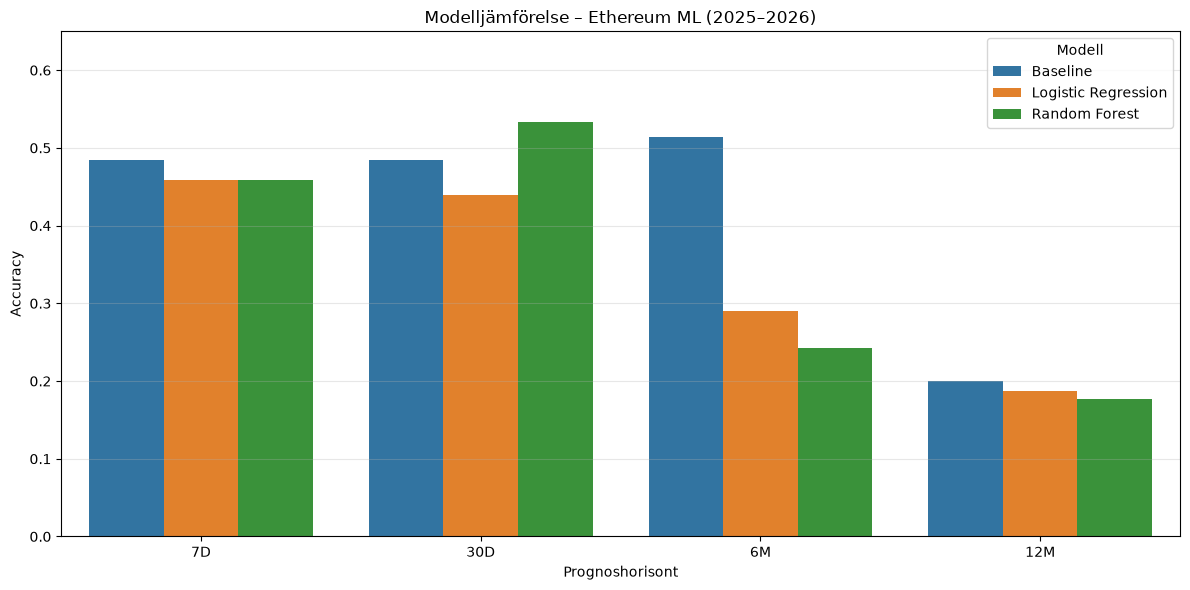

In [ ]:

# Steg 53 – Visualisera slutlig Accuracy

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_final_results,
    x="Horisont",
    y="Accuracy",
    hue="Modell",
    order=["7D", "30D", "6M", "12M"]
)

plt.title("Modelljämförelse – Ethereum ML (2025–2026)")
plt.xlabel("Prognoshorisont")
plt.ylabel("Accuracy")

plt.ylim(0, 0.65)
plt.legend(title="Modell")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Steg 54 – Visualisering av ML-prognoser över tid

Vi visualiserar Random Forest-modellens
förutsagda sannolikheter för positiv
Ethereum-avkastning efter 30 dagar.

Vi använder den senare utvärderingsperioden
2025–2026.

Syftet är att undersöka hur modellens
sannolikhetsprognoser förändras över tid.

Vi jämför prognoserna med de faktiska
framtida utfallen.

Diagrammet hjälper oss att identifiera
perioder då modellen varit mer eller
mindre säker på en framtida uppgång.

Resultaten är historiska modellprognoser,
inte rekommendationer om köp eller försäljning.


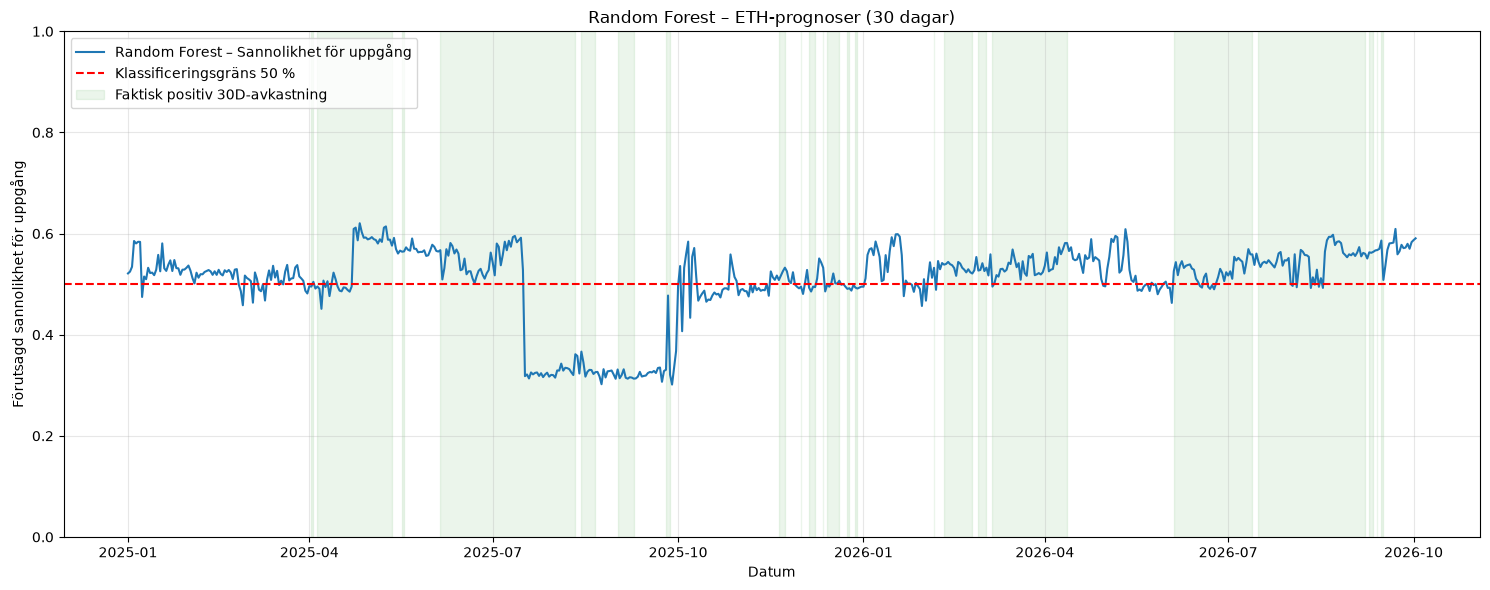

In [ ]:

# Steg 54 – Random Forest-prognoser över tid (30 dagar)

df_prob = df_ml_v3.copy()
df_prob = df_prob.sort_values("time").reset_index(drop=True)

# En dags förskjutning av features
df_prob[features_8] = df_prob[features_8].shift(1)

# Definiera målperiod
df_prob["target_end"] = (
    df_prob["time"] + pd.Timedelta(days=30)
)

# Behåll giltiga observationer
df_prob = df_prob.dropna(
    subset=features_8 + ["ETH_Up_30D"]
).copy()

eval_start = pd.Timestamp("2025-01-01", tz="UTC")

train_prob = df_prob[
    df_prob["target_end"] < eval_start
].copy()

eval_prob = df_prob[
    df_prob["time"] >= eval_start
].copy()

# Träna modellen på historiska data
rf_30d = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=50,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_30d.fit(
    train_prob[features_8],
    train_prob["ETH_Up_30D"].astype(int)
)

# Förutsagda sannolikheter
eval_prob["Probability_Up"] = rf_30d.predict_proba(
    eval_prob[features_8]
)[:, 1]

# Faktiska framtida utfall
eval_prob["Actual_Up"] = (
    eval_prob["ETH_Up_30D"].astype(int)
)

# Visualisering
plt.figure(figsize=(15, 6))

plt.plot(
    eval_prob["time"],
    eval_prob["Probability_Up"],
    label="Random Forest – Sannolikhet för uppgång",
    linewidth=1.5
)

plt.axhline(
    0.5,
    linestyle="--",
    color="red",
    label="Klassificeringsgräns 50 %"
)

plt.fill_between(
    eval_prob["time"],
    0,
    1,
    where=eval_prob["Actual_Up"] == 1,
    color="green",
    alpha=0.08,
    label="Faktisk positiv 30D-avkastning"
)

plt.title("Random Forest – ETH-prognoser (30 dagar)")
plt.xlabel("Datum")
plt.ylabel("Förutsagd sannolikhet för uppgång")
plt.ylim(0, 1)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Steg 55 – Probability Calibration

Vi undersöker hur väl Random Forest-modellens
förutsagda sannolikheter överensstämmer med
de faktiska framtida utfallen.

En modell som förutsäger 60 % sannolikhet
för uppgång bör, om den är välkalibrerad,
ha ungefär 60 % positiva utfall bland
liknande prognoser.

Vi delar in sannolikheterna i intervall
och beräknar:

- Antal prognoser per intervall.
- Genomsnittlig förutsagd sannolikhet.
- Faktisk andel positiva utfall.

Syftet är att undersöka om modellens
sannolikheter kan tolkas som tillförlitliga.

Eftersom 30-dagarsutfallen överlappar
varandra är observationerna inte oberoende.


,Probability_Bin,Antal,Predicted_Probability,Actual_Positive_Rate
0,"(0.3, 0.4]",75,0.325,0.600
1,"(0.4, 0.5]",124,0.487,0.315
2,"(0.5, 0.6]",433,0.543,0.508
3,"(0.6, 0.7]",8,0.611,0.750


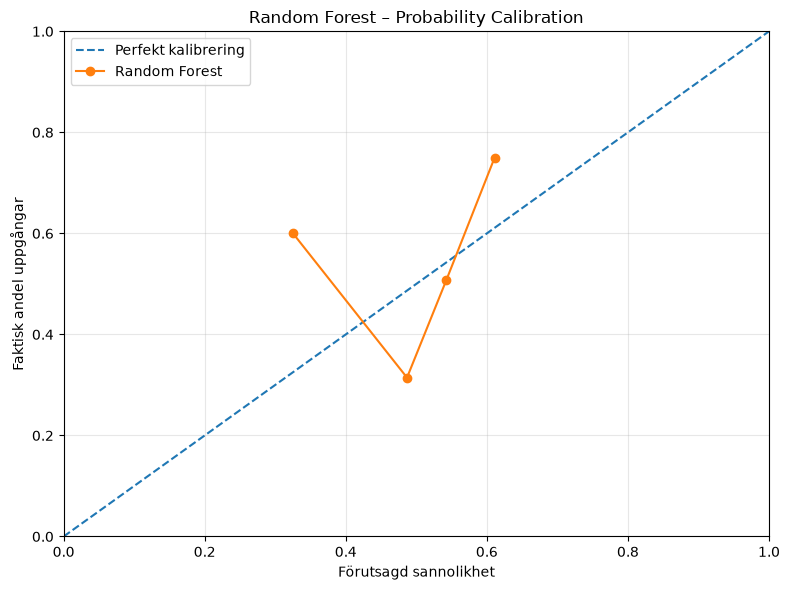

In [ ]:

# Steg 55 – Kontrollera sannolikhetskalibrering

# Skapa sannolikhetsintervall
bins = np.linspace(0, 1, 11)

df_calibration = eval_prob[
    ["Probability_Up", "Actual_Up"]
].copy()

df_calibration["Probability_Bin"] = pd.cut(
    df_calibration["Probability_Up"],
    bins=bins,
    include_lowest=True
)

# Sammanställ prognoser per intervall
calibration_results = (
    df_calibration.groupby(
        "Probability_Bin",
        observed=True
    )
    .agg(
        Antal=("Actual_Up", "count"),
        Predicted_Probability=("Probability_Up", "mean"),
        Actual_Positive_Rate=("Actual_Up", "mean")
    )
    .reset_index()
)

display(calibration_results.round(3))

# Kalibreringsdiagram
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfekt kalibrering"
)

plt.plot(
    calibration_results["Predicted_Probability"],
    calibration_results["Actual_Positive_Rate"],
    marker="o",
    label="Random Forest"
)

plt.title("Random Forest – Probability Calibration")
plt.xlabel("Förutsagd sannolikhet")
plt.ylabel("Faktisk andel uppgångar")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Steg 56 – Backtesting av ML-baserad strategi

Vi undersöker om Random Forest-modellens prognoser
kan användas för att skapa en enkel handelsstrategi.

Strategin jämförs med Buy & Hold för Ethereum.

Vi använder:
- Startkapital: 10 000 USD.
- Random Forest med 30 dagars prognoshorisont.
- Investerad i ETH vid förutsagd uppgång.
- Kontanter vid förutsagd nedgång.
- Transaktionskostnad: 0,1 % per positionsändring.

Vi använder en dags förskjutning av handelssignalen
så att dagens prisförändring inte kan påverka
en position som redan skulle ha varit bestämd.

Vi jämför:
- Slutvärde.
- Total avkastning.
- Maximal drawdown.
- Antal positionsändringar.

Backtestet är en historisk simulering med förenklade
antaganden om handel och transaktionskostnader.

Resultatet är inte en garanti för framtida avkastning.


Backtesting-resultat:


,Strategi,Slutvärde_USD,Total_Return_Pct,Max_Drawdown_Pct
0,Random Forest,11750.41,17.50,-59.66
1,Buy & Hold,7962.10,-20.38,-67.62



Antal positionsändringar:
82


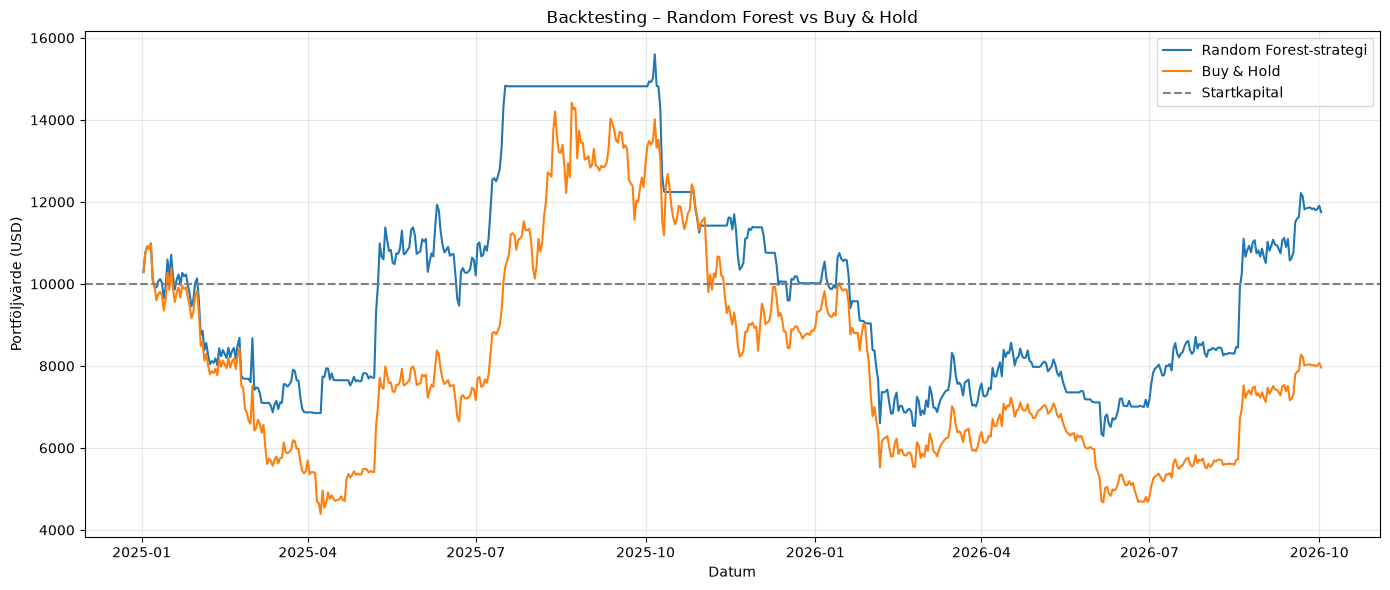

In [ ]:

# Steg 56 – Backtesting: Random Forest vs Buy & Hold

# Använd prognoserna från steg 54
df_backtest = eval_prob[
    ["time", "ETH_Price", "Probability_Up"]
].copy()

df_backtest = df_backtest.sort_values(
    "time"
).reset_index(drop=True)

# Daglig avkastning
df_backtest["Daily_Return"] = (
    df_backtest["ETH_Price"].pct_change(fill_method=None)
)

# Signal: investera om sannolikheten är minst 50 %
df_backtest["Signal"] = (
    df_backtest["Probability_Up"] >= 0.50
).astype(int)

# Använd föregående dags signal
df_backtest["Position"] = (
    df_backtest["Signal"].shift(1)
)

# Ta bort första dagen utan tidigare signal
df_backtest = df_backtest.dropna(
    subset=["Daily_Return", "Position"]
).copy()

# Transaktionskostnad: 0,1 % per positionsändring
transaction_cost = 0.001

df_backtest["Trade"] = (
    df_backtest["Position"]
    .diff()
    .abs()
    .fillna(0)
)

# Strategins dagliga nettoavkastning
df_backtest["Strategy_Return"] = (
    df_backtest["Position"] * df_backtest["Daily_Return"]
    - df_backtest["Trade"] * transaction_cost
)

# Buy & Hold
df_backtest["BuyHold_Return"] = (
    df_backtest["Daily_Return"]
)

# Simulera kapitalutveckling
initial_capital = 10000

df_backtest["Strategy_Value"] = (
    initial_capital *
    (1 + df_backtest["Strategy_Return"]).cumprod()
)

df_backtest["BuyHold_Value"] = (
    initial_capital *
    (1 + df_backtest["BuyHold_Return"]).cumprod()
)

# Beräkna maximal drawdown
def max_drawdown(values):
    peak = values.cummax()
    drawdown = values / peak - 1
    return drawdown.min() * 100

# Sammanställ resultat
backtest_results = pd.DataFrame({
    "Strategi": ["Random Forest", "Buy & Hold"],
    "Slutvärde_USD": [
        df_backtest["Strategy_Value"].iloc[-1],
        df_backtest["BuyHold_Value"].iloc[-1]
    ],
    "Total_Return_Pct": [
        (df_backtest["Strategy_Value"].iloc[-1]
         / initial_capital - 1) * 100,
        (df_backtest["BuyHold_Value"].iloc[-1]
         / initial_capital - 1) * 100
    ],
    "Max_Drawdown_Pct": [
        max_drawdown(df_backtest["Strategy_Value"]),
        max_drawdown(df_backtest["BuyHold_Value"])
    ]
})

print("Backtesting-resultat:")
display(backtest_results.round(2))

print("\nAntal positionsändringar:")
print(int(df_backtest["Trade"].sum()))

# Visualisera kapitalutvecklingen
plt.figure(figsize=(14, 6))

plt.plot(
    df_backtest["time"],
    df_backtest["Strategy_Value"],
    label="Random Forest-strategi"
)

plt.plot(
    df_backtest["time"],
    df_backtest["BuyHold_Value"],
    label="Buy & Hold"
)

plt.axhline(
    initial_capital,
    linestyle="--",
    color="gray",
    label="Startkapital"
)

plt.title("Backtesting – Random Forest vs Buy & Hold")
plt.xlabel("Datum")
plt.ylabel("Portföljvärde (USD)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Steg 57 – Förbättrad backtesting

Den första backtestingen visade att Random Forest-
strategin överträffade Buy & Hold under den
undersökta perioden.

Resultatet behöver dock kontrolleras med en
tydligare metod för positionshantering.

Vi behåller samma ML-modell och prognoser.

Vi definierar följande antaganden:

- Prognoserna baseras på tidigare tillgänglig data.
- Handelssignalen verkställs nästa handelsperiod.
- Strategin kan endast vara investerad eller i kontanter.
- Transaktionskostnaden är 0,1 % per affär.
- Vi inkluderar kostnad för den första positionen.
- Vi använder samma datum för strategi och Buy & Hold.

Vi beräknar:
- Total avkastning.
- Slutkapital.
- Maximal drawdown.
- Antal affärer.
- Andel dagar investerad.

Backtestet är en förenklad historisk simulering.
Vi har ännu inte verifierat exakta publiceringstider,
slippage eller möjliga handelstidpunkter.


Förbättrad backtesting:


,Strategi,Slutkapital,Avkastning (%),Max Drawdown (%)
0,Random Forest,11738.99,17.39,-59.66
1,Buy & Hold,7962.10,-20.38,-67.62



Antal affärer: 83
Andel dagar investerad: 68.75 %


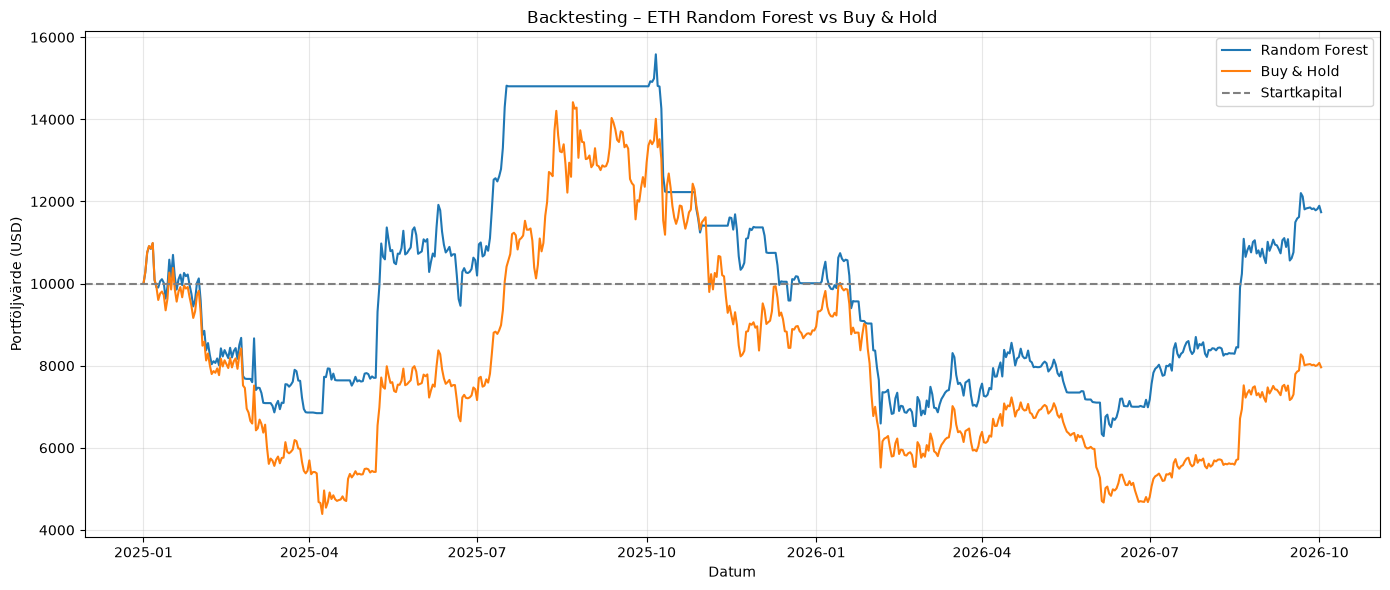

In [ ]:

# Steg 57 – Förbättrad backtesting

df_bt = eval_prob[
    ["time", "ETH_Price", "Probability_Up"]
].copy()

df_bt = df_bt.sort_values("time").reset_index(drop=True)

# Kontrollera sammanhängande dagliga observationer
assert df_bt["time"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all(), "Datumserien innehåller luckor."

# Daglig prisavkastning
df_bt["Daily_Return"] = df_bt["ETH_Price"].pct_change(
    fill_method=None
)

# Prognossignal vid slutet av respektive dag
df_bt["Signal"] = (
    df_bt["Probability_Up"] >= 0.50
).astype(int)

# Signalen används för nästa dags avkastning
df_bt["Position"] = df_bt["Signal"].shift(1).fillna(0).astype(int)

# Antal affärer: förändring från föregående position
df_bt["Trade"] = (
    df_bt["Position"].diff()
    .abs()
    .fillna(df_bt["Position"])
)

# Transaktionskostnad
cost = 0.001

# Strategiavkastning
df_bt["Strategy_Return"] = (
    df_bt["Position"] * df_bt["Daily_Return"].fillna(0)
    - df_bt["Trade"] * cost
)

# Buy & Hold – investera från första dagen
df_bt["BuyHold_Return"] = (
    df_bt["Daily_Return"].fillna(0)
)

# Beräkna kapitalutveckling
capital = 10000

df_bt["Strategy_Value"] = (
    capital * (1 + df_bt["Strategy_Return"]).cumprod()
)

df_bt["BuyHold_Value"] = (
    capital * (1 + df_bt["BuyHold_Return"]).cumprod()
)

def calculate_drawdown(values, initial_capital=10000):
    running_peak = values.cummax().clip(lower=initial_capital)
    return ((values / running_peak) - 1).min() * 100

# Resultattabell
df_bt_results = pd.DataFrame({
    "Strategi": ["Random Forest", "Buy & Hold"],
    "Slutkapital": [
        df_bt["Strategy_Value"].iloc[-1],
        df_bt["BuyHold_Value"].iloc[-1]
    ],
    "Avkastning (%)": [
        (df_bt["Strategy_Value"].iloc[-1] / capital - 1) * 100,
        (df_bt["BuyHold_Value"].iloc[-1] / capital - 1) * 100
    ],
    "Max Drawdown (%)": [
        calculate_drawdown(df_bt["Strategy_Value"]),
        calculate_drawdown(df_bt["BuyHold_Value"])
    ]
})

print("Förbättrad backtesting:")
display(df_bt_results.round(2))

print("\nAntal affärer:", int(df_bt["Trade"].sum()))
print("Andel dagar investerad:",
      round(df_bt["Position"].mean() * 100, 2), "%")

# Visualisering
plt.figure(figsize=(14, 6))

plt.plot(df_bt["time"], df_bt["Strategy_Value"],
         label="Random Forest")
plt.plot(df_bt["time"], df_bt["BuyHold_Value"],
         label="Buy & Hold")

plt.axhline(capital, linestyle="--",
            color="gray", label="Startkapital")

plt.title("Backtesting – ETH Random Forest vs Buy & Hold")
plt.xlabel("Datum")
plt.ylabel("Portföljvärde (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Steg 58 – Installera Streamlit och Plotly

%pip install streamlit plotly joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



### Steg 66 – Interaktiv trendanalys i Streamlit

Vi utvecklar appens flik för trendanalys.

Vi använder tidigare beräknade variabler från
vår historiska dataset:

- ETH/BTC Ratio
- Rolling Regression (365 dagar)
- Trend_Zone
- Breakdown
- Trend_Distance_Pct

Syftet är att visualisera hur Ethereum utvecklas
relativt Bitcoin och identifiera historiska
avvikelser från den dynamiska trendkanalen.

Vi använder Plotly för interaktiv visualisering
med datumfilter, zoom och markerade trendbrott.

Trendkanalen är en beskrivande teknisk indikator
och innebär inte att framtida prisutveckling
kan förutsägas med säkerhet.



### Steg 67 – Exportera trendkanalens övre och nedre band

Vi kompletterar vår historiska dataset med
de övre och nedre banden från vår tidigare
Rolling Regression.

Trendbanden är beräknade utifrån de senaste
365 dagarnas historiska ETH/BTC-värden.

Vi använder samma beräkningar som tidigare
för att säkerställa att visualiseringarna
i Jupyter Notebook och Streamlit överensstämmer.

Syftet är att skapa ett komplett interaktivt
trenddiagram med en dynamisk regressionskanal.

Den befintliga maskininlärningsmodellen
ändras inte.


In [ ]:

# Steg 67 – Exportera kompletta trendband

# Kontrollera att trendbanden finns
required = ["time", "Upper_Band", "Lower_Band"]

assert all(
    col in df_rolling.columns for col in required
), "Trendbanden saknas i df_rolling."

# Utgå från den sparade versionen av ML-datasetet
# som Streamlit använder
from pathlib import Path

csv_path = data_folder / "crypto_ml_with_trends.csv"

df_export = pd.read_csv(csv_path)
df_export["time"] = pd.to_datetime(
    df_export["time"], utc=True
)

# Ta bort eventuella gamla band före sammanslagning
df_export = df_export.drop(
    columns=["Upper_Band", "Lower_Band"],
    errors="ignore"
)

# Lägg till ursprungliga regressionsband
df_export = df_export.merge(
    df_rolling[required],
    on="time",
    how="left",
    validate="one_to_one"
)

# Spara uppdaterad CSV
df_export.to_csv(csv_path, index=False)

print("Datasetets storlek:", df_export.shape)

print("\nSaknade värden:")
print(df_export[["Upper_Band", "Lower_Band"]].isna().sum())

print("\nSenaste trendband:")
display(
    df_export[
        ["time", "Upper_Band", "Lower_Band"]
    ].tail(5).round(5)
)


Datasetets storlek: (3592, 40)

Saknade värden:
Upper_Band    364
Lower_Band    364
dtype: int64

Senaste trendband:


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1855249074.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(5)


,time,Upper_Band,Lower_Band
3587,2026-10-28 00:00:00+00:00,0.03056,0.02676
3588,2026-10-29 00:00:00+00:00,0.03056,0.02677
3589,2026-10-30 00:00:00+00:00,0.03056,0.02678
3590,2026-10-31 00:00:00+00:00,0.03057,0.02679
3591,2026-11-01 00:00:00+00:00,0.03057,0.02680



### Steg 69 – Exportera ML-resultat till Streamlit

Vi exporterar våra tidigare modellresultat
för att kunna visualisera dem i Streamlit.

Vi jämför:
- Baseline
- Logistic Regression
- Random Forest

Vi använder fyra prognoshorisonter:
7 dagar, 30 dagar, 6 månader och 12 månader.

Resultaten kommer från den kronologiska
utvärderingsperioden 2025–2026.

Vi tränar inte om modellerna i appen.
Det minskar risken för att modellresultaten
ändras vid varje körning.

Resultaten är historiska och ska inte
tolkas som verifierad framtida prognosförmåga.


In [ ]:

# Steg 69 – Exportera tidigare ML-resultat

from pathlib import Path

# Kontrollera att resultatet finns
assert "df_final_results" in globals(), (
    "Kör först steg 52 för att skapa df_final_results."
)

# Kontrollera kolumner
required = [
    "Horisont", "Modell", "Observationer",
    "Accuracy", "Balanced Accuracy",
    "F1", "ROC-AUC"
]

assert all(
    col in df_final_results.columns for col in required
), "Nödvändiga resultatkolumner saknas."

# Exportera till data-mappen
export_path = data_folder / "ml_model_results.csv"

df_final_results.to_csv(
    export_path,
    index=False
)

print("ML-resultat sparade:", export_path)
print("Antal modeller och horisonter:", len(df_final_results))

display(df_final_results.round(4))


ML-resultat sparade: data\ml_model_results.csv
Antal modeller och horisonter: 12


,Horisont,Modell,Observationer,Accuracy,Balanced Accuracy,F1,ROC-AUC
0,7D,Baseline,663,0.4842,0.5000,0.6524,0.5000
1,7D,Logistic Regression,663,0.4585,0.4602,0.4790,0.4537
2,7D,Random Forest,663,0.4585,0.4691,0.5897,0.4741
3,30D,Baseline,640,0.4844,0.5000,0.6526,0.5000
4,30D,Logistic Regression,640,0.4391,0.4382,0.4144,0.4235
5,30D,Random Forest,640,0.5328,0.5388,0.6019,0.5560
6,6M,Baseline,486,0.5144,0.5000,0.6793,0.5000
7,6M,Logistic Regression,486,0.2901,0.2847,0.4062,0.2266
8,6M,Random Forest,486,0.2428,0.2387,0.3405,0.1690
9,12M,Baseline,305,0.2000,0.5000,0.3333,0.5000



### Steg 70 – Exportera backtesting till Streamlit

Vi exporterar resultaten från vår historiska
backtesting av Random Forest och Buy & Hold.

Vi använder den tidigare beräknade
kapitalutvecklingen för båda strategierna.

Vi presenterar:
- Startkapital
- Slutkapital
- Total avkastning
- Maximal drawdown
- Antal affärer
- Andel dagar investerad

Backtestingen baseras på historiska prognoser
med en 30-dagars prognoshorisont.

Resultatet är en förenklad historisk simulering
och ska inte tolkas som verifierad framtida
lönsamhet eller investeringsrådgivning.

Vi ändrar inte ML-modellens parametrar.


In [ ]:

# Steg 70 – Exportera backtesting

from pathlib import Path

required_columns = [
    "time",
    "ETH_Price",
    "Probability_Up",
    "Position",
    "Trade",
    "Strategy_Value",
    "BuyHold_Value"
]

assert all(
    col in df_bt.columns for col in required_columns
), "Backtesting-kolumner saknas. Kör steg 57 först."

# Exportera resultat
export_columns = required_columns

backtest_export = df_bt[export_columns].copy()

backtest_path = data_folder / "crypto_backtest_results.csv"

backtest_export.to_csv(
    backtest_path,
    index=False
)

print("Backtesting exporterad till:", backtest_path)
print("Antal observationer:", len(backtest_export))

display(backtest_export.tail(5).round(2))


Backtesting exporterad till: data\crypto_backtest_results.csv
Antal observationer: 640


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\2378132690.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(backtest_export.tail(5).round(2))


,time,ETH_Price,Probability_Up,Position,Trade,Strategy_Value,BuyHold_Value
635,2026-09-28 00:00:00+00:00,2689.04,0.58,1,0.0,11831.50,8024.85
636,2026-09-29 00:00:00+00:00,2678.64,0.57,1,0.0,11785.75,7993.82
637,2026-09-30 00:00:00+00:00,2686.06,0.58,1,0.0,11818.41,8015.97
638,2026-10-01 00:00:00+00:00,2703.60,0.59,1,0.0,11895.58,8068.31
639,2026-10-02 00:00:00+00:00,2668.01,0.59,1,0.0,11738.99,7962.10



### Steg 73 – Förberedelse för API-uppdatering

Vi kompletterar vår Streamlit-app med
uppdaterade marknadsdata från Coin Metrics API.

Vi skiljer mellan två typer av data:

1. Historiska CSV-data som används för statistisk
   analys, modellträning och backtesting.

2. Senaste tillgängliga API-data som används
   för att visa aktuella marknadsobservationer.

Syftet är att göra appen mer användbar utan
att ändra våra tidigare ML-resultat.

API-data ska förses med datum och tid,
så att användaren kan se när observationen gjordes.

Vi behåller den befintliga modellversionen
oförändrad och tränar inte om modellerna
automatiskt.



### Steg 74 – Hämta uppdaterade kryptopriser via API

Vi kompletterar vårt Machine Learning-projekt
med uppdaterad marknadsdata från Coin Metrics API.

Vi använder Coin Metrics Community API för att
hämta de senaste tillgängliga dagliga priserna för:

- Ethereum (ETH)
- Bitcoin (BTC)

Vi använder variabeln PriceUSD.

Syftet är att kontrollera API-anslutningen och
undersöka hur vi kan använda nya marknadsdata
i vår Streamlit-app.

Vi behåller historiska data, tränade modeller
och backtestingresultat oförändrade.

API-observationerna ska märkas med datum
eftersom dagliga priser inte är realtidskurser.


In [ ]:

# Steg 74 – Testa Coin Metrics API

import requests
import pandas as pd

# Coin Metrics Community API
url = (
    "https://community-api.coinmetrics.io"
    "/v4/timeseries/asset-metrics"
)

# Parametrar
params = {
    "assets": "btc,eth",
    "metrics": "PriceUSD",
    "frequency": "1d",
    "limit_per_asset": 5,
    "paging_from": "end"
}

try:
    # Skicka API-anrop
    response = requests.get(
        url,
        params=params,
        timeout=30
    )

    print("HTTP-status:", response.status_code)

    # Kontrollera att anropet lyckades
    response.raise_for_status()

    # Läs JSON
    api_data = response.json()

    # Omvandla till DataFrame
    df_api_latest = pd.DataFrame(api_data["data"])

    # Konvertera datatyper
    df_api_latest["time"] = pd.to_datetime(
        df_api_latest["time"],
        utc=True
    )

    df_api_latest["PriceUSD"] = pd.to_numeric(
        df_api_latest["PriceUSD"],
        errors="coerce"
    )

    # Sortera efter kryptovaluta och datum
    df_api_latest = df_api_latest.sort_values(
        ["asset", "time"]
    ).reset_index(drop=True)

    print("\nAntal observationer:", len(df_api_latest))

    print("\nSenaste API-observationer:")
    display(df_api_latest)

    # Visa senaste pris för varje kryptovaluta
    latest_prices = (
        df_api_latest
        .groupby("asset")
        .tail(1)
    )

    print("\nSenaste tillgängliga priser:")
    display(latest_prices)

except requests.exceptions.RequestException as e:
    print("Fel vid API-anrop:", e)

except (KeyError, ValueError) as e:
    print("Fel vid bearbetning av API-data:", e)


HTTP-status: 200

Antal observationer: 10

Senaste API-observationer:


,asset,time,PriceUSD
0,btc,2026-10-30 00:00:00+00:00,77109.590747
1,btc,2026-10-31 00:00:00+00:00,77401.017287
2,btc,2026-11-01 00:00:00+00:00,78135.080289
3,btc,2026-11-02 00:00:00+00:00,76680.749130
4,btc,2026-11-03 00:00:00+00:00,77655.737678
5,eth,2026-10-30 00:00:00+00:00,2240.229980
6,eth,2026-10-31 00:00:00+00:00,2252.073358
7,eth,2026-11-01 00:00:00+00:00,2269.988406
8,eth,2026-11-02 00:00:00+00:00,2249.180254
9,eth,2026-11-03 00:00:00+00:00,2282.413501



Senaste tillgängliga priser:


,asset,time,PriceUSD
4,btc,2026-11-03 00:00:00+00:00,77655.737678
9,eth,2026-11-03 00:00:00+00:00,2282.413501


In [88]:

# Kontrollera datum i de exporterade CSV-filerna

from pathlib import Path
import pandas as pd

for filename in [
    "crypto_historical_prices.csv",
    "crypto_ml_with_trends.csv"
]:
    path = Path("data") / filename
    data = pd.read_csv(path, usecols=["time"])
    dates = pd.to_datetime(data["time"], utc=True)

    print(f"\n{filename}")
    print("Första datum:", dates.min())
    print("Sista datum:", dates.max())
    print("Antal observationer:", len(data))



crypto_historical_prices.csv
Första datum: 2015-01-01 00:00:00+00:00
Sista datum: 2026-11-01 00:00:00+00:00
Antal observationer: 4323

crypto_ml_with_trends.csv
Första datum: 2017-01-01 00:00:00+00:00
Sista datum: 2026-11-01 00:00:00+00:00
Antal observationer: 3592


In [89]:

# Steg 77 – Kontrollera historiska dataset

import pandas as pd
from pathlib import Path

data_path = Path("data")

files = [
    "crypto_historical_prices.csv",
    "crypto_features_cleaned.csv",
    "crypto_features_with_volume.csv",
    "crypto_features_with_sentiment.csv",
    "crypto_features_with_macro.csv",
    "crypto_full_dataset.csv",
    "crypto_ml_with_trends.csv"
]

results = []

for filename in files:

    path = data_path / filename

    if not path.exists():
        print(f"Filen saknas: {filename}")
        continue

    df_check = pd.read_csv(path)

    df_check["time"] = pd.to_datetime(
        df_check["time"],
        utc=True
    )

    results.append({
        "Dataset": filename,
        "Första datum": df_check["time"].min().date(),
        "Sista datum": df_check["time"].max().date(),
        "Observationer": len(df_check),
        "Kolumner": len(df_check.columns)
    })

df_check_results = pd.DataFrame(results)

display(df_check_results)


,Dataset,Första datum,Sista datum,Observationer,Kolumner
0,crypto_historical_prices.csv,2015-01-01,2026-11-01,4323,3
1,crypto_features_cleaned.csv,2015-01-01,2026-11-01,4323,24
2,crypto_features_with_volume.csv,2015-01-01,2026-11-01,4323,21
3,crypto_features_with_sentiment.csv,2015-01-01,2026-11-01,4323,22
4,crypto_features_with_macro.csv,2015-01-01,2026-11-01,4323,27
5,crypto_full_dataset.csv,2015-01-01,2026-11-01,4323,9
6,crypto_ml_with_trends.csv,2017-01-01,2026-11-01,3592,40


In [90]:

# Steg 78 – Kontrollera prisdata från 2015

import pandas as pd

df_check = pd.read_csv(
    "data/crypto_historical_prices.csv"
)

df_check["time"] = pd.to_datetime(
    df_check["time"],
    utc=True
)

# Kontrollera priser och saknade värden
print("Saknade priser:")
print(df_check[["ETH_Price", "BTC_Price"]].isna().sum())

print("\nFörsta 10 observationerna:")
display(
    df_check[
        ["time", "ETH_Price", "BTC_Price"]
    ].head(10)
)

# Kontrollera första giltiga datum för varje valuta
for col in ["ETH_Price", "BTC_Price"]:

    valid = df_check[
        df_check[col].notna()
        & (df_check[col] > 0)
    ]

    print(
        f"\n{col} – första giltiga datum:",
        valid["time"].min()
    )

# Kontrollera 2015
df_2015 = df_check[
    df_check["time"].dt.year == 2015
]

print("\nObservationer under 2015:", len(df_2015))

display(
    df_2015[
        ["time", "ETH_Price", "BTC_Price"]
    ].describe()
)


Saknade priser:
ETH_Price    219
BTC_Price      0
dtype: int64

Första 10 observationerna:


,time,ETH_Price,BTC_Price
0,2015-01-01 00:00:00+00:00,NaN,314.776472
1,2015-01-02 00:00:00+00:00,NaN,315.942732
2,2015-01-03 00:00:00+00:00,NaN,285.647310
3,2015-01-04 00:00:00+00:00,NaN,263.334575
4,2015-01-05 00:00:00+00:00,NaN,275.003852
5,2015-01-06 00:00:00+00:00,NaN,287.549521
6,2015-01-07 00:00:00+00:00,NaN,297.535565
7,2015-01-08 00:00:00+00:00,NaN,284.342392
8,2015-01-09 00:00:00+00:00,NaN,292.501115
9,2015-01-10 00:00:00+00:00,NaN,276.230532



ETH_Price – första giltiga datum: 2015-08-08 00:00:00+00:00

BTC_Price – första giltiga datum: 2015-01-01 00:00:00+00:00

Observationer under 2015: 365


,ETH_Price,BTC_Price
count,146.000000,365.000000
mean,0.937608,272.880117
std,0.269302,59.182266
min,0.420000,175.637641
25%,0.801278,234.445803
50%,0.899992,249.058286
75%,1.035522,285.911026
max,1.884800,464.617872


In [91]:

# Steg 79 – Kontrollera befintliga trendvariabler

import pandas as pd

trend_columns = [
    "ETH_BTC_Ratio",
    "ETH_BTC_MA30",
    "ETH_BTC_MA200",
    "Rolling_Trend",
    "Upper_Band",
    "Lower_Band",
    "Trend_Zone",
    "Breakdown",
    "Trend_Distance_Pct"
]

# Läs befintlig trendfil
df_existing_trends = pd.read_csv(
    "data/crypto_ml_with_trends.csv"
)

print("Befintliga trendkolumner:")

for col in trend_columns:
    if col in df_existing_trends.columns:
        print(f"{col}: Finns")
    else:
        print(f"{col}: Saknas")

print("\nAntal observationer:",
      len(df_existing_trends))

# Kontrollera variabler i notebooken
print("\nBefintliga DataFrames:")

for name in [
    "df_features",
    "df_rolling",
    "df_ml_v3"
]:
    if name in globals():
        data = globals()[name]
        print(name, data.shape)
    else:
        print(name, "saknas")


Befintliga trendkolumner:
ETH_BTC_Ratio: Finns
ETH_BTC_MA30: Finns
ETH_BTC_MA200: Finns
Rolling_Trend: Finns
Upper_Band: Finns
Lower_Band: Finns
Trend_Zone: Finns
Breakdown: Finns
Trend_Distance_Pct: Finns

Antal observationer: 3592

Befintliga DataFrames:
df_features (4323, 27)
df_rolling (4323, 2)
df_ml_v3 (3592, 50)


In [92]:

# Steg 80 – Skapa uppdaterad ETH/BTC-historik

import pandas as pd
import numpy as np

# Läs uppdaterade historiska priser
df_trends_new = pd.read_csv(
    "data/crypto_historical_prices.csv"
)

df_trends_new["time"] = pd.to_datetime(
    df_trends_new["time"],
    utc=True
)

df_trends_new = df_trends_new.sort_values(
    "time"
).reset_index(drop=True)

# Kontrollera giltiga priser
df_trends_new["ETH_Price"] = (
    pd.to_numeric(df_trends_new["ETH_Price"], errors="coerce")
    .where(lambda s: s > 0)
)

df_trends_new["BTC_Price"] = (
    pd.to_numeric(df_trends_new["BTC_Price"], errors="coerce")
    .where(lambda s: s > 0)
)

# ETH/BTC-kvot
df_trends_new["ETH_BTC_Ratio"] = (
    df_trends_new["ETH_Price"]
    / df_trends_new["BTC_Price"]
)

# Glidande medelvärden
df_trends_new["ETH_BTC_MA30"] = (
    df_trends_new["ETH_BTC_Ratio"]
    .rolling(window=30, min_periods=30)
    .mean()
)

df_trends_new["ETH_BTC_MA200"] = (
    df_trends_new["ETH_BTC_Ratio"]
    .rolling(window=200, min_periods=200)
    .mean()
)

# Kontrollera resultatet
print("Antal observationer:", len(df_trends_new))

for col in [
    "ETH_BTC_Ratio",
    "ETH_BTC_MA30",
    "ETH_BTC_MA200"
]:
    first_valid = df_trends_new.loc[
        df_trends_new[col].notna(), "time"
    ].min()

    print(f"{col} – första giltiga datum: {first_valid}")

display(df_trends_new.tail(5).round(5))


Antal observationer: 4323
ETH_BTC_Ratio – första giltiga datum: 2015-08-08 00:00:00+00:00
ETH_BTC_MA30 – första giltiga datum: 2015-09-06 00:00:00+00:00
ETH_BTC_MA200 – första giltiga datum: 2016-02-23 00:00:00+00:00


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\2178936404.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_trends_new.tail(5).round(5))


,time,BTC_Price,ETH_Price,ETH_BTC_Ratio,ETH_BTC_MA30,ETH_BTC_MA200
4318,2026-10-28 00:00:00+00:00,81237.43783,2356.98851,0.02901,0.03019,0.02942
4319,2026-10-29 00:00:00+00:00,78193.42640,2256.03199,0.02885,0.03009,0.02941
4320,2026-10-30 00:00:00+00:00,77109.59075,2240.22998,0.02905,0.02999,0.02940
4321,2026-10-31 00:00:00+00:00,77401.01729,2252.07336,0.02910,0.02989,0.02939
4322,2026-11-01 00:00:00+00:00,78135.08029,2269.98841,0.02905,0.02981,0.02938



### Steg 81 – Dynamisk trendkanal från 2015

Vi beräknar en dynamisk regressionskanal för ETH/BTC
med hjälp av 365 dagars rullande logaritmisk regression.

För varje dag använder vi endast den senaste
historiska informationen.

Vi beräknar:

- Rolling_Trend
- Upper_Band
- Lower_Band

Trendkanalen visar den historiska utvecklingen
av Ethereum relativt Bitcoin.

Vi använder en standardavvikelse för att skapa
det övre och undre trendbandet.

De tidigare ML-modellerna och backtestingresultaten
ändras inte.


In [93]:

# Steg 81 – Dynamisk trendkanal (365 dagar)

import numpy as np
import pandas as pd

window = 365

# Kopiera vår uppdaterade historik
df_trend_365 = df_trends_new.copy()

# Logaritmera ETH/BTC-kvoten
ratio = df_trend_365["ETH_BTC_Ratio"]

log_ratio = np.log(ratio.where(ratio > 0))

rolling_trend = np.full(len(df_trend_365), np.nan)
upper_band = np.full(len(df_trend_365), np.nan)
lower_band = np.full(len(df_trend_365), np.nan)

x = np.arange(window)

# Beräkna rullande logaritmisk regression
for i in range(window - 1, len(df_trend_365)):

    y = log_ratio.iloc[
        i - window + 1:i + 1
    ].to_numpy()

    # Hoppa över fönster med saknade värden
    if not np.isfinite(y).all():
        continue

    # Linjär regression i logaritmisk skala
    slope, intercept = np.polyfit(x, y, 1)

    fitted = slope * x + intercept

    # Regressionens värde vid sista dagen
    trend_log = fitted[-1]

    # Residualernas standardavvikelse
    residual_std = np.std(y - fitted, ddof=1)

    rolling_trend[i] = np.exp(trend_log)
    upper_band[i] = np.exp(trend_log + residual_std)
    lower_band[i] = np.exp(trend_log - residual_std)

# Lägg till beräkningarna
df_trend_365["Rolling_Trend"] = rolling_trend
df_trend_365["Upper_Band"] = upper_band
df_trend_365["Lower_Band"] = lower_band

# Kontrollera resultat
print("Antal observationer:", len(df_trend_365))

print("\nFörsta giltiga trenddatum:")
print(
    df_trend_365.loc[
        df_trend_365["Rolling_Trend"].notna(),
        "time"
    ].min()
)

print("\nSaknade trendvärden:")
print(
    df_trend_365[
        ["Rolling_Trend", "Upper_Band", "Lower_Band"]
    ].isna().sum()
)

print("\nSenaste trendvärden:")
display(
    df_trend_365[
        ["time", "Rolling_Trend", "Upper_Band", "Lower_Band"]
    ].tail(5)
)


Antal observationer: 4323

Första giltiga trenddatum:
2016-08-06 00:00:00+00:00

Saknade trendvärden:
Rolling_Trend    583
Upper_Band       583
Lower_Band       583
dtype: int64

Senaste trendvärden:


,time,Rolling_Trend,Upper_Band,Lower_Band
4318,2026-10-28 00:00:00+00:00,0.028596,0.030558,0.026759
4319,2026-10-29 00:00:00+00:00,0.028601,0.030560,0.026768
4320,2026-10-30 00:00:00+00:00,0.028607,0.030563,0.026777
4321,2026-10-31 00:00:00+00:00,0.028615,0.030568,0.026787
4322,2026-11-01 00:00:00+00:00,0.028622,0.030572,0.026797



### Steg 82 – Validering av uppdaterad trendkanal

Vi jämför den nya trendkanalen, som använder
historiska data från 2015, med den tidigare
trendkanalen som började 2017.

Vi kontrollerar:
- Rolling_Trend
- Upper_Band
- Lower_Band

Syftet är att verifiera att regressionsmetoden
är konsekvent innan den nya datan exporteras
till Streamlit.

Vi ändrar inte tidigare maskininlärningsmodeller
eller backtestingresultat.


In [94]:

# Steg 82 – Jämför gamla och nya trendberäkningar

import pandas as pd
import numpy as np

# Läs tidigare exporterad trenddata
df_old = pd.read_csv(
    "data/crypto_ml_with_trends.csv"
)

df_old["time"] = pd.to_datetime(
    df_old["time"],
    utc=True
)

# Välj trendkolumner
columns = [
    "time",
    "Rolling_Trend",
    "Upper_Band",
    "Lower_Band"
]

# Slå ihop på datum
comparison = df_old[columns].merge(
    df_trend_365[columns],
    on="time",
    how="inner",
    suffixes=("_Old", "_New"),
    validate="one_to_one"
)

# Beräkna absolut skillnad
for col in [
    "Rolling_Trend",
    "Upper_Band",
    "Lower_Band"
]:
    comparison[f"{col}_Diff"] = (
        comparison[f"{col}_New"]
        - comparison[f"{col}_Old"]
    ).abs()

print("Antal jämförbara datum:", len(comparison))

print("\nMaximal absolut skillnad:")

for col in [
    "Rolling_Trend",
    "Upper_Band",
    "Lower_Band"
]:
    print(
        col,
        comparison[f"{col}_Diff"].max()
    )

print("\nSenaste jämförelsen:")

display(
    comparison[
        [
            "time",
            "Rolling_Trend_Old",
            "Rolling_Trend_New",
            "Upper_Band_Old",
            "Upper_Band_New",
            "Lower_Band_Old",
            "Lower_Band_New"
        ]
    ].tail(5).round(6)
)


Antal jämförbara datum: 3592

Maximal absolut skillnad:
Rolling_Trend 2.4900139346251127e-09
Upper_Band 3.4365166198813135e-09
Lower_Band 1.8084470379542417e-09

Senaste jämförelsen:


C:\Users\milen\AppData\Local\Temp\ipykernel_15940\1622294167.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(6)


,time,Rolling_Trend_Old,Rolling_Trend_New,Upper_Band_Old,Upper_Band_New,Lower_Band_Old,Lower_Band_New
3587,2026-10-28 00:00:00+00:00,0.028596,0.028596,0.030558,0.030558,0.026759,0.026759
3588,2026-10-29 00:00:00+00:00,0.028601,0.028601,0.030560,0.030560,0.026768,0.026768
3589,2026-10-30 00:00:00+00:00,0.028607,0.028607,0.030563,0.030563,0.026777,0.026777
3590,2026-10-31 00:00:00+00:00,0.028615,0.028615,0.030568,0.030568,0.026787,0.026787
3591,2026-11-01 00:00:00+00:00,0.028622,0.028622,0.030572,0.030572,0.026797,0.026797


In [95]:

# Steg 83 – Exportera utökad trendhistorik

from pathlib import Path
import pandas as pd
import numpy as np

# Utgå från vår nya historik
df_trend_export = df_trend_365.copy()

# Läs tidigare trendbrott
df_old_trends = pd.read_csv(
    "data/crypto_ml_with_trends.csv"
)

df_old_trends["time"] = pd.to_datetime(
    df_old_trends["time"],
    utc=True
)

# Behåll de gamla klassificeringarna
old_signals = df_old_trends[
    ["time", "Trend_Zone", "Breakdown"]
].copy()

# Slå ihop med den nya historiken
df_trend_export = df_trend_export.merge(
    old_signals,
    on="time",
    how="left",
    validate="one_to_one"
)

# Beräkna avstånd till regressionslinjen
df_trend_export["Trend_Distance_Pct"] = (
    (
        df_trend_export["ETH_BTC_Ratio"]
        / df_trend_export["Rolling_Trend"]
    ) - 1
) * 100

# Exportera enbart trendanalysens kolumner
columns = [
    "time",
    "ETH_Price",
    "BTC_Price",
    "ETH_BTC_Ratio",
    "ETH_BTC_MA30",
    "ETH_BTC_MA200",
    "Rolling_Trend",
    "Upper_Band",
    "Lower_Band",
    "Trend_Zone",
    "Breakdown",
    "Trend_Distance_Pct"
]

df_trend_export = df_trend_export[columns]

# Spara separat CSV-fil
output_path = Path("data/crypto_trends_2015.csv")

df_trend_export.to_csv(
    output_path,
    index=False
)

print("Export klar:", output_path)
print("Observationer:", len(df_trend_export))

print("\nFörsta giltiga trenddatum:")
print(
    df_trend_export.loc[
        df_trend_export["Rolling_Trend"].notna(),
        "time"
    ].min()
)

print("\nTidigare trendbrott:")
print(int(df_trend_export["Breakdown"].sum()))

print("\nSenaste observationer:")
display(df_trend_export.tail(5))


Export klar: data\crypto_trends_2015.csv
Observationer: 4323

Första giltiga trenddatum:
2016-08-06 00:00:00+00:00

Tidigare trendbrott:
57

Senaste observationer:


,time,ETH_Price,BTC_Price,ETH_BTC_Ratio,ETH_BTC_MA30,ETH_BTC_MA200,Rolling_Trend,Upper_Band,Lower_Band,Trend_Zone,Breakdown,Trend_Distance_Pct
4318,2026-10-28 00:00:00+00:00,2356.988509,81237.437826,0.029014,0.030194,0.029424,0.028596,0.030558,0.026759,0.0,0.0,1.461519
4319,2026-10-29 00:00:00+00:00,2256.031994,78193.426404,0.028852,0.030088,0.029414,0.028601,0.030560,0.026768,0.0,0.0,0.877174
4320,2026-10-30 00:00:00+00:00,2240.229980,77109.590747,0.029053,0.029985,0.029400,0.028607,0.030563,0.026777,0.0,0.0,1.555745
4321,2026-10-31 00:00:00+00:00,2252.073358,77401.017287,0.029096,0.029892,0.029389,0.028615,0.030568,0.026787,0.0,0.0,1.681961
4322,2026-11-01 00:00:00+00:00,2269.988406,78135.080289,0.029052,0.029808,0.029376,0.028622,0.030572,0.026797,0.0,0.0,1.501857


In [96]:

# Steg 86 – Beräkna och validera trendbrott

import numpy as np
import pandas as pd

df_trend_test = df_trend_export.copy()

# Kontrollera vilka datum som har giltiga trendband
valid = (
    df_trend_test["ETH_BTC_Ratio"].notna()
    & df_trend_test["Upper_Band"].notna()
    & df_trend_test["Lower_Band"].notna()
)

# Skapa trendzon
df_trend_test["Trend_Zone_New"] = np.nan

df_trend_test.loc[valid, "Trend_Zone_New"] = 0

df_trend_test.loc[
    valid
    & (
        df_trend_test["ETH_BTC_Ratio"]
        > df_trend_test["Upper_Band"]
    ),
    "Trend_Zone_New"
] = 1

df_trend_test.loc[
    valid
    & (
        df_trend_test["ETH_BTC_Ratio"]
        < df_trend_test["Lower_Band"]
    ),
    "Trend_Zone_New"
] = -1

# Ett trendbrott inträffar när kvoten går
# från zon 0 eller 1 till zon -1.
previous_zone = df_trend_test["Trend_Zone_New"].shift(1)

df_trend_test["Breakdown_New"] = np.where(
    valid
    & previous_zone.notna()
    & (previous_zone >= 0)
    & (df_trend_test["Trend_Zone_New"] == -1),
    1,
    0
)

# Saknade värden före första giltiga trendperiod
df_trend_test.loc[
    ~valid, ["Trend_Zone_New", "Breakdown_New"]
] = np.nan

# Jämför endast datum med gamla registrerade signaler
old_period = (
    df_trend_test["Trend_Zone"].notna()
    & df_trend_test["Breakdown"].notna()
    & valid
)

comparison = df_trend_test.loc[old_period].copy()

zone_matches = (
    comparison["Trend_Zone"]
    == comparison["Trend_Zone_New"]
)

breakdown_matches = (
    comparison["Breakdown"]
    == comparison["Breakdown_New"]
)

print("Antal jämförda observationer:", len(comparison))

print("\nÖverensstämmelse för trendzon:")
print(round(zone_matches.mean() * 100, 2), "%")

print("\nÖverensstämmelse för trendbrott:")
print(round(breakdown_matches.mean() * 100, 2), "%")

print("\nTidigare registrerade trendbrott:")
print(int(comparison["Breakdown"].sum()))

print("\nNya beräknade trendbrott under samma period:")
print(int(comparison["Breakdown_New"].sum()))

# Visa eventuella skillnader
differences = comparison.loc[
    ~zone_matches | ~breakdown_matches,
    [
        "time",
        "ETH_BTC_Ratio",
        "Lower_Band",
        "Upper_Band",
        "Trend_Zone",
        "Trend_Zone_New",
        "Breakdown",
        "Breakdown_New"
    ]
]

print("\nAntal avvikande observationer:", len(differences))

display(differences.head(15))

# Kontrollera de nya åren
new_period = df_trend_test[
    (df_trend_test["time"] < pd.Timestamp(
        "2017-01-01", tz="UTC"
    ))
    & valid
]

print("\nTrendbrott före 2017 enligt testregeln:")
print(int(new_period["Breakdown_New"].sum()))


Antal jämförda observationer: 3228

Överensstämmelse för trendzon:
100.0 %

Överensstämmelse för trendbrott:
100.0 %

Tidigare registrerade trendbrott:
57

Nya beräknade trendbrott under samma period:
57

Antal avvikande observationer: 0


,time,ETH_BTC_Ratio,Lower_Band,Upper_Band,Trend_Zone,Trend_Zone_New,Breakdown,Breakdown_New



Trendbrott före 2017 enligt testregeln:
3


In [97]:

# Steg 87 – Spara kompletta trendklassificeringar

from pathlib import Path
import pandas as pd

# Använd de verifierade beräkningarna från steg 86
df_trend_final = df_trend_test.copy()

# Ersätt gamla trendklassificeringar
df_trend_final["Trend_Zone"] = (
    df_trend_final["Trend_Zone_New"]
)

df_trend_final["Breakdown"] = (
    df_trend_final["Breakdown_New"]
)

# Ta bort tillfälliga kontrollkolumner
df_trend_final = df_trend_final.drop(
    columns=["Trend_Zone_New", "Breakdown_New"],
    errors="ignore"
)

# Kontrollera resultatet
print("Antal observationer:", len(df_trend_final))

print("Totalt antal trendbrott:",
      int(df_trend_final["Breakdown"].sum()))

print("Första giltiga trenddatum:")
print(
    df_trend_final.loc[
        df_trend_final["Rolling_Trend"].notna(),
        "time"
    ].min()
)

# Spara till Streamlit
output_path = Path("data/crypto_trends_2015.csv")

df_trend_final.to_csv(
    output_path,
    index=False
)

print("\nUppdaterad fil:", output_path)

# Visa trendbrott från 2016
breakdowns_2016 = df_trend_final[
    (df_trend_final["time"].dt.year == 2016)
    & (df_trend_final["Breakdown"] == 1)
]

display(
    breakdowns_2016[
        [
            "time",
            "ETH_BTC_Ratio",
            "Lower_Band",
            "Breakdown"
        ]
    ]
)


Antal observationer: 4323
Totalt antal trendbrott: 61
Första giltiga trenddatum:
2016-08-06 00:00:00+00:00

Uppdaterad fil: data\crypto_trends_2015.csv


,time,ETH_BTC_Ratio,Lower_Band,Breakdown
599,2016-08-22 00:00:00+00:00,0.018953,0.019227,1.0
611,2016-09-03 00:00:00+00:00,0.019812,0.021170,1.0
629,2016-09-21 00:00:00+00:00,0.023068,0.023074,1.0



## Steg 90 – Långsiktig trendanalys av Ethereum

### Syfte

Vi undersöker Ethereums långsiktiga prisutveckling
under perioden 2015–2026 med två tekniska indikatorer:

1. Simple Moving Average (SMA 200)
2. Bull Market Support Band (BMSB)

SMA 200 beräknar det genomsnittliga ETH-priset
under de senaste 200 dagarna.

Bull Market Support Band består av:

- 20 veckors Simple Moving Average (20W SMA)
- 21 veckors Exponential Moving Average (21W EMA)

Vi undersöker hur Ethereumpriset historiskt
har utvecklats i förhållande till indikatorerna.

Analysen är explorativ och används inte som
nya features i våra ML-modeller.

Indikatorerna beskriver historiska trender,
men bevisar inte framtida prognosförmåga.


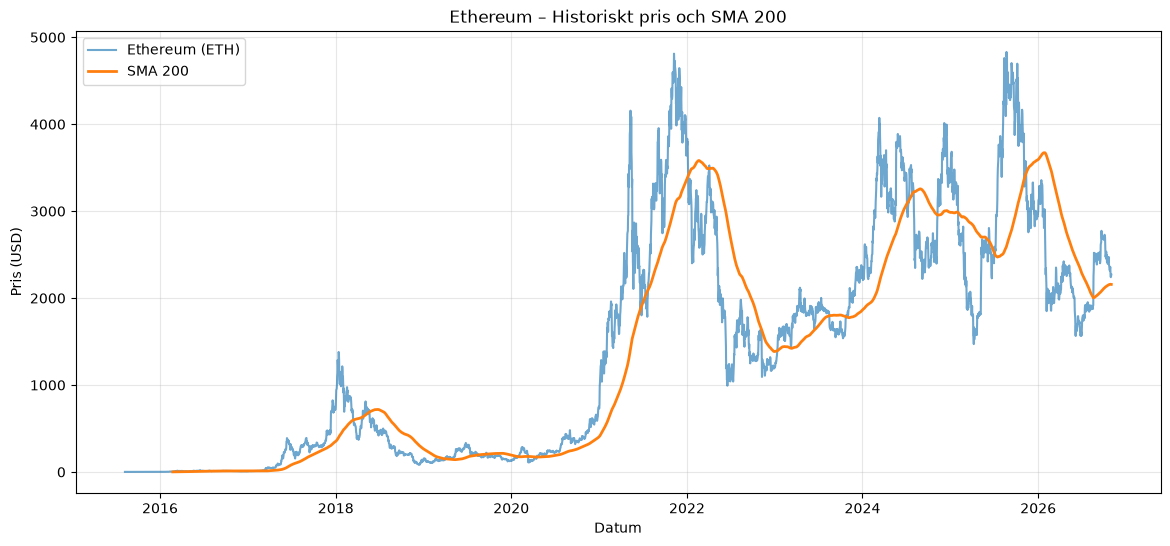

Saknade SMA 200-värden: 199
Första giltiga SMA 200: 2016-02-23 00:00:00+00:00


In [98]:

# Steg 90.2 – Ethereum SMA 200

import pandas as pd
import matplotlib.pyplot as plt

# Läs historiska priser
df_eth_eda = pd.read_csv(
    "data/crypto_historical_prices.csv"
)

df_eth_eda["time"] = pd.to_datetime(
    df_eth_eda["time"],
    utc=True
)

df_eth_eda = df_eth_eda.sort_values("time")

# Ta bort datum utan giltigt ETH-pris
df_eth_eda = df_eth_eda[
    df_eth_eda["ETH_Price"].notna()
    & (df_eth_eda["ETH_Price"] > 0)
].copy()

# Beräkna SMA 200
df_eth_eda["SMA_200"] = (
    df_eth_eda["ETH_Price"]
    .rolling(window=200, min_periods=200)
    .mean()
)

# Visa resultat
plt.figure(figsize=(14, 6))

plt.plot(
    df_eth_eda["time"],
    df_eth_eda["ETH_Price"],
    label="Ethereum (ETH)",
    alpha=0.65
)

plt.plot(
    df_eth_eda["time"],
    df_eth_eda["SMA_200"],
    label="SMA 200",
    linewidth=2
)

plt.title("Ethereum – Historiskt pris och SMA 200")
plt.xlabel("Datum")
plt.ylabel("Pris (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Saknade SMA 200-värden:",
    df_eth_eda["SMA_200"].isna().sum()
)

print(
    "Första giltiga SMA 200:",
    df_eth_eda.loc[
        df_eth_eda["SMA_200"].notna(), "time"
    ].min()
)


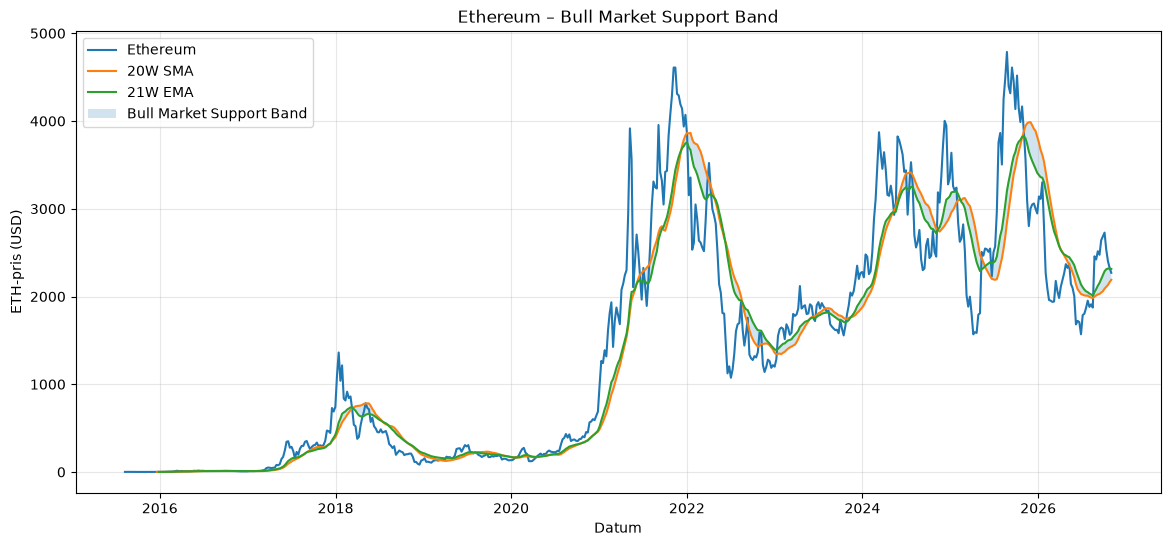

Antal veckor: 587
Saknade SMA 20W: 19
Saknade EMA 21W: 20


In [99]:

# Steg 90.3 – Bull Market Support Band

# Skapa veckovisa priser
df_eth_weekly = (
    df_eth_eda.set_index("time")["ETH_Price"]
    .resample("W-SUN")
    .last()
    .dropna()
    .to_frame()
)

# Beräkna 20 veckors SMA
df_eth_weekly["SMA_20W"] = (
    df_eth_weekly["ETH_Price"]
    .rolling(window=20, min_periods=20)
    .mean()
)

# Beräkna 21 veckors EMA
df_eth_weekly["EMA_21W"] = (
    df_eth_weekly["ETH_Price"]
    .ewm(
        span=21,
        adjust=False,
        min_periods=21
    )
    .mean()
)

# Bandets gränser
df_eth_weekly["Upper_Band"] = df_eth_weekly[
    ["SMA_20W", "EMA_21W"]
].max(axis=1)

df_eth_weekly["Lower_Band"] = df_eth_weekly[
    ["SMA_20W", "EMA_21W"]
].min(axis=1)

# Rita diagram
plt.figure(figsize=(14, 6))

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["ETH_Price"],
    label="Ethereum"
)

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["SMA_20W"],
    label="20W SMA"
)

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["EMA_21W"],
    label="21W EMA"
)

plt.fill_between(
    df_eth_weekly.index,
    df_eth_weekly["Lower_Band"],
    df_eth_weekly["Upper_Band"],
    alpha=0.2,
    label="Bull Market Support Band"
)

plt.title("Ethereum – Bull Market Support Band")
plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Antal veckor:", len(df_eth_weekly))

print(
    "Saknade SMA 20W:",
    df_eth_weekly["SMA_20W"].isna().sum()
)

print(
    "Saknade EMA 21W:",
    df_eth_weekly["EMA_21W"].isna().sum()
)


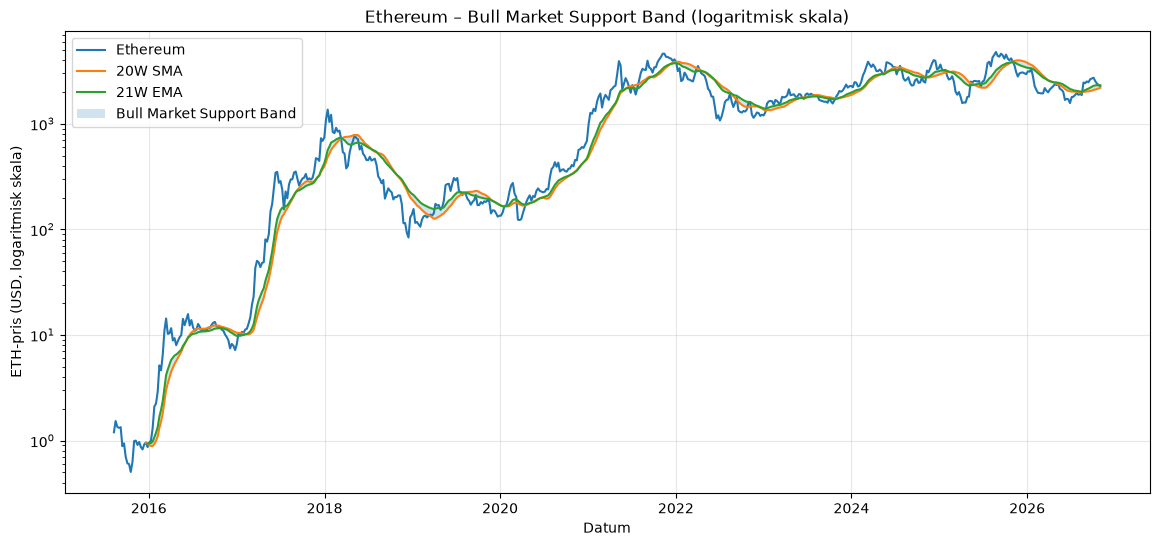

In [100]:

# Steg 90.4 – BMSB med logaritmisk skala

plt.figure(figsize=(14, 6))

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["ETH_Price"],
    label="Ethereum"
)

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["SMA_20W"],
    label="20W SMA"
)

plt.plot(
    df_eth_weekly.index,
    df_eth_weekly["EMA_21W"],
    label="21W EMA"
)

plt.fill_between(
    df_eth_weekly.index,
    df_eth_weekly["Lower_Band"],
    df_eth_weekly["Upper_Band"],
    alpha=0.2,
    label="Bull Market Support Band"
)

plt.yscale("log")

plt.title(
    "Ethereum – Bull Market Support Band "
    "(logaritmisk skala)"
)

plt.xlabel("Datum")
plt.ylabel("ETH-pris (USD, logaritmisk skala)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Resultat och slutsats

SMA 200 visar Ethereums långsiktiga prisutveckling
genom att jämna ut kortsiktiga prisvariationer.

Bull Market Support Band visualiserar ett intervall
mellan två veckobaserade trendindikatorer.

ETH-priset har historiskt rört sig både över och
under dessa indikatorer under olika marknadsperioder.

Den logaritmiska skalan gör det lättare att jämföra
relativa prisrörelser mellan 2015 och 2026.

Dessa indikatorer är användbara för att beskriva
historiska marknadsförhållanden, men vi har inte
visat att de förbättrar maskininlärningsmodellernas
prognosförmåga.

Vi behåller därför våra tidigare åtta ML-features
oförändrade för att undvika onödig modellkomplexitet.



## Steg 91 – Förberedelse av ML-data 2015–2026

Vi utökar analysperioden från 2017 till 2015.

Vi behåller samma åtta features som tidigare
för att minska risken för överträning.

Eftersom vissa indikatorer saknar historiska data
undersöker vi först vilka perioder som kan
användas för modellträning.

Vi skiljer mellan:

1. Fullständig prishistorik från 2015.
2. Perioder med tillgängliga ML-features.
3. Perioder med kända framtida utfall.

Vi ersätter inte historiskt saknade observationer
med syntetiska värden.

De tidigare ML-resultaten sparas separat
för att möjliggöra jämförelse.


In [104]:

# Steg 91 – Kontrollera tillgänglig ML-historik

import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("data")

# Läs det uppdaterade datasetet med marknadsvariabler
df_ml_new = pd.read_csv(
    DATA_DIR / "crypto_features_with_macro.csv"
)

df_ml_new["time"] = pd.to_datetime(
    df_ml_new["time"],
    utc=True
)

df_ml_new = df_ml_new.sort_values(
    "time"
).reset_index(drop=True)

# Läs den nya trendhistoriken
df_trend_new = pd.read_csv(
    DATA_DIR / "crypto_trends_2015.csv"
)

df_trend_new["time"] = pd.to_datetime(
    df_trend_new["time"],
    utc=True
)

# Lägg till trendavståndet
df_ml_new = df_ml_new.drop(
    columns=["Trend_Distance_Pct"],
    errors="ignore"
)

df_ml_new = df_ml_new.merge(
    df_trend_new[["time", "Trend_Distance_Pct"]],
    on="time",
    how="left",
    validate="one_to_one"
)

# Våra åtta utvalda features
ml_features = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "ETH_Volatility_30",
    "ETH_Volume_Change_7D",
    "BTC_Volume_Change_7D",
    "Fear_Greed_Index",
    "Trend_Distance_Pct"
]

# Kontrollera att variablerna finns
missing_columns = [
    col for col in ml_features
    if col not in df_ml_new.columns
]

print("Saknade featurekolumner:", missing_columns)

if missing_columns:
    raise ValueError(
        "Nödvändiga features saknas: "
        + ", ".join(missing_columns)
    )

# Kontrollera första giltiga datum
availability = []

for col in ml_features:

    valid = df_ml_new.loc[
        df_ml_new[col].notna(),
        "time"
    ]

    availability.append({
        "Feature": col,
        "Första giltiga datum": (
            valid.min() if not valid.empty else pd.NaT
        ),
        "Saknade värden": df_ml_new[col].isna().sum()
    })

availability_df = pd.DataFrame(availability)

print("\nFeature-tillgänglighet:")
display(availability_df)

# Kontrollera fullständiga observationer
complete_rows = df_ml_new.dropna(
    subset=ml_features
).copy()

print("\nTotalt antal observationer:", len(df_ml_new))
print("Kompletta observationer:", len(complete_rows))

if not complete_rows.empty:
    print(
        "Första kompletta datum:",
        complete_rows["time"].min()
    )
    print(
        "Sista kompletta datum:",
        complete_rows["time"].max()
    )

# Fördelning per år
year_counts = (
    complete_rows.groupby(
        complete_rows["time"].dt.year
    )
    .size()
    .reset_index(name="Kompletta observationer")
    .rename(columns={"time": "År"})
)

print("\nKompletta ML-observationer per år:")
display(year_counts)


Saknade featurekolumner: ['ETH_Volume_Change_7D', 'BTC_Volume_Change_7D']


ValueError: Nödvändiga features saknas: ETH_Volume_Change_7D, BTC_Volume_Change_7D

In [102]:

# Steg 91.1 – Återskapa saknade volymvariabler

import pandas as pd
import numpy as np

# Kontrollera om handelsvolymer finns i datasetet
volume_columns = [
    "ETH_Volume_USD",
    "BTC_Volume_USD"
]

missing_volume = [
    col for col in volume_columns
    if col not in df_ml_new.columns
]

if missing_volume:
    raise ValueError(
        "Handelsvolymer saknas: "
        + ", ".join(missing_volume)
    )

# Säkerställ att data är sorterad
df_ml_new = df_ml_new.sort_values(
    "time"
).reset_index(drop=True)

# Beräkna procentuell volymförändring över 7 dagar
for asset in ["ETH", "BTC"]:

    source = f"{asset}_Volume_USD"
    target = f"{asset}_Volume_Change_7D"

    volume = pd.to_numeric(
        df_ml_new[source],
        errors="coerce"
    )

    # Undvik division med noll och ogiltiga värden
    volume = volume.where(volume > 0)

    df_ml_new[target] = (
        volume.pct_change(
            periods=7,
            fill_method=None
        ) * 100
    )

# Kontrollera resultatet
print("Saknade värden:")

print(
    df_ml_new[
        [
            "ETH_Volume_Change_7D",
            "BTC_Volume_Change_7D"
        ]
    ].isna().sum()
)

print("\nSenaste observationerna:")

display(
    df_ml_new[
        [
            "time",
            "ETH_Volume_Change_7D",
            "BTC_Volume_Change_7D"
        ]
    ].tail(10)
)


Saknade värden:
ETH_Volume_Change_7D    738
BTC_Volume_Change_7D    738
dtype: int64

Senaste observationerna:


,time,ETH_Volume_Change_7D,BTC_Volume_Change_7D
4313,2026-10-23 00:00:00+00:00,-16.072852,-16.003989
4314,2026-10-24 00:00:00+00:00,59.449577,78.683502
4315,2026-10-25 00:00:00+00:00,-23.144171,-31.286615
4316,2026-10-26 00:00:00+00:00,13.775236,11.243194
4317,2026-10-27 00:00:00+00:00,-26.248145,-23.198674
4318,2026-10-28 00:00:00+00:00,-25.061866,-25.589191
4319,2026-10-29 00:00:00+00:00,56.963191,29.942312
4320,2026-10-30 00:00:00+00:00,110.110691,105.917426
4321,2026-10-31 00:00:00+00:00,-49.762057,-41.179322
4322,2026-11-01 00:00:00+00:00,-23.925425,-3.689402


In [106]:

# Steg 91.3 – Reparera och kontrollera ML-features

import pandas as pd
import numpy as np

# Kontrollera och återskapa volymvariabler vid behov
for asset in ["ETH", "BTC"]:

    source = f"{asset}_Volume_USD"
    target = f"{asset}_Volume_Change_7D"

    if target not in df_ml_new.columns:

        volume = pd.to_numeric(
            df_ml_new[source],
            errors="coerce"
        ).where(lambda s: s > 0)

        df_ml_new = df_ml_new.sort_values(
            "time"
        ).reset_index(drop=True)

        df_ml_new[target] = (
            volume.pct_change(
                periods=7,
                fill_method=None
            ) * 100
        )

# Våra åtta features
ml_features = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "ETH_Volatility_30",
    "ETH_Volume_Change_7D",
    "BTC_Volume_Change_7D",
    "Fear_Greed_Index",
    "Trend_Distance_Pct"
]

# Kontrollera kolumner
missing = [
    col for col in ml_features
    if col not in df_ml_new.columns
]

print("Saknade featurekolumner:", missing)

if missing:
    raise ValueError(
        f"Följande kolumner saknas: {missing}"
    )

# Kontrollera saknade värden
print("\nSaknade värden:")
print(df_ml_new[ml_features].isna().sum())

# Skapa komplett träningsunderlag
df_ml_complete = df_ml_new.dropna(
    subset=ml_features
).copy()

print("\nTotalt antal observationer:", len(df_ml_new))
print("Kompletta observationer:", len(df_ml_complete))

print("\nFörsta kompletta datum:")
print(df_ml_complete["time"].min())

print("\nSista kompletta datum:")
print(df_ml_complete["time"].max())

print("\nKompletta observationer per år:")

display(
    df_ml_complete.groupby(
        df_ml_complete["time"].dt.year
    ).size().rename("Antal")
)


Saknade featurekolumner: []

Saknade värden:
ETH_Return               220
BTC_Return                 1
ETH_RSI_14               233
ETH_Volatility_30        249
ETH_Volume_Change_7D     738
BTC_Volume_Change_7D     738
Fear_Greed_Index        1127
Trend_Distance_Pct       583
dtype: int64

Totalt antal observationer: 4323
Kompletta observationer: 3196

Första kompletta datum:
2018-02-01 00:00:00+00:00

Sista kompletta datum:
2026-11-01 00:00:00+00:00

Kompletta observationer per år:


time
2018    334
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
2025    365
2026    305
Name: Antal, dtype: int64


## Steg 92 – Skapa framtida målvariabler

Vi skapar fyra målvariabler för Ethereums
framtida prisutveckling:

- 7 dagar
- 30 dagar
- 180 dagar (6 månader)
- 365 dagar (12 månader)

Framtida avkastning beräknas från dagens ETH-pris
till ETH-priset vid respektive prognoshorisont.

Målvariabeln är binär:

1 = Positiv framtida avkastning
0 = Noll eller negativ framtida avkastning

Vi använder framtida priser endast för att
skapa utfallsvariabler, aldrig som ML-features.

De sista observationerna saknar framtida utfall
och exkluderas från träning och utvärdering.


In [107]:

# Steg 92 – Skapa framtida avkastning och målvariabler

import numpy as np
import pandas as pd

# Utgå från uppdaterad data
df_ml_targets_new = df_ml_new.copy()

df_ml_targets_new = df_ml_targets_new.sort_values(
    "time"
).reset_index(drop=True)

# Säkerställ giltigt ETH-pris
price = pd.to_numeric(
    df_ml_targets_new["ETH_Price"],
    errors="coerce"
).where(lambda s: s > 0)

# Våra fyra prognoshorisonter
horizons = {
    "7D": 7,
    "30D": 30,
    "6M": 180,
    "12M": 365
}

for label, days in horizons.items():

    future_price = price.shift(-days)

    # Framtida procentuell avkastning
    future_return = (
        (future_price / price) - 1
    ) * 100

    return_col = f"ETH_Future_Return_{label}"
    target_col = f"ETH_Up_{label}"

    df_ml_targets_new[return_col] = future_return

    # Behåll saknade framtida utfall som NA
    df_ml_targets_new[target_col] = (
        (future_return > 0)
        .where(future_return.notna())
        .astype("Int64")
    )

# Kontrollera resultat
print("Datasetets storlek:", df_ml_targets_new.shape)

print("\nSaknade framtida utfall:")

for label in horizons:

    target = f"ETH_Up_{label}"

    print(
        target,
        df_ml_targets_new[target].isna().sum()
    )

print("\nAndel positiva utfall:")

for label in horizons:

    target = f"ETH_Up_{label}"

    print(
        target,
        round(
            df_ml_targets_new[target].mean() * 100,
            2
        ),
        "%"
    )

print("\nSenaste observationerna:")

display(
    df_ml_targets_new[
        [
            "time",
            "ETH_Up_7D",
            "ETH_Up_30D",
            "ETH_Up_6M",
            "ETH_Up_12M"
        ]
    ].tail(10)
)


Datasetets storlek: (4323, 38)

Saknade framtida utfall:
ETH_Up_7D 226
ETH_Up_30D 249
ETH_Up_6M 399
ETH_Up_12M 584

Andel positiva utfall:
ETH_Up_7D 52.5 %
ETH_Up_30D 53.93 %
ETH_Up_6M 62.69 %
ETH_Up_12M 62.13 %

Senaste observationerna:


,time,ETH_Up_7D,ETH_Up_30D,ETH_Up_6M,ETH_Up_12M
4313,2026-10-23 00:00:00+00:00,0,<NA>,<NA>,<NA>
4314,2026-10-24 00:00:00+00:00,0,<NA>,<NA>,<NA>
4315,2026-10-25 00:00:00+00:00,0,<NA>,<NA>,<NA>
4316,2026-10-26 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4317,2026-10-27 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4318,2026-10-28 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4319,2026-10-29 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4320,2026-10-30 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4321,2026-10-31 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>
4322,2026-11-01 00:00:00+00:00,<NA>,<NA>,<NA>,<NA>



## Steg 93 – Kronologisk uppdelning utan informationsläckage

Vi delar upp våra data kronologiskt i:

- Träningsdata
- Valideringsdata
- Testdata

Vi använder endast de åtta tidigare utvalda
ML-variablerna.

Eftersom målvariablerna använder framtida
prisdata tillämpar vi en purged split.

Det innebär att träningsobservationer vars
framtida utfall når in i valideringsperioden
exkluderas.

Samma princip används mellan validering
och test.

Vi behåller testperioden helt separat för
att kunna bedöma modellens generalisering.


In [108]:

# Steg 93 – Kronologisk train/validation/test-split

import pandas as pd

# Samma åtta features som tidigare
ml_features = [
    "ETH_Return",
    "BTC_Return",
    "ETH_RSI_14",
    "ETH_Volatility_30",
    "ETH_Volume_Change_7D",
    "BTC_Volume_Change_7D",
    "Fear_Greed_Index",
    "Trend_Distance_Pct"
]

# Prognoshorisonter
horizons = {
    "7D": 7,
    "30D": 30,
    "6M": 180,
    "12M": 365
}

# Datumgränser
train_end = pd.Timestamp("2023-01-01", tz="UTC")
val_end = pd.Timestamp("2025-01-01", tz="UTC")

# Förbered fullständig tidsserie
df_split = df_ml_targets_new.copy()

df_split = df_split.sort_values(
    "time"
).reset_index(drop=True)

# Kontrollera daglig kontinuitet
assert df_split["time"].is_unique
assert (
    df_split["time"].diff().dropna()
    == pd.Timedelta(days=1)
).all(), "Datumserien innehåller luckor."

split_results = {}
split_summary = []

for label, days in horizons.items():

    target = f"ETH_Up_{label}"

    # Endast rader med giltiga features och target
    valid = df_split.dropna(
        subset=ml_features + [target]
    ).copy()

    # Datum då utfallet blir känt
    valid["Target_End"] = (
        valid["time"] + pd.Timedelta(days=days)
    )

    # Träning: utfallet måste vara känt före 2023
    train = valid[
        valid["Target_End"] < train_end
    ].copy()

    # Validering: observationer 2023–2024
    # Utfallet måste vara känt före testperioden
    validation = valid[
        (valid["time"] >= train_end)
        & (valid["Target_End"] < val_end)
    ].copy()

    # Test: från 2025, endast kända utfall
    test = valid[
        valid["time"] >= val_end
    ].copy()

    # Säkerställ att målvariablerna är binära
    for part in [train, validation, test]:
        part[target] = part[target].astype(int)

    split_results[label] = {
        "train": train,
        "validation": validation,
        "test": test
    }

    for name, part in [
        ("Training", train),
        ("Validation", validation),
        ("Test", test)
    ]:
        split_summary.append({
            "Horisont": label,
            "Dataset": name,
            "Observationer": len(part),
            "Första datum": (
                part["time"].min() if len(part) else pd.NaT
            ),
            "Sista datum": (
                part["time"].max() if len(part) else pd.NaT
            ),
            "Andel uppgång (%)": (
                round(part[target].mean() * 100, 2)
                if len(part) else None
            )
        })

df_split_summary = pd.DataFrame(split_summary)

display(df_split_summary)


,Horisont,Dataset,Observationer,Första datum,Sista datum,Andel uppgång (%)
0,7D,Training,1788,2018-02-01 00:00:00+00:00,2022-12-24 00:00:00+00:00,51.62
1,7D,Validation,724,2023-01-01 00:00:00+00:00,2024-12-24 00:00:00+00:00,53.04
2,7D,Test,663,2025-01-01 00:00:00+00:00,2026-10-25 00:00:00+00:00,48.42
3,30D,Training,1765,2018-02-01 00:00:00+00:00,2022-12-01 00:00:00+00:00,51.56
4,30D,Validation,701,2023-01-01 00:00:00+00:00,2024-12-01 00:00:00+00:00,55.21
5,30D,Test,640,2025-01-01 00:00:00+00:00,2026-10-02 00:00:00+00:00,48.44
6,6M,Training,1615,2018-02-01 00:00:00+00:00,2022-07-04 00:00:00+00:00,55.42
7,6M,Validation,551,2023-01-01 00:00:00+00:00,2024-07-04 00:00:00+00:00,67.70
8,6M,Test,490,2025-01-01 00:00:00+00:00,2026-05-05 00:00:00+00:00,50.82
9,12M,Training,1430,2018-02-01 00:00:00+00:00,2021-12-31 00:00:00+00:00,55.24



## Steg 94 – Träning av maskininlärningsmodeller

Vi tränar två klassificeringsmodeller:

1. Logistic Regression
2. Random Forest

Modellerna tränas på historiska observationer
med kända framtida utfall.

Vi använder åtta tidigare utvalda features
och jämför med en enkel baseline.

För att minska risken för överträning:

- Använder vi kronologisk uppdelning.
- Anpassas skalning endast på träningsdata.
- Begränsas Random Forest till låg komplexitet.
- Används valideringsdata för modelljämförelse.
- Hålls testdata utanför modellutvecklingen.

12-månadershorisonten utvärderas separat
eftersom valideringsperioden bara innehåller
en utfallsklass.


In [109]:

# Steg 94 – Träna och jämför modeller på valideringsdata

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

from sklearn.base import clone

# Våra tre första prognoshorisonter
selected_horizons = ["7D", "30D", "6M"]

models_94 = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=0.1,
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=30,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results_94 = []
trained_models_94 = {}

for horizon in selected_horizons:

    target = f"ETH_Up_{horizon}"

    train = split_results[horizon]["train"]
    validation = split_results[horizon]["validation"]

    X_train = train[ml_features]
    y_train = train[target].astype(int)

    X_val = validation[ml_features]
    y_val = validation[target].astype(int)

    # Baseline: vanligaste klass i träningsdata
    majority = int(y_train.mode().iloc[0])

    baseline_pred = np.full(
        len(y_val),
        majority
    )

    results_94.append({
        "Horisont": horizon,
        "Modell": "Baseline",
        "Accuracy": accuracy_score(
            y_val, baseline_pred
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, baseline_pred
        ),
        "F1": f1_score(
            y_val, baseline_pred, zero_division=0
        ),
        "ROC-AUC": 0.5
    })

    for name, estimator in models_94.items():

        model = clone(estimator)

        # Träna endast på träningsdata
        model.fit(X_train, y_train)

        # Utvärdera på valideringsdata
        predictions = model.predict(X_val)
        probabilities = model.predict_proba(X_val)[:, 1]

        auc = (
            roc_auc_score(y_val, probabilities)
            if y_val.nunique() == 2
            else np.nan
        )

        results_94.append({
            "Horisont": horizon,
            "Modell": name,
            "Accuracy": accuracy_score(
                y_val, predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": auc
        })

        trained_models_94[(horizon, name)] = model

df_results_94 = pd.DataFrame(results_94)

print("Valideringsresultat – Steg 94")

display(
    df_results_94.round(4)
)


Valideringsresultat – Steg 94


,Horisont,Modell,Accuracy,Balanced Accuracy,F1,ROC-AUC
0,7D,Baseline,0.5304,0.5000,0.6931,0.5000
1,7D,Logistic Regression,0.5152,0.5015,0.6139,0.4899
2,7D,Random Forest,0.5014,0.4905,0.5874,0.4706
3,30D,Baseline,0.5521,0.5000,0.7114,0.5000
4,30D,Logistic Regression,0.5278,0.5159,0.5958,0.5024
5,30D,Random Forest,0.5107,0.4881,0.6142,0.5016
6,6M,Baseline,0.6770,0.5000,0.8074,0.5000
7,6M,Logistic Regression,0.5517,0.4648,0.6821,0.3602
8,6M,Random Forest,0.4900,0.4633,0.5886,0.4310



## Steg 95 – Analys av överträning

Vi jämför modellernas resultat på träningsdata
och valideringsdata.

Syftet är att undersöka om modellerna har
lärt sig historiska mönster som inte fungerar
lika bra på nya observationer.

Vi använder samma modeller och samma åtta
features som i steg 94.

Vi undersöker:

- Accuracy
- Balanced Accuracy
- ROC-AUC
- Skillnaden mellan träning och validering

En stor skillnad mellan träningsresultat och
valideringsresultat kan indikera överträning.

Modellernas parametrar ändras inte.

Testperioden 2025–2026 används inte i detta steg.


In [110]:

# Steg 95 – Kontroll av överträning

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score
)

overfitting_results = []

for horizon in ["7D", "30D", "6M"]:

    target = f"ETH_Up_{horizon}"

    train = split_results[horizon]["train"]
    validation = split_results[horizon]["validation"]

    for model_name in [
        "Logistic Regression",
        "Random Forest"
    ]:

        # Hämta redan tränad modell från steg 94
        model = trained_models_94[
            (horizon, model_name)
        ]

        for dataset_name, dataset in [
            ("Training", train),
            ("Validation", validation)
        ]:

            X = dataset[ml_features]
            y = dataset[target].astype(int)

            predictions = model.predict(X)
            probabilities = model.predict_proba(X)[:, 1]

            auc = (
                roc_auc_score(y, probabilities)
                if y.nunique() == 2
                else np.nan
            )

            overfitting_results.append({
                "Horisont": horizon,
                "Modell": model_name,
                "Dataset": dataset_name,
                "Accuracy": accuracy_score(
                    y, predictions
                ),
                "Balanced Accuracy": balanced_accuracy_score(
                    y, predictions
                ),
                "ROC-AUC": auc
            })

df_overfitting_95 = pd.DataFrame(
    overfitting_results
)

print("Träning vs validering:")

display(df_overfitting_95.round(4))

# Jämför skillnaden i ROC-AUC
auc_comparison = df_overfitting_95.pivot(
    index=["Horisont", "Modell"],
    columns="Dataset",
    values="ROC-AUC"
)

auc_comparison["Skillnad"] = (
    auc_comparison["Training"]
    - auc_comparison["Validation"]
)

print("\nSkillnad i ROC-AUC:")

display(
    auc_comparison.round(4)
)


Träning vs validering:


,Horisont,Modell,Dataset,Accuracy,Balanced Accuracy,ROC-AUC
0,7D,Logistic Regression,Training,0.5386,0.5356,0.5525
1,7D,Logistic Regression,Validation,0.5152,0.5015,0.4899
2,7D,Random Forest,Training,0.6661,0.6611,0.7337
3,7D,Random Forest,Validation,0.5014,0.4905,0.4706
4,30D,Logistic Regression,Training,0.5450,0.5451,0.5916
5,30D,Logistic Regression,Validation,0.5278,0.5159,0.5024
6,30D,Random Forest,Training,0.7020,0.6977,0.7884
7,30D,Random Forest,Validation,0.5107,0.4881,0.5016
8,6M,Logistic Regression,Training,0.7455,0.7359,0.7584
9,6M,Logistic Regression,Validation,0.5517,0.4648,0.3602



Skillnad i ROC-AUC:


Dataset                       Training  Validation  Skillnad
Horisont Modell                                             
30D      Logistic Regression    0.5916      0.5024    0.0891
         Random Forest          0.7884      0.5016    0.2867
6M       Logistic Regression    0.7584      0.3602    0.3982
         Random Forest          0.8775      0.4310    0.4465
7D       Logistic Regression    0.5525      0.4899    0.0626
         Random Forest          0.7337      0.4706    0.2631


## Steg 96 – Slutlig utvärdering på testdata

Efter analys av valideringsresultaten väljer vi
Logistic Regression med 30 dagars prognoshorisont
som primär modell för slutlig utvärdering.

Vi använder den tidigare undanhållna testperioden
2025–2026.

Modellen har tränats endast på träningsperioden.
Dess parametrar ändras inte efter valideringen.

Vi jämför med en baseline som alltid förutsäger
träningsperiodens vanligaste klass.

Vi undersöker Accuracy, Balanced Accuracy,
Precision, Recall, F1 och ROC-AUC.

Testresultatet används för slutlig rapportering,
inte för ytterligare modelloptimering.


In [111]:

# Steg 96 – Slutligt test av vald ML-modell

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Välj modell och horisont
horizon = "30D"
target = "ETH_Up_30D"

model = trained_models_94[
    (horizon, "Logistic Regression")
]

# Hämta tränings- och testdata
train = split_results[horizon]["train"]
test = split_results[horizon]["test"]

X_test = test[ml_features]
y_test = test[target].astype(int)

# Baseline från träningsperioden
majority = int(
    train[target].astype(int).mode().iloc[0]
)

baseline_pred = np.full(
    len(y_test),
    majority
)

# Modellens prognoser
ml_pred = model.predict(X_test)
ml_proba = model.predict_proba(X_test)[:, 1]

# Resultatfunktion
def evaluate_model(name, y_true, y_pred, proba=None):

    auc = (
        roc_auc_score(y_true, proba)
        if proba is not None and y_true.nunique() == 2
        else 0.5 if y_true.nunique() == 2
        else np.nan
    )

    return {
        "Modell": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": auc
    }

# Jämför resultaten
final_results_96 = pd.DataFrame([
    evaluate_model(
        "Baseline",
        y_test,
        baseline_pred
    ),
    evaluate_model(
        "Logistic Regression",
        y_test,
        ml_pred,
        ml_proba
    )
])

print("Slutligt test – 30 dagar")
print("Antal testobservationer:", len(test))
print("Första datum:", test["time"].min())
print("Sista datum:", test["time"].max())

display(final_results_96.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ml_pred))

print("\nFörutsagda klasser:")
print(pd.Series(ml_pred).value_counts().sort_index())

print("\nSannolikheter:")
print("Min:", round(ml_proba.min(), 4))
print("Medel:", round(ml_proba.mean(), 4))
print("Max:", round(ml_proba.max(), 4))


Slutligt test – 30 dagar
Antal testobservationer: 640
Första datum: 2025-01-01 00:00:00+00:00
Sista datum: 2026-10-02 00:00:00+00:00


,Modell,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,0.4844,0.5000,0.4844,1.0000,0.6526,0.5000
1,Logistic Regression,0.4750,0.4701,0.4409,0.3129,0.3660,0.3951



Confusion Matrix:
[[207 123]
 [213  97]]

Förutsagda klasser:
0    420
1    220
Name: count, dtype: int64

Sannolikheter:
Min: 0.3307
Medel: 0.4663
Max: 0.7018
